# Enterprise ITSM Synthetic Dataset Generation — Mistral-7B-Instruct-v0.3 (local GPU inference on Kaggle)

**Project:** A Multi-Agent Framework for Intelligent Enterprise IT Incident Management, Root Cause Analysis, and Policy-Aware Automated Resolution

This notebook generates **exactly three datasets** for the agentic framework:

| File | Rows | Purpose |
|---|---|---|
| `incident_sops.csv` | 60 | Standard Operating Procedures: how to investigate and resolve |
| `incident_policies.csv` | 60 | Organizational policies: whether an action is allowed and who must approve; each is linked 1:1 to an SOP |
| `historical_incidents.csv` | 1,500 | Historical tickets (incidents, access requests, service requests, security tickets) with embedded telemetry, RCA, authorization, execution, and verification trajectory |

**Design principles**
1. **Python decides structure; Mistral writes text.** IDs, categories, scenario outcomes, authorization decisions, approval/execution/verification statuses, timestamps, and SOP/policy links are assigned deterministically in Python (seeded weighted sampling). Mistral writes only the narrative and technical text, conditioned on those fixed facts.
2. **One JSON object per model call** (batched across records on the GPU), parsed safely, normalized, and validated by deterministic rules before acceptance.
3. **Bounded retries plus checkpoints.** Accepted records are appended to JSONL checkpoints. IDs come from a persisted counter that advances only on acceptance. Interrupted runs resume without duplicates.
4. **Benchmark run first** (separate folder), then the final run with 60 / 60 / 1,500.
5. **PASS is reported only** if exact counts and all integrity checks pass.

**Run every cell in order, top to bottom.** All data are synthetic. Nothing connects to ServiceNow or modifies any real account.

In [1]:
# Cell 2 — GPU and environment inspection
import os, sys, platform, subprocess, shutil, time

SESSION_START_TIME = time.time()   # used later by the runtime guard (Kaggle sessions are limited to ~12 h)

print("Python      :", sys.version.split()[0])
print("Platform    :", platform.platform())
print("Kaggle      :", os.path.exists("/kaggle/working"))

if shutil.which("nvidia-smi"):
    print("\n===== nvidia-smi =====")
    print(subprocess.run(["nvidia-smi"], capture_output=True, text=True).stdout)
    q = subprocess.run(
        ["nvidia-smi", "--query-gpu=index,name,memory.total,memory.used,memory.free,driver_version",
         "--format=csv"], capture_output=True, text=True)
    print(q.stdout or q.stderr)
else:
    print("\n!! nvidia-smi not found: the GPU accelerator is NOT enabled.")
    print("   Settings (right panel) -> Accelerator -> 'GPU T4 x2' or 'GPU P100', then restart the session.")

try:
    import torch
    print("torch       :", torch.__version__, "| built for CUDA:", torch.version.cuda)
    print("CUDA avail  :", torch.cuda.is_available())
    if torch.cuda.is_available():
        for i in range(torch.cuda.device_count()):
            p = torch.cuda.get_device_properties(i)
            free_b, total_b = torch.cuda.mem_get_info(i)
            print(f"  GPU {i}: {p.name} | compute capability {p.major}.{p.minor} | "
                  f"total {total_b/1e9:.1f} GB | free {free_b/1e9:.1f} GB")
        print("bf16 supported on GPU 0:", torch.cuda.is_bf16_supported())
except ImportError:
    print("torch is not installed (unexpected on Kaggle).")

# Host RAM and disk
try:
    with open("/proc/meminfo") as f:
        mem = {l.split(':')[0]: l.split(':')[1].strip() for l in f}
    print("Host RAM    :", mem.get("MemTotal"), "| available:", mem.get("MemAvailable"))
except Exception as e:
    print("RAM info unavailable:", e)
for d in ["/kaggle/working", "/root", "/tmp"]:
    if os.path.exists(d):
        du = shutil.disk_usage(d)
        print(f"Disk {d:<16}: free {du.free/1e9:.1f} GB of {du.total/1e9:.1f} GB")

Python      : 3.13.15
Platform    : Linux-6.18.55+-x86_64-with-glibc2.39
Kaggle      : True

===== nvidia-smi =====
Sat Oct 31 05:39:58 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   52C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                       

## Dependencies

Kaggle already ships with PyTorch (CUDA build), pandas, NumPy, tqdm, and matplotlib. **Do not reinstall PyTorch**, because that can break CUDA compatibility.

The next cell installs or upgrades only the following packages:
- `transformers` (pinned below 5.0 for API stability; Mistral v0.3 requires ≥ 4.42)
- `accelerate` (device placement)
- `bitsandbytes` (4-bit NF4 quantization)
- `sentencepiece` and `protobuf` (tokenizer support)
- `huggingface_hub` (secure login and gated-model access)

JSON handling uses Python's built-in `json` module, so no extra package is needed.

If the installation upgrades a package that was already imported, Kaggle may ask you to restart. In that case, use **Run → Restart session** and run the cells again from Cell 2. Packages remain installed until the session ends.

In [2]:
# Cell 4 — Dependency installation (does NOT touch the preinstalled torch)
!pip install -q -U "transformers>=4.44.0,<5.0.0" "accelerate>=0.33.0" "bitsandbytes>=0.43.3" "sentencepiece>=0.2.0" "huggingface_hub>=0.24.0" "protobuf>=3.20"

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
grpcio-tools 1.71.2 requires protobuf<6.0dev,>=5.26.1, but you have protobuf 7.36.2 which is incompatible.
gradio 6.26.0 requires huggingface-hub<2.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.26.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 0.36.2 which is incompatible.
google-ai-generativelanguage 0.6.15 requires protobuf!=4.21.0,!=4.21.1,!=4.21.2,!=4.21.3,!=4.21.4,!=4.21.5,<6.0.0dev,>=3.20.2, but you have protobuf 7.36.2 which is incompatible.
ydf 0.15.0 requires protobuf<7.0.0,>=5.29.1, but you have protobuf 7.36.2 which is incompatible.
grpcio-status 1.71.2 requires protobuf<6.0dev,>=5.26.1, but you have protobuf 7.36.2 which is incompatible.


In [3]:
# Cell 5 — Verify that every required library imports and report versions
import importlib

REQUIRED = ["torch", "transformers", "accelerate", "bitsandbytes", "sentencepiece",
            "huggingface_hub", "pandas", "numpy", "tqdm", "matplotlib", "json"]
missing = []
for name in REQUIRED:
    try:
        mod = importlib.import_module(name)
        print(f"{name:<16} {getattr(mod, '__version__', 'builtin')}")
    except Exception as e:
        missing.append(name)
        print(f"{name:<16} IMPORT FAILED: {type(e).__name__}: {e}")

import transformers
from packaging import version
assert version.parse(transformers.__version__) >= version.parse("4.42.0"), \
    "transformers too old for Mistral v0.3 -> rerun Cell 4 and restart the session"
if missing:
    raise ImportError(f"Missing/broken packages: {missing}. Rerun Cell 4, then Run -> Restart session.")
print("\nAll dependencies OK.")

torch            2.11.0+cu128
transformers     4.57.6
accelerate       1.15.0
bitsandbytes     0.50.2
sentencepiece    0.2.2
huggingface_hub  0.36.2
pandas           2.3.3
numpy            2.1.3
tqdm             4.67.3
matplotlib       3.10.0
json             2.0.9

All dependencies OK.


## Hugging Face authentication (optional but usually needed)

- A **Hugging Face access token** proves your identity when *downloading* files from the Hub. This notebook downloads the model weights once and runs **all inference locally on the Kaggle GPU**. It does **not** use a paid hosted Inference API or Inference Endpoints, so no inference fees apply.
- `mistralai/Mistral-7B-Instruct-v0.3` is a **gated** repository: you must accept the model's terms on its page while signed in. Gated downloads then require a token. Public, non-gated models can be downloaded anonymously, so the code also handles the no-token case.
- The token is read from **Kaggle Secrets** (`HF_TOKEN`). It is never printed or written into the notebook.

Caveat: Mistral-7B-Instruct-v0.3 dates from 2024 and newer instruction models exist. It is kept here deliberately for reproducibility with your earlier notebook.

In [4]:
# Cell 7 — Secure, optional Hugging Face authentication
import os
MODEL_ID = "mistralai/Mistral-7B-Instruct-v0.3"

HF_TOKEN = None
try:
    from kaggle_secrets import UserSecretsClient
    HF_TOKEN = UserSecretsClient().get_secret("HF_TOKEN")
    print("Kaggle secret 'HF_TOKEN' found.")
except Exception as e:
    print(f"Kaggle secret 'HF_TOKEN' not available ({type(e).__name__}). Will try anonymous access.")
if not HF_TOKEN:
    HF_TOKEN = os.environ.get("HF_TOKEN") or None   # e.g. when running outside Kaggle

from huggingface_hub import login, whoami, hf_hub_download
if HF_TOKEN:
    login(token=HF_TOKEN, add_to_git_credential=False)
    try:
        print("Authenticated to Hugging Face as:", whoami(token=HF_TOKEN).get("name"))   # username only
    except Exception as e:
        print("Token was set but whoami() failed:", type(e).__name__)

# Access check: download only the small config.json to confirm we can reach the weights.
try:
    cfg_path = hf_hub_download(MODEL_ID, "config.json", token=HF_TOKEN)
    print("Model repository access OK:", MODEL_ID)
except Exception as e:
    msg = f"{type(e).__name__}: {str(e)[:300]}"
    print("!! Cannot access the model repository:", msg)
    print("Fix: (1) sign in at https://huggingface.co, open https://huggingface.co/" + MODEL_ID +
          " and accept the access conditions; (2) create a READ token at https://huggingface.co/settings/tokens; "
          "(3) Kaggle -> Add-ons -> Secrets -> add HF_TOKEN and tick it for this notebook; (4) rerun this cell. "
          "Also make sure 'Internet' is ON in the notebook settings.")
    raise

Kaggle secret 'HF_TOKEN' found.
Authenticated to Hugging Face as: karthikeya12082005


config.json:   0%|          | 0.00/601 [00:00<?, ?B/s]

Model repository access OK: mistralai/Mistral-7B-Instruct-v0.3


## Configuration, seeds, hardware-adaptive parameters, and run modes

Two run configurations are defined, and they write to **separate folders** so benchmark data never mixes with the final dataset:

| Run | SOPs | Policies | Tickets | Folder |
|---|---|---|---|---|
| `benchmark` | 6 | 6 | 12 | `/kaggle/working/itsm_datagen/benchmark/` |
| `final` | **60** | **60** | **1,500** | `/kaggle/working/itsm_datagen/final/` |

Batch size and token limits are chosen from the GPU actually detected. The final counts are fixed and asserted; they are never reduced automatically.

**Decoding:** sampling (`do_sample=True`) draws tokens from the probability distribution, controlled by `temperature` and `top_p`, which gives the variety a dataset needs. Deterministic (greedy) decoding always picks the most likely token, which is used for the smoke test. `temperature` and `top_p` are passed **only** when sampling is enabled.

In [5]:
# Cell 9 — Global configuration, seeds, hardware detection, run configs, logging
import os, re, gc, json, math, time, random, shutil, hashlib, logging, zipfile
import datetime as dt
from pathlib import Path
from dataclasses import dataclass, field, asdict
from collections import Counter, defaultdict, deque

import numpy as np
import pandas as pd

if "SESSION_START_TIME" not in globals():
    SESSION_START_TIME = time.time()

MODEL_ID = "mistralai/Mistral-7B-Instruct-v0.3"
GLOBAL_SEED = 20261027
ORG_NAME = "Orbitel Systems"          # fictional organization used in all synthetic text
random.seed(GLOBAL_SEED)
np.random.seed(GLOBAL_SEED)

WORK_ROOT = Path("/kaggle/working/itsm_datagen") if Path("/kaggle/working").exists() else Path("./itsm_datagen").resolve()
WORK_ROOT.mkdir(parents=True, exist_ok=True)

# Final dataset sizes (fixed; asserted below)
FINAL_N_SOPS, FINAL_N_POLICIES, FINAL_N_TICKETS = 60, 60, 1500

# Runtime guard: stop gracefully (with checkpoints saved) before Kaggle's ~12 h session limit.
MAX_SESSION_HOURS = 11.0

# Retry bounds
MAX_RETRIES_PER_RECORD = 5          # attempts per record before its free details are re-sampled
MAX_SKELETON_REFRESHES = 3          # how many times a ticket slot's free details may be re-sampled
MAX_TOTAL_ATTEMPT_FACTOR = 6        # global cap = factor x requested records (prevents infinite loops)


def detect_hardware():
    hw = {"cuda": False, "gpu_count": 0, "gpus": [], "min_total_gb": 0.0, "capability": (0, 0), "bf16": False}
    try:
        import torch
        if torch.cuda.is_available():
            hw["cuda"] = True
            hw["gpu_count"] = torch.cuda.device_count()
            for i in range(hw["gpu_count"]):
                p = torch.cuda.get_device_properties(i)
                hw["gpus"].append({"index": i, "name": p.name, "total_gb": round(p.total_memory / 1e9, 1),
                                   "capability": f"{p.major}.{p.minor}"})
            p0 = torch.cuda.get_device_properties(0)
            hw["capability"] = (p0.major, p0.minor)
            hw["min_total_gb"] = min(g["total_gb"] for g in hw["gpus"])
            hw["bf16"] = bool(torch.cuda.is_bf16_supported() and p0.major >= 8)
    except Exception as e:
        print("Hardware detection warning:", e)
    return hw


def choose_generation_params(hw):
    """Batch size / token limits scaled to the GPU that the model will run on (GPU 0)."""
    gb = hw["min_total_gb"] if hw["cuda"] else 0
    if gb >= 40:   batch = 16
    elif gb >= 22: batch = 12
    elif gb >= 14: batch = 8      # Kaggle T4 (15-16 GB) and P100 (16 GB)
    elif gb >= 10: batch = 4
    else:          batch = 2
    return {
        "batch_size": batch,
        "max_input_tokens": 3072,
        "max_new_tokens": {"sop": 1200, "policy": 900, "ticket": 2000, "smoke": 96},
        # Sampling settings are applied ONLY when do_sample=True (see llm_generate_batch).
        "sampling": {"do_sample": True, "temperature": 0.7, "top_p": 0.9, "repetition_penalty": 1.05},
        "cleanup_every_n_batches": 10,
    }


HW = detect_hardware()
GEN = choose_generation_params(HW)
print("Hardware:", json.dumps(HW, indent=1))
print("Generation params:", json.dumps(GEN, indent=1))


@dataclass
class RunConfig:
    name: str
    n_sops: int
    n_policies: int
    n_tickets: int
    blueprint_keys: list = None        # None = all 60 blueprints
    out_dir: Path = None
    seed: int = GLOBAL_SEED

    def __post_init__(self):
        self.out_dir = WORK_ROOT / self.name
        self.out_dir.mkdir(parents=True, exist_ok=True)
        (self.out_dir / "checkpoints").mkdir(exist_ok=True)
        (self.out_dir / "exports").mkdir(exist_ok=True)


BENCHMARK_BLUEPRINT_KEYS = ["NET-DNS", "VPN-AUTH", "AI-EXTERNAL", "ID-GROUP", "SW-CHROME", "SEC-PHISH"]

def make_run_config(mode):
    if mode == "benchmark":
        return RunConfig("benchmark", 6, 6, 12, blueprint_keys=list(BENCHMARK_BLUEPRINT_KEYS), seed=GLOBAL_SEED + 1)
    if mode == "final":
        return RunConfig("final", FINAL_N_SOPS, FINAL_N_POLICIES, FINAL_N_TICKETS, blueprint_keys=None, seed=GLOBAL_SEED)
    raise ValueError(mode)

BENCH_CFG = make_run_config("benchmark")
FINAL_CFG = make_run_config("final")
assert (FINAL_CFG.n_sops, FINAL_CFG.n_policies, FINAL_CFG.n_tickets) == (60, 60, 1500), "Final counts must be 60/60/1500"


def get_logger(cfg):
    """One log file per run folder, plus concise console output."""
    name = f"itsm_{cfg.name}"
    logger = logging.getLogger(name)
    if not logger.handlers:
        logger.setLevel(logging.INFO)
        fh = logging.FileHandler(cfg.out_dir / "generation.log", encoding="utf-8")
        fh.setFormatter(logging.Formatter("%(asctime)s | %(levelname)s | %(message)s"))
        sh = logging.StreamHandler()
        sh.setLevel(logging.WARNING)
        sh.setFormatter(logging.Formatter("%(levelname)s | %(message)s"))
        logger.addHandler(fh)
        logger.addHandler(sh)
        logger.propagate = False
    return logger


def hours_elapsed():
    return (time.time() - SESSION_START_TIME) / 3600.0

print("Work root:", WORK_ROOT)
print("Benchmark ->", BENCH_CFG.out_dir, "| Final ->", FINAL_CFG.out_dir)

Hardware: {
 "cuda": true,
 "gpu_count": 2,
 "gpus": [
  {
   "index": 0,
   "name": "Tesla T4",
   "total_gb": 15.6,
   "capability": "7.5"
  },
  {
   "index": 1,
   "name": "Tesla T4",
   "total_gb": 15.6,
   "capability": "7.5"
  }
 ],
 "min_total_gb": 15.6,
 "capability": [
  7,
  5
 ],
 "bf16": false
}
Generation params: {
 "batch_size": 8,
 "max_input_tokens": 3072,
 "max_new_tokens": {
  "sop": 1200,
  "policy": 900,
  "ticket": 2000,
  "smoke": 96
 },
 "sampling": {
  "do_sample": true,
  "temperature": 0.7,
  "top_p": 0.9,
  "repetition_penalty": 1.05
 },
 "cleanup_every_n_batches": 10
}
Work root: /kaggle/working/itsm_datagen
Benchmark -> /kaggle/working/itsm_datagen/benchmark | Final -> /kaggle/working/itsm_datagen/final


## Schemas, controlled vocabularies, and column documentation

This cell defines the **exact column order** of the three CSVs, every **enumerated value set**, and a one-line description of every column (used later to build `data_dictionary.md`).

Schema decisions:
- **Tickets: 68 columns.** This is your specified schema minus two redundant columns. `verification_result` was dropped because it duplicated `final_verification_result`. `is_synthetic` was dropped because it was constant `True` for every row; provenance is stated in the data dictionary instead.
- **SOPs: 22 columns**, exactly as specified.
- **Policies: 24 columns.** This is your specified schema plus `default_decision` (`ALLOW` / `ALLOW_WITH_APPROVAL` / `DENY`). The Policy & Risk Agent needs this machine-readable decision to authorize actions deterministically instead of interpreting free text.
- Null means "does not apply". Text fields are never padded with invented values.

In [6]:
# Cell 11 — Schemas, enumerations, and column documentation

ENUMS = {
    "ticket_type": ["INCIDENT", "SECURITY_INCIDENT", "ACCESS_REQUEST", "SERVICE_REQUEST"],
    "category": ["NETWORK", "VPN", "ENDPOINT", "SOFTWARE", "WEBSITE_ACCESS", "AI_TOOLS",
                 "IDENTITY_ACCESS", "APPLICATION", "INFRASTRUCTURE", "DATABASE", "SECURITY"],
    "environment": ["PRODUCTION", "STAGING", "DEVELOPMENT", "CORPORATE_IT"],
    "impact": ["Low", "Medium", "High"],
    "urgency": ["Low", "Medium", "High"],
    "priority": ["Low", "Medium", "High", "Critical"],
    "ticket_status": ["CLOSED", "PENDING_APPROVAL", "ESCALATED"],
    "user_role": ["EMPLOYEE", "CONTRACTOR", "DEVELOPER", "DATA_SCIENTIST", "MANAGER", "FINANCE_ANALYST",
                  "HR_SPECIALIST", "SALES_REPRESENTATIVE", "IT_SUPPORT_ANALYST", "SYSTEM_ADMINISTRATOR",
                  "DATABASE_ADMINISTRATOR", "NETWORK_ENGINEER", "SECURITY_ANALYST", "SITE_RELIABILITY_ENGINEER"],
    "department": ["ENGINEERING", "IT_OPERATIONS", "SECURITY", "FINANCE", "HR", "SALES", "MARKETING",
                   "DATA_ANALYTICS", "CUSTOMER_SUPPORT", "LEGAL", "OPERATIONS"],
    "requested_access_type": ["USER", "READ_ONLY", "READ_WRITE", "PRIVILEGED", "INSTALL", "NETWORK", "EXCEPTION"],
    "requested_action": ["GRANT", "REVOKE", "INSTALL", "ALLOWLIST", "ENROLL", "MODIFY", "EXCEPTION"],
    "requested_duration": ["PERMANENT", "ONE_TIME", "4_HOURS", "8_HOURS", "24_HOURS", "7_DAYS", "30_DAYS", "90_DAYS"],
    "access_scope": ["USER_DEVICE", "APPLICATION_ROLE", "DIRECTORY_GROUP", "NETWORK_SEGMENT", "REMOTE_ACCESS",
                     "PRODUCTION_SYSTEM", "WEB_DOMAIN", "AI_PLATFORM", "SECURITY_CONTROL"],
    "telemetry_type": ["LOGS", "METRICS", "TRACES", "HEALTH_CHECK", "NETWORK_OBSERVATION", "APPLICATION_ERROR",
                       "VPN_EVENT", "AUTH_EVENT", "ENDPOINT_EVENT", "SECURITY_ALERT", "REQUEST_RECORD"],
    "root_cause_category": ["CONFIGURATION_ERROR", "EXPIRED_CREDENTIAL", "CERTIFICATE_EXPIRY", "RESOURCE_EXHAUSTION",
                            "CAPACITY_LIMIT", "DEPENDENCY_FAILURE", "NETWORK_FAILURE", "DNS_MISCONFIGURATION",
                            "FIREWALL_RULE", "SOFTWARE_DEFECT", "VERSION_CONFLICT", "DEPLOYMENT_CHANGE",
                            "HARDWARE_FAULT", "MISSING_ENTITLEMENT", "POLICY_RESTRICTION", "SECURITY_EVENT",
                            "USER_ERROR", "UNDETERMINED"],
    "action_type": ["UPDATE_CONFIGURATION", "UPDATE_DNS_RECORD", "UPDATE_FIREWALL_RULE", "RESTART_NETWORK_DEVICE",
                    "GRANT_NETWORK_ACCESS", "PROVISION_VPN_PROFILE", "RESET_CREDENTIALS", "RESET_MFA",
                    "SCALE_RESOURCES", "REMEDIATE_ENDPOINT", "REPAIR_INSTALLATION", "ALLOWLIST_APPLICATION",
                    "INSTALL_SOFTWARE", "UPDATE_SOFTWARE", "ALLOWLIST_DOMAIN", "RESTART_SERVICE",
                    "ADD_GROUP_MEMBERSHIP", "GRANT_ACCESS", "GRANT_PRIVILEGED_ACCESS", "REVOKE_ACCESS",
                    "UNLOCK_ACCOUNT", "RENEW_CERTIFICATE", "CLEAR_CACHE", "ROLLBACK_DEPLOYMENT", "FREE_DISK_SPACE",
                    "RERUN_JOB", "TERMINATE_DB_SESSIONS", "TUNE_DATABASE", "APPLY_DATABASE_CHANGE",
                    "QUARANTINE_EMAIL", "ISOLATE_ENDPOINT", "DISABLE_SECURITY_CONTROL"],
    "authorization_decision": ["ALLOW", "ALLOW_WITH_APPROVAL", "DENY", "ESCALATE_FOR_REVIEW"],
    "default_decision": ["ALLOW", "ALLOW_WITH_APPROVAL", "DENY"],
    "approval_status": ["NOT_REQUIRED", "PENDING", "APPROVED", "REJECTED", "NOT_APPLICABLE"],
    "approver_role": ["LINE_MANAGER", "APPLICATION_OWNER", "DATA_OWNER", "SECURITY_TEAM", "IT_SERVICE_OWNER",
                      "CHANGE_ADVISORY_BOARD", "AI_GOVERNANCE_BOARD"],
    "executor_role": ["AUTOMATION_AGENT", "SERVICE_DESK_L1", "SERVICE_DESK_L2", "ENDPOINT_ENGINEER",
                      "NETWORK_ENGINEER", "IAM_ADMINISTRATOR", "SYSTEM_ADMINISTRATOR", "DATABASE_ADMINISTRATOR",
                      "SRE_ENGINEER", "SECURITY_ANALYST"],
    "execution_status": ["SUCCEEDED", "FAILED", "NOT_EXECUTED", "ROLLED_BACK"],
    "verification_result": ["PASSED", "FAILED", "NOT_RUN"],
    "resolution_status": ["RESOLVED", "RESOLVED_WITH_WORKAROUND", "REJECTED", "PENDING", "ESCALATED"],
    "scenario_type": ["success_first_attempt", "success_after_approval", "denied_by_policy", "pending_approval",
                      "approval_rejected", "failed_then_reinvestigated", "incorrect_hypothesis_corrected",
                      "exec_success_verification_failed", "failed_action_escalated",
                      "escalated_no_permitted_action", "insufficient_evidence_provisional_rca",
                      "rollback_after_adverse_effect"],
    "risk_level": ["LOW", "MEDIUM", "HIGH", "CRITICAL"],
    "doc_status": ["ACTIVE"],
}

# ---------------- Column order (exact CSV order) ----------------
TICKET_COLUMNS = [
    # identity & classification (15)
    "incident_id", "ticket_type", "title", "description", "category", "subcategory", "service",
    "affected_component", "user_role", "department", "environment", "impact", "urgency", "priority", "ticket_status",
    # access-request context (9)
    "requested_resource", "requested_access_type", "requested_action", "requested_application",
    "website_or_domain", "ai_tool_name", "business_justification", "requested_duration", "access_scope",
    # time & telemetry evidence (13)
    "created_at", "acknowledged_at", "resolved_at", "resolution_time_minutes", "symptoms", "observed_state",
    "telemetry_type", "diagnostic_data", "initial_hypothesis", "initial_evidence", "investigation_steps",
    "reinvestigation_trigger", "new_evidence",
    # RCA & resolution (31)
    "root_cause_category", "root_cause", "contributing_factors", "updated_root_cause", "updated_resolution_plan",
    "sop_id", "policy_id", "resolution_plan", "initial_action", "initial_action_result",
    "initial_verification_result", "actions_taken", "action_type", "authorization_decision",
    "authorization_reason", "approval_required", "approval_status", "approver_role", "executor_role",
    "execution_status", "execution_result", "verification_method", "final_action", "final_action_result",
    "final_verification_result", "resolution_status", "escalation_required", "escalation_reason",
    "resolution_summary", "repair_iterations", "scenario_type",
]
SOP_COLUMNS = [
    "sop_id", "sop_title", "ticket_type", "category", "subcategory", "service", "trigger_condition", "symptoms",
    "prerequisites", "diagnostic_steps", "decision_condition", "recommended_action", "action_type",
    "approval_required", "required_role", "risk_level", "rollback_action", "verification_steps",
    "failure_condition", "escalation_condition", "sop_version", "status",
]
POLICY_COLUMNS = [
    "policy_id", "sop_id", "policy_name", "ticket_type", "category", "subcategory", "service", "condition",
    "user_role", "allowed_action", "restricted_action", "prohibited_action", "default_decision",
    "required_executor_role", "risk_level", "approval_required", "approver_role", "business_impact_limit",
    "security_constraint", "rollback_required", "audit_required", "exception_condition", "policy_version", "status",
]
assert len(TICKET_COLUMNS) == len(set(TICKET_COLUMNS)) == 68
assert len(SOP_COLUMNS) == 22 and len(POLICY_COLUMNS) == 24

# Column -> enum vocabulary used for validation
TICKET_ENUM_COLUMNS = {
    "ticket_type": "ticket_type", "category": "category", "user_role": "user_role", "department": "department",
    "environment": "environment", "impact": "impact", "urgency": "urgency", "priority": "priority",
    "ticket_status": "ticket_status", "requested_access_type": "requested_access_type",
    "requested_action": "requested_action", "requested_duration": "requested_duration",
    "access_scope": "access_scope", "telemetry_type": "telemetry_type",
    "root_cause_category": "root_cause_category", "action_type": "action_type",
    "authorization_decision": "authorization_decision", "approval_status": "approval_status",
    "approver_role": "approver_role", "executor_role": "executor_role", "execution_status": "execution_status",
    "initial_verification_result": "verification_result", "final_verification_result": "verification_result",
    "resolution_status": "resolution_status", "scenario_type": "scenario_type",
}
SOP_ENUM_COLUMNS = {"ticket_type": "ticket_type", "category": "category", "action_type": "action_type",
                    "required_role": "executor_role", "risk_level": "risk_level", "status": "doc_status"}
POLICY_ENUM_COLUMNS = {"ticket_type": "ticket_type", "category": "category", "default_decision": "default_decision",
                       "required_executor_role": "executor_role", "risk_level": "risk_level",
                       "approver_role": "approver_role", "status": "doc_status"}

TICKET_BOOL_COLUMNS = ["approval_required", "escalation_required"]
TICKET_INT_COLUMNS = ["resolution_time_minutes", "repair_iterations"]
TICKET_TIME_COLUMNS = ["created_at", "acknowledged_at", "resolved_at"]
TIME_FMT = "%Y-%m-%d %H:%M:%S"

INCIDENT_TYPES = {"INCIDENT", "SECURITY_INCIDENT"}
REQUEST_TYPES = {"ACCESS_REQUEST", "SERVICE_REQUEST"}

# ---------------- Column documentation (for data_dictionary.md) ----------------
TICKET_DOCS = {
    "incident_id": "Unique ticket ID assigned by Python on acceptance (INC####### for incidents, RITM####### for requests; one shared counter).",
    "ticket_type": "INCIDENT, SECURITY_INCIDENT, ACCESS_REQUEST or SERVICE_REQUEST.",
    "title": "Short ticket title as written by the reporter or monitoring system.",
    "description": "Reporter's description of the problem or request (no root cause stated).",
    "category": "Top-level operational domain.",
    "subcategory": "Specific problem/request type within the category (matches the linked SOP and policy).",
    "service": "Business/IT service affected or requested.",
    "affected_component": "Concrete synthetic component (host, device, app, gateway, group) involved.",
    "user_role": "Role of the requester / affected user (or on-call SRE for monitoring alerts).",
    "department": "Requester's department.",
    "environment": "PRODUCTION, STAGING, DEVELOPMENT or CORPORATE_IT (end-user devices and office IT).",
    "impact": "Low / Medium / High.",
    "urgency": "Low / Medium / High.",
    "priority": "Derived deterministically from the impact x urgency matrix: Low / Medium / High / Critical.",
    "ticket_status": "Lifecycle state: CLOSED, PENDING_APPROVAL or ESCALATED.",
    "requested_resource": "Requests only: the resource being requested (null for incidents).",
    "requested_access_type": "Requests only: USER, READ_ONLY, READ_WRITE, PRIVILEGED, INSTALL, NETWORK or EXCEPTION.",
    "requested_action": "Requests only: GRANT, REVOKE, INSTALL, ALLOWLIST, ENROLL, MODIFY or EXCEPTION.",
    "requested_application": "Software/application requested or involved (null when not applicable).",
    "website_or_domain": "Website/domain requested or affected (null when not applicable).",
    "ai_tool_name": "Organizational or external AI tool requested or affected (null when not applicable).",
    "business_justification": "Requests only: requester's justification (null for incidents).",
    "requested_duration": "Requests only: PERMANENT, ONE_TIME or a time-boxed duration.",
    "access_scope": "Requests only: scope of the requested access.",
    "created_at": "Ticket creation time (YYYY-MM-DD HH:MM:SS, synthetic, 2025-01 to 2026-06).",
    "acknowledged_at": "Time the ticket was acknowledged (>= created_at).",
    "resolved_at": "Closure time for RESOLVED / RESOLVED_WITH_WORKAROUND / REJECTED tickets; null while PENDING or ESCALATED.",
    "resolution_time_minutes": "Whole minutes from created_at to resolved_at; null when resolved_at is null.",
    "symptoms": "Observable symptoms reported or detected.",
    "observed_state": "State of the system/request at triage time.",
    "telemetry_type": "Primary evidence source type embedded in diagnostic_data.",
    "diagnostic_data": "Synthetic telemetry excerpt: log lines, metrics, health checks, VPN/auth events, or entitlement lookups.",
    "initial_hypothesis": "First working hypothesis (may be wrong; see scenario_type).",
    "initial_evidence": "Evidence that motivated the initial hypothesis (observations, not conclusions).",
    "investigation_steps": "Ordered investigation steps performed.",
    "reinvestigation_trigger": "Why investigation was reopened (null when no re-investigation occurred).",
    "new_evidence": "Evidence gathered during re-investigation (null when none).",
    "root_cause_category": "Final root-cause class; UNDETERMINED when evidence was insufficient.",
    "root_cause": "Final accepted root cause; starts with 'Provisional:' when the RCA is not confirmed.",
    "contributing_factors": "Secondary factors that enabled or worsened the issue.",
    "updated_root_cause": "Revised RCA recorded during re-investigation (null when the RCA was not revised).",
    "updated_resolution_plan": "Revised plan after re-investigation or rollback (null otherwise).",
    "sop_id": "FK -> incident_sops.sop_id.",
    "policy_id": "FK -> incident_policies.policy_id (the policy governing this ticket's action_type).",
    "resolution_plan": "Initial resolution plan derived from the SOP.",
    "initial_action": "First action executed, or the proposed action when it was not executed.",
    "initial_action_result": "Outcome of the first action (or why it was not executed).",
    "initial_verification_result": "PASSED / FAILED / NOT_RUN for the check after the first action.",
    "actions_taken": "Chronological summary of all actions actually performed.",
    "action_type": "Governed remediation/fulfilment action (equals the linked SOP's action_type).",
    "authorization_decision": "ALLOW, ALLOW_WITH_APPROVAL, DENY or ESCALATE_FOR_REVIEW.",
    "authorization_reason": "Policy-based reason for the authorization decision.",
    "approval_required": "Boolean: whether the linked policy requires approval for this action.",
    "approval_status": "NOT_REQUIRED, PENDING, APPROVED, REJECTED or NOT_APPLICABLE (no approval path: DENY/escalate).",
    "approver_role": "Approver role from the linked policy (null when approval is not required).",
    "executor_role": "Role that executes (or would execute) the action; equals the policy's required_executor_role.",
    "execution_status": "Final execution state: SUCCEEDED, FAILED, NOT_EXECUTED or ROLLED_BACK.",
    "execution_result": "Description of the final execution outcome.",
    "verification_method": "How the outcome was verified (null when nothing was executed).",
    "final_action": "Second/last action after re-investigation or rollback (null when the first action was final).",
    "final_action_result": "Outcome of final_action (null when final_action is null).",
    "final_verification_result": "PASSED / FAILED / NOT_RUN for the final check. RESOLVED requires PASSED.",
    "resolution_status": "RESOLVED, RESOLVED_WITH_WORKAROUND, REJECTED, PENDING or ESCALATED.",
    "escalation_required": "Boolean: True when the ticket was escalated to a human team.",
    "escalation_reason": "Why it was escalated (required when escalation_required is True).",
    "resolution_summary": "Closure/communication summary for the requester.",
    "repair_iterations": "Number of remediation actions executed (0 when nothing was executed).",
    "scenario_type": "Adaptive-remediation scenario label assigned by Python (for evaluation and stratified splits).",
}
SOP_DOCS = {
    "sop_id": "Unique SOP ID (SOP-0001...).", "sop_title": "Procedure title.",
    "ticket_type": "Ticket type this SOP handles.", "category": "Category.", "subcategory": "Subcategory.",
    "service": "Service.", "trigger_condition": "When to apply this SOP.", "symptoms": "Typical symptoms.",
    "prerequisites": "Access, tools, and information required before starting.",
    "diagnostic_steps": "Numbered, specific diagnostic steps (commands, consoles, checks).",
    "decision_condition": "Observable conditions that select the remediation branch.",
    "recommended_action": "Permitted remediation/fulfilment action.",
    "action_type": "Governed action type (enum), identical to the linked policy's governed action.",
    "approval_required": "Boolean, consistent with the linked policy.",
    "required_role": "Executor role, consistent with the linked policy.",
    "risk_level": "LOW / MEDIUM / HIGH / CRITICAL.",
    "rollback_action": "How to safely undo the action ('Not applicable: ...' only when no change is made).",
    "verification_steps": "Numbered checks that confirm success.",
    "failure_condition": "What counts as failure of the action or verification.",
    "escalation_condition": "When and to whom to escalate.",
    "sop_version": "Version string.", "status": "ACTIVE.",
}
POLICY_DOCS = {
    "policy_id": "Unique policy ID (POL-0001...).", "sop_id": "FK -> incident_sops.sop_id (1:1).",
    "policy_name": "Policy name.", "ticket_type": "Ticket type governed.", "category": "Category.",
    "subcategory": "Subcategory.", "service": "Service.", "condition": "Condition under which the policy applies.",
    "user_role": "Eligible requester roles, pipe-separated ('|'); 'NONE' if no role is eligible.",
    "allowed_action": "Actions permitted under this policy.",
    "restricted_action": "Actions permitted only with approval or extra controls.",
    "prohibited_action": "Actions that are never permitted.",
    "default_decision": "Machine-readable decision for the governed action: ALLOW, ALLOW_WITH_APPROVAL or DENY.",
    "required_executor_role": "Role that must execute the action.", "risk_level": "LOW / MEDIUM / HIGH / CRITICAL.",
    "approval_required": "Boolean.", "approver_role": "Authorized approver (null when no approval is required).",
    "business_impact_limit": "Limits on business impact (change windows, blast radius, maximum duration).",
    "security_constraint": "Security controls that must hold.",
    "rollback_required": "Boolean: a rollback plan must exist before execution.",
    "audit_required": "Boolean: action must be audit-logged.",
    "exception_condition": "How exceptions are requested/granted (never bypasses approval).",
    "policy_version": "Version string.", "status": "ACTIVE.",
}
assert set(TICKET_DOCS) == set(TICKET_COLUMNS) and set(SOP_DOCS) == set(SOP_COLUMNS) and set(POLICY_DOCS) == set(POLICY_COLUMNS)
print(f"Schemas OK: tickets={len(TICKET_COLUMNS)} cols, SOPs={len(SOP_COLUMNS)} cols, policies={len(POLICY_COLUMNS)} cols; "
      f"{len(ENUMS)} enumerations defined.")

Schemas OK: tickets=68 cols, SOPs=22 cols, policies=24 cols; 27 enumerations defined.


## Synthetic organization catalog and the 60 SOP/policy blueprints

Each of the 60 blueprints defines one operational procedure and its governing policy, which are linked 1:1. A blueprint fixes the **structured, safety-relevant facts**:
- ticket type, category, subcategory, and service
- governed `action_type`, risk level, and default decision (`ALLOW` / `ALLOW_WITH_APPROVAL` / `DENY`)
- executor role, approver role, and eligible user roles
- whether rollback and audit are required
- typical environments, telemetry types, root-cause classes, components, and request resources

Mistral never chooses these values. It writes the procedure, policy, and ticket text around them. This is how the notebook guarantees that **policies cannot contradict their SOPs** and that **tickets link to a policy that actually governs their action**, not just one that shares a category.

Coverage: network (6), VPN (6), endpoint (4), software installation and updates, including Chrome, VS Code, developer tools, and prohibited software (7), website access and allowlisting (4), organizational and external AI tools (5), identity and authorization (8), applications (6), infrastructure (5), databases (4), and security/compliance (5).

The organization ("Orbitel Systems"), its internal AI tools ("Orbit Assist", "Orbit AI Studio", "Orbit Code Assist"), external AI tools, and `.example` domains are fictional. Well-known software product names such as Chrome and VS Code appear only because your requirements name them.

In [7]:
# Cell 13 — Synthetic organization catalog (roles, departments, sites, identifier generators)

ROLE_DEPARTMENTS = {
    "EMPLOYEE": ["OPERATIONS", "MARKETING", "CUSTOMER_SUPPORT", "LEGAL", "SALES"],
    "CONTRACTOR": ["ENGINEERING", "MARKETING", "OPERATIONS"],
    "DEVELOPER": ["ENGINEERING"],
    "DATA_SCIENTIST": ["DATA_ANALYTICS"],
    "MANAGER": ["ENGINEERING", "FINANCE", "SALES", "MARKETING", "OPERATIONS", "HR"],
    "FINANCE_ANALYST": ["FINANCE"],
    "HR_SPECIALIST": ["HR"],
    "SALES_REPRESENTATIVE": ["SALES"],
    "IT_SUPPORT_ANALYST": ["IT_OPERATIONS"],
    "SYSTEM_ADMINISTRATOR": ["IT_OPERATIONS"],
    "DATABASE_ADMINISTRATOR": ["IT_OPERATIONS", "DATA_ANALYTICS"],
    "NETWORK_ENGINEER": ["IT_OPERATIONS"],
    "SECURITY_ANALYST": ["SECURITY"],
    "SITE_RELIABILITY_ENGINEER": ["ENGINEERING", "IT_OPERATIONS"],
}
assert set(ROLE_DEPARTMENTS) == set(ENUMS["user_role"])
assert all(d in ENUMS["department"] for ds in ROLE_DEPARTMENTS.values() for d in ds)

END_USERS = ["EMPLOYEE", "CONTRACTOR", "DEVELOPER", "DATA_SCIENTIST", "MANAGER", "FINANCE_ANALYST",
             "HR_SPECIALIST", "SALES_REPRESENTATIVE"]
TECH_USERS = ["DEVELOPER", "DATA_SCIENTIST", "SYSTEM_ADMINISTRATOR", "DATABASE_ADMINISTRATOR",
              "NETWORK_ENGINEER", "SECURITY_ANALYST", "SITE_RELIABILITY_ENGINEER"]
OPS_USERS = ["IT_SUPPORT_ANALYST", "SYSTEM_ADMINISTRATOR", "DATABASE_ADMINISTRATOR", "NETWORK_ENGINEER",
             "SECURITY_ANALYST", "SITE_RELIABILITY_ENGINEER"]
ALL_ROLES = list(ENUMS["user_role"])
EMPLOYEES_NO_CONTRACTOR = [r for r in ALL_ROLES if r != "CONTRACTOR"]

SITES = {"Hyderabad": "HYD", "Bengaluru": "BLR", "Pune": "PNQ", "Chennai": "MAA", "London": "LON",
         "Austin": "AUS", "Singapore": "SIN", "Frankfurt": "FRA"}
DEVICE_MODELS = ["Latitude 7440", "ThinkPad T14 Gen 4", "EliteBook 840 G10", "MacBook Pro 14 (M3)",
                 "ThinkPad X1 Carbon Gen 11", "Latitude 5540"]
OS_VERSIONS = ["Windows 11 23H2", "Windows 11 24H2", "Windows 10 22H2", "macOS 14.5", "Ubuntu 22.04 LTS"]


def make_context_details(rng, env):
    """Concrete synthetic identifiers passed to Mistral so that tickets are specific and varied."""
    site = rng.choice(list(SITES))
    code = SITES[site]
    env_tag = {"PRODUCTION": "prd", "STAGING": "stg", "DEVELOPMENT": "dev", "CORPORATE_IT": "corp"}[env]
    return {
        "site": site,
        "device_id": f"LT-{code}-{rng.randint(10000, 99999)}",
        "device_model": rng.choice(DEVICE_MODELS),
        "os_version": rng.choice(OS_VERSIONS),
        "server_host": f"{rng.choice(['app', 'web', 'api', 'db', 'svc', 'gw', 'job'])}-{env_tag}-{code.lower()}-{rng.randint(1, 40):02d}",
        "ip_address": f"10.{rng.randint(10, 90)}.{rng.randint(0, 254)}.{rng.randint(2, 250)}",
        "app_version": f"{rng.randint(1, 12)}.{rng.randint(0, 20)}.{rng.randint(0, 40)}",
        "error_ref": f"{rng.choice(['E', 'ERR', 'X'])}{rng.randint(1000, 99999)}",
        "user_alias": f"user{rng.randint(1000, 9999)}",
    }


def fill_component(template, rng, env):
    code = rng.choice(list(SITES.values())).lower()
    env_tag = {"PRODUCTION": "prd", "STAGING": "stg", "DEVELOPMENT": "dev", "CORPORATE_IT": "corp"}[env]
    return template.format(site=code, env=env_tag, n2=f"{rng.randint(1, 40):02d}", n3=f"{rng.randint(1, 400):03d}",
                           n5=f"{rng.randint(10000, 99999)}", SITE=code.upper())

print("Catalog OK:", len(ALL_ROLES), "roles,", len(SITES), "sites")

Catalog OK: 14 roles, 8 sites


In [8]:
# Cell 14 — The 60 SOP/policy blueprints (structured facts fixed in Python)

def R(resource, application=None, domain=None, ai_tool=None):
    return {"resource": resource, "application": application, "domain": domain, "ai_tool": ai_tool}

def ACC(access_type, req_action, scope, durations, resources):
    return {"access_type": access_type, "req_action": req_action, "scope": scope,
            "durations": durations, "resources": resources}

def BP(key, tt, cat, sub, svc, act, risk, dec, executor, approver, requesters, eligible, rollback,
       envs, tel, rcs, comps, focus, access=None, ctx=None):
    return dict(key=key, ticket_type=tt, category=cat, subcategory=sub, service=svc, action_type=act,
                risk_level=risk, default_decision=dec, executor_role=executor, approver_role=approver,
                requesters=list(requesters), eligible_roles=list(eligible), rollback_required=rollback,
                audit_required=bool(risk != "LOW" or tt in REQUEST_TYPES or cat == "SECURITY"),
                environments=list(envs), telemetry_types=list(tel), rc_categories=list(rcs),
                components=list(comps), focus=focus, access=access, ctx=ctx or {})

A, AWA, D = "ALLOW", "ALLOW_WITH_APPROVAL", "DENY"
INC, SEC, AR, SR = "INCIDENT", "SECURITY_INCIDENT", "ACCESS_REQUEST", "SERVICE_REQUEST"
EU_TECH = sorted(set(END_USERS + TECH_USERS))
SRE_ADMIN = ["SITE_RELIABILITY_ENGINEER", "SYSTEM_ADMINISTRATOR"]
CORP, PROD, STG, DEV = "CORPORATE_IT", "PRODUCTION", "STAGING", "DEVELOPMENT"

APPROVED_DEV_TOOLS = [R("Git for Windows 2.45 (managed package)", "Git for Windows"),
                      R("Python 3.12 (managed package)", "Python 3.12"),
                      R("Node.js 20 LTS (managed package)", "Node.js 20 LTS"),
                      R("Docker Desktop (licensed seat)", "Docker Desktop"),
                      R("Postman (team workspace)", "Postman"),
                      R("JetBrains IntelliJ IDEA Ultimate (licensed seat)", "IntelliJ IDEA Ultimate")]
PROHIBITED_SOFTWARE = [R("qBittorrent peer-to-peer client", "qBittorrent"),
                       R("AnyDesk personal edition (unmanaged remote access)", "AnyDesk (personal)"),
                       R("Tor Browser", "Tor Browser"),
                       R("Unsigned freeware 'PDFMagic Converter'", "PDFMagic Converter"),
                       R("Cracked licence activator utility", "License activator (unofficial)")]
EXTERNAL_AI = [R("ChatNova public chatbot", None, "chatnova.example", "ChatNova"),
               R("PromptPal browser extension", None, "promptpal.example", "PromptPal"),
               R("QuickDraft AI writing service", None, "quickdraft-ai.example", "QuickDraft AI"),
               R("DeepSummarize document upload service", None, "deepsummarize.example", "DeepSummarize")]

BLUEPRINTS = [
    # ---------------- NETWORK (6) ----------------
    BP("NET-DNS", INC, "NETWORK", "DNS_RESOLUTION_FAILURE", "Corporate DNS", "UPDATE_DNS_RECORD", "MEDIUM", AWA,
       "NETWORK_ENGINEER", "IT_SERVICE_OWNER", EU_TECH, EU_TECH, True, [PROD, CORP],
       ["NETWORK_OBSERVATION", "LOGS"], ["DNS_MISCONFIGURATION", "CONFIGURATION_ERROR", "DEPENDENCY_FAILURE"],
       ["dns-resolver-{site}-{n2}", "internal zone corp.orbitel.example on dns-{site}-{n2}"],
       "Internal hostnames fail to resolve or resolve to stale IPs; use nslookup/dig, resolver logs, zone records, TTL."),
    BP("NET-PROXY", INC, "NETWORK", "PROXY_CONFIGURATION", "Secure Web Proxy", "UPDATE_CONFIGURATION", "LOW", A,
       "AUTOMATION_AGENT", None, END_USERS, END_USERS, True, [CORP],
       ["NETWORK_OBSERVATION", "ENDPOINT_EVENT"], ["CONFIGURATION_ERROR", "NETWORK_FAILURE"],
       ["PAC file proxy.pac on {SITE} laptops", "proxy-{site}-{n2}"],
       "Browser traffic fails or loops due to a bad PAC file / proxy setting on managed laptops."),
    BP("NET-FW", INC, "NETWORK", "FIREWALL_RESTRICTION", "Perimeter and Internal Firewalls", "UPDATE_FIREWALL_RULE",
       "HIGH", AWA, "NETWORK_ENGINEER", "SECURITY_TEAM", SRE_ADMIN + ["DEVELOPER"], SRE_ADMIN + ["DEVELOPER"], True,
       [PROD, STG], ["NETWORK_OBSERVATION", "LOGS"], ["FIREWALL_RULE", "CONFIGURATION_ERROR", "DEPLOYMENT_CHANGE"],
       ["fw-core-{site}-{n2} policy set APP-EGRESS", "fw-dc-{site}-{n2}"],
       "Application traffic dropped by a firewall rule; verify with firewall deny logs, packet capture, rule hit counts."),
    BP("NET-LAN", INC, "NETWORK", "OFFICE_CONNECTIVITY_LOSS", "Office LAN and Wi-Fi", "RESTART_NETWORK_DEVICE",
       "MEDIUM", A, "NETWORK_ENGINEER", None, END_USERS + ["IT_SUPPORT_ANALYST"], END_USERS + ["IT_SUPPORT_ANALYST"],
       False, [CORP], ["NETWORK_OBSERVATION", "METRICS"], ["HARDWARE_FAULT", "NETWORK_FAILURE", "CONFIGURATION_ERROR"],
       ["access switch sw-{site}-fl{n2}", "wireless controller wlc-{site}-{n2}", "AP ap-{site}-{n3}"],
       "Floor or office loses wired/Wi-Fi connectivity; switch port status, DHCP leases, AP health, uplink errors."),
    BP("NET-ROUTE", INC, "NETWORK", "ROUTING_PACKET_LOSS", "WAN and Inter-site Routing", "UPDATE_CONFIGURATION",
       "HIGH", AWA, "NETWORK_ENGINEER", "CHANGE_ADVISORY_BOARD", SRE_ADMIN + ["NETWORK_ENGINEER"],
       SRE_ADMIN + ["NETWORK_ENGINEER"], True, [PROD], ["NETWORK_OBSERVATION", "METRICS"],
       ["NETWORK_FAILURE", "CONFIGURATION_ERROR", "CAPACITY_LIMIT"],
       ["WAN edge router rtr-{site}-{n2}", "BGP session rtr-{site}-{n2} <-> isp-a"],
       "Packet loss/latency between sites; traceroute/mtr, BGP state, interface errors, route tables."),
    BP("NET-SEG", AR, "NETWORK", "RESTRICTED_SEGMENT_ACCESS", "Network Segmentation (restricted VLANs)",
       "GRANT_NETWORK_ACCESS", "HIGH", AWA, "NETWORK_ENGINEER", "SECURITY_TEAM", EU_TECH,
       ["SYSTEM_ADMINISTRATOR", "DATABASE_ADMINISTRATOR", "SITE_RELIABILITY_ENGINEER", "NETWORK_ENGINEER",
        "SECURITY_ANALYST"], True, [PROD], ["REQUEST_RECORD"], ["MISSING_ENTITLEMENT", "POLICY_RESTRICTION"],
       ["NAC role assignment for {SITE} jump host jh-{site}-{n2}"],
       "Request to reach a restricted network segment; eligibility, least privilege, time-boxed access, NAC/ACL change.",
       access=ACC("NETWORK", "GRANT", "NETWORK_SEGMENT", ["7_DAYS", "30_DAYS", "90_DAYS"],
                  [R("PCI cardholder-data VLAN 210"), R("Production database subnet 10.40.0.0/24"),
                   R("OT/lab network segment VLAN 330"), R("Management network (out-of-band) VLAN 99")])),
    # ---------------- VPN (6) ----------------
    BP("VPN-ENROLL", AR, "VPN", "VPN_ACCESS_ENROLLMENT", "Corporate VPN (OrbitConnect)", "PROVISION_VPN_PROFILE",
       "MEDIUM", AWA, "IAM_ADMINISTRATOR", "LINE_MANAGER", ALL_ROLES, EMPLOYEES_NO_CONTRACTOR, True, [CORP],
       ["REQUEST_RECORD"], ["MISSING_ENTITLEMENT", "POLICY_RESTRICTION"],
       ["OrbitConnect VPN group VPN-Users-{SITE}"],
       "New VPN access: eligibility, manager approval, group membership, profile/certificate issuance.",
       access=ACC("NETWORK", "ENROLL", "REMOTE_ACCESS", ["PERMANENT", "90_DAYS", "30_DAYS"],
                  [R("OrbitConnect VPN - standard employee profile", "OrbitConnect VPN client"),
                   R("OrbitConnect VPN - engineering split-tunnel profile", "OrbitConnect VPN client")])),
    BP("VPN-AUTH", INC, "VPN", "VPN_AUTHENTICATION_FAILURE", "Corporate VPN (OrbitConnect)", "RESET_CREDENTIALS",
       "LOW", A, "SERVICE_DESK_L2", None, EU_TECH, EU_TECH, False, [CORP], ["VPN_EVENT", "AUTH_EVENT"],
       ["EXPIRED_CREDENTIAL", "CONFIGURATION_ERROR", "USER_ERROR"],
       ["OrbitConnect client {n2} on {SITE} laptop", "vpn-gw-{site}-{n2} RADIUS"],
       "VPN login rejected; RADIUS/IdP logs, account state, password age, client version.",
       ctx={"application": ["OrbitConnect VPN client"]}),
    BP("VPN-MFA", INC, "VPN", "VPN_MFA_FAILURE", "Corporate VPN (OrbitConnect) + MFA", "RESET_MFA", "MEDIUM", A,
       "IAM_ADMINISTRATOR", None, EU_TECH, EU_TECH, False, [CORP], ["AUTH_EVENT", "VPN_EVENT"],
       ["EXPIRED_CREDENTIAL", "CONFIGURATION_ERROR", "DEPENDENCY_FAILURE"],
       ["MFA push service for VPN realm", "authenticator registration for {SITE} user"],
       "MFA prompt not received or rejected at VPN login; identity verification before factor reset.",
       ctx={"application": ["OrbitConnect VPN client"]}),
    BP("VPN-PROFILE", INC, "VPN", "EXPIRED_VPN_PROFILE", "Corporate VPN (OrbitConnect)", "PROVISION_VPN_PROFILE",
       "LOW", A, "AUTOMATION_AGENT", None, EU_TECH, EU_TECH, False, [CORP], ["VPN_EVENT"],
       ["CERTIFICATE_EXPIRY", "EXPIRED_CREDENTIAL"], ["device certificate on LT-{SITE}-{n5}"],
       "VPN profile or device certificate expired; re-issue via device management, confirm tunnel.",
       ctx={"application": ["OrbitConnect VPN client"]}),
    BP("VPN-SPLIT", INC, "VPN", "VPN_ROUTE_CONFIGURATION", "Corporate VPN (OrbitConnect)", "UPDATE_CONFIGURATION",
       "HIGH", AWA, "NETWORK_ENGINEER", "CHANGE_ADVISORY_BOARD", EU_TECH, EU_TECH, True, [PROD],
       ["VPN_EVENT", "NETWORK_OBSERVATION"], ["CONFIGURATION_ERROR", "DNS_MISCONFIGURATION", "DEPLOYMENT_CHANGE"],
       ["split-tunnel route table on vpn-gw-{site}-{n2}"],
       "Connected to VPN but internal subnets/DNS unreachable; pushed routes, DNS suffixes, gateway config change.",
       ctx={"application": ["OrbitConnect VPN client"]}),
    BP("VPN-CAP", INC, "VPN", "VPN_GATEWAY_CAPACITY", "VPN Gateway Cluster", "SCALE_RESOURCES", "HIGH", AWA,
       "NETWORK_ENGINEER", "IT_SERVICE_OWNER", SRE_ADMIN + ["NETWORK_ENGINEER", "IT_SUPPORT_ANALYST"],
       SRE_ADMIN + ["NETWORK_ENGINEER", "IT_SUPPORT_ANALYST"], True, [PROD], ["METRICS", "VPN_EVENT"],
       ["CAPACITY_LIMIT", "RESOURCE_EXHAUSTION", "HARDWARE_FAULT"], ["vpn-gw-{site}-{n2} cluster"],
       "VPN slowness/drops at peak; concurrent sessions, licence limits, CPU, throughput; add capacity."),
    # ---------------- ENDPOINT (4) ----------------
    BP("EP-PERF", INC, "ENDPOINT", "LAPTOP_PERFORMANCE", "Managed Laptop Fleet", "REMEDIATE_ENDPOINT", "LOW", A,
       "SERVICE_DESK_L1", None, END_USERS, END_USERS, False, [CORP], ["ENDPOINT_EVENT", "METRICS"],
       ["RESOURCE_EXHAUSTION", "SOFTWARE_DEFECT", "HARDWARE_FAULT"], ["laptop LT-{SITE}-{n5}"],
       "Laptop very slow; process CPU/memory, disk health, startup items, pending updates, thermal throttling."),
    BP("EP-CRASH", INC, "ENDPOINT", "APPLICATION_CRASH", "Endpoint Applications", "REPAIR_INSTALLATION", "LOW", A,
       "AUTOMATION_AGENT", None, EU_TECH, EU_TECH, True, [CORP], ["APPLICATION_ERROR", "ENDPOINT_EVENT"],
       ["SOFTWARE_DEFECT", "VERSION_CONFLICT", "CONFIGURATION_ERROR"], ["laptop LT-{SITE}-{n5}"],
       "Desktop application crashes on launch; event logs, crash dumps, add-in conflicts, repair/reinstall.",
       ctx={"application": ["Microsoft Outlook", "Microsoft Teams", "Google Chrome", "Visual Studio Code",
                            "Adobe Acrobat Reader", "Zoom Workplace"]}),
    BP("EP-EXEC", INC, "ENDPOINT", "APPLICATION_EXECUTION_BLOCKED", "Endpoint Protection / Application Control",
       "ALLOWLIST_APPLICATION", "HIGH", AWA, "ENDPOINT_ENGINEER", "SECURITY_TEAM", EU_TECH, EU_TECH, True, [CORP],
       ["ENDPOINT_EVENT", "SECURITY_ALERT"], ["POLICY_RESTRICTION", "CONFIGURATION_ERROR", "SOFTWARE_DEFECT"],
       ["application-control policy on LT-{SITE}-{n5}"],
       "Approved tool blocked by application control/EDR; hash/publisher check, signed-binary rules, security review.",
       ctx={"application": ["Python 3.12", "Node.js 20 LTS", "Git for Windows", "Power BI Desktop",
                            "internal build tool orbit-cli"]}),
    BP("EP-COMPLY", INC, "ENDPOINT", "DEVICE_COMPLIANCE_FAILURE", "Device Compliance (MDM)", "REMEDIATE_ENDPOINT",
       "MEDIUM", A, "ENDPOINT_ENGINEER", None, END_USERS, END_USERS, False, [CORP], ["ENDPOINT_EVENT"],
       ["CONFIGURATION_ERROR", "SOFTWARE_DEFECT", "DEPENDENCY_FAILURE"], ["MDM record for LT-{SITE}-{n5}"],
       "Device marked non-compliant (encryption, OS patch, agent health) so conditional access blocks email/apps."),
    # ---------------- SOFTWARE (7) ----------------
    BP("SW-CHROME", SR, "SOFTWARE", "BROWSER_INSTALLATION", "Software Center", "INSTALL_SOFTWARE", "LOW", A,
       "AUTOMATION_AGENT", None, ALL_ROLES, ALL_ROLES, True, [CORP], ["REQUEST_RECORD"],
       ["MISSING_ENTITLEMENT", "CONFIGURATION_ERROR"], ["Software Center catalog item CHROME-ENT"],
       "Approved Google Chrome Enterprise install via Software Center (user-context, managed policies).",
       access=ACC("INSTALL", "INSTALL", "USER_DEVICE", ["PERMANENT"],
                  [R("Google Chrome Enterprise (managed)", "Google Chrome")])),
    BP("SW-VSCODE", SR, "SOFTWARE", "DEVELOPER_IDE_INSTALLATION", "Software Center", "INSTALL_SOFTWARE", "LOW", A,
       "AUTOMATION_AGENT", None, ALL_ROLES, TECH_USERS, True, [CORP], ["REQUEST_RECORD"],
       ["MISSING_ENTITLEMENT", "CONFIGURATION_ERROR"], ["Software Center catalog item VSCODE-STD"],
       "Approved Visual Studio Code install (user-level, approved extension marketplace settings) for technical roles.",
       access=ACC("INSTALL", "INSTALL", "USER_DEVICE", ["PERMANENT"],
                  [R("Visual Studio Code (managed, user install)", "Visual Studio Code")])),
    BP("SW-DEVTOOLS", SR, "SOFTWARE", "DEVELOPER_TOOLCHAIN_REQUEST", "Software Center", "INSTALL_SOFTWARE", "MEDIUM",
       AWA, "ENDPOINT_ENGINEER", "LINE_MANAGER", ALL_ROLES, TECH_USERS, True, [CORP], ["REQUEST_RECORD"],
       ["MISSING_ENTITLEMENT", "POLICY_RESTRICTION"], ["developer workstation LT-{SITE}-{n5}"],
       "Approved developer tools needing manager approval and licence check; admin-level install done by IT.",
       access=ACC("INSTALL", "INSTALL", "USER_DEVICE", ["PERMANENT"], APPROVED_DEV_TOOLS)),
    BP("SW-PROHIBITED", SR, "SOFTWARE", "PROHIBITED_SOFTWARE_REQUEST", "Software Center", "INSTALL_SOFTWARE", "HIGH",
       D, "SERVICE_DESK_L1", None, ALL_ROLES, [], False, [CORP], ["REQUEST_RECORD"], ["POLICY_RESTRICTION"],
       ["software request form SW-REQ on LT-{SITE}-{n5}"],
       "Request for software on the prohibited list (P2P, unmanaged remote access, cracked/unsigned tools): deny, offer approved alternative.",
       access=ACC("INSTALL", "INSTALL", "USER_DEVICE", ["PERMANENT"], PROHIBITED_SOFTWARE)),
    BP("SW-INSTALLFAIL", INC, "SOFTWARE", "INSTALLATION_FAILURE", "Software Center / Endpoint Management",
       "REPAIR_INSTALLATION", "LOW", A, "ENDPOINT_ENGINEER", None, EU_TECH, EU_TECH, True, [CORP],
       ["LOGS", "ENDPOINT_EVENT"], ["DEPENDENCY_FAILURE", "CONFIGURATION_ERROR", "RESOURCE_EXHAUSTION", "VERSION_CONFLICT"],
       ["deployment job on LT-{SITE}-{n5}"],
       "Approved software install fails (MSI/installer exit codes, missing runtime, low disk, pending reboot).",
       ctx={"application": ["Google Chrome", "Visual Studio Code", "Microsoft Teams", "Zoom Workplace",
                            "Python 3.12", "Power BI Desktop"]}),
    BP("SW-UPDATE", INC, "SOFTWARE", "UPDATE_FAILURE_VERSION_CONFLICT", "Patch Management", "UPDATE_SOFTWARE",
       "MEDIUM", A, "ENDPOINT_ENGINEER", None, EU_TECH, EU_TECH, True, [CORP], ["LOGS", "APPLICATION_ERROR"],
       ["VERSION_CONFLICT", "SOFTWARE_DEFECT", "DEPLOYMENT_CHANGE"], ["patch ring 2 device LT-{SITE}-{n5}"],
       "Application update fails or breaks due to version conflict; patch logs, dependency versions, ring rollback.",
       ctx={"application": ["Microsoft Office", "Google Chrome", "Visual Studio Code", "Java Runtime 17",
                            ".NET Desktop Runtime 8", "Zoom Workplace"]}),
    BP("SW-MISSING", INC, "SOFTWARE", "ENTERPRISE_APP_MISSING", "Software Center", "INSTALL_SOFTWARE", "LOW", A,
       "AUTOMATION_AGENT", None, END_USERS, END_USERS, False, [CORP], ["ENDPOINT_EVENT", "LOGS"],
       ["CONFIGURATION_ERROR", "MISSING_ENTITLEMENT", "DEPLOYMENT_CHANGE"], ["new-hire laptop LT-{SITE}-{n5}"],
       "Required enterprise app absent after imaging/onboarding; assignment group targeting, deployment status.",
       ctx={"application": ["OrbitERP desktop client", "Microsoft Teams", "OrbitConnect VPN client",
                            "Expense app OrbitSpend", "Adobe Acrobat Reader"]}),
    # ---------------- WEBSITE ACCESS (4) ----------------
    BP("WEB-CORP", INC, "WEBSITE_ACCESS", "CORPORATE_SITE_UNREACHABLE", "Corporate Intranet Portal",
       "RESTART_SERVICE", "MEDIUM", A, "SRE_ENGINEER", None, ALL_ROLES, ALL_ROLES, False, [PROD],
       ["HEALTH_CHECK", "APPLICATION_ERROR"], ["CERTIFICATE_EXPIRY", "DEPENDENCY_FAILURE", "DNS_MISCONFIGURATION"],
       ["web-prd-{site}-{n2} (intranet app pool)"],
       "Internal portal unreachable/erroring; synthetic checks, load balancer health, app pool state, certificates.",
       ctx={"domain": ["intranet.orbitel.example", "hr.orbitel.example", "expenses.orbitel.example",
                       "wiki.orbitel.example"]}),
    BP("WEB-ALLOW", SR, "WEBSITE_ACCESS", "DOMAIN_ALLOWLIST_REQUEST", "Secure Web Gateway", "ALLOWLIST_DOMAIN",
       "MEDIUM", AWA, "SECURITY_ANALYST", "SECURITY_TEAM", ALL_ROLES, EMPLOYEES_NO_CONTRACTOR, True, [CORP],
       ["REQUEST_RECORD"], ["POLICY_RESTRICTION", "MISSING_ENTITLEMENT"], ["web gateway policy group WEB-{SITE}"],
       "Allowlist a business-needed domain: reputation/category check, data-handling review, scoped rule.",
       access=ACC("USER", "ALLOWLIST", "WEB_DOMAIN", ["PERMANENT", "90_DAYS", "30_DAYS"],
                  [R("Supplier portal access", None, "portal.lumenfreight.example"),
                   R("Vendor documentation site", None, "docs.cobaltpay.example"),
                   R("Python package index for builds", None, "pypi.org"),
                   R("Source code hosting for open-source dependencies", None, "github.com"),
                   R("Industry regulator filing portal", None, "filings.regulator.example")])),
    BP("WEB-BLOCKED", INC, "WEBSITE_ACCESS", "WEBSITE_BLOCKED_BY_FILTER", "Secure Web Gateway", "ALLOWLIST_DOMAIN",
       "MEDIUM", AWA, "SECURITY_ANALYST", "SECURITY_TEAM", ALL_ROLES, ALL_ROLES, True, [CORP], ["LOGS"],
       ["POLICY_RESTRICTION", "CONFIGURATION_ERROR"], ["web gateway category policy on swg-{site}-{n2}"],
       "Legitimate business site blocked (mis-categorised domain or overbroad rule); proxy logs, category lookup.",
       ctx={"domain": ["status.cobaltpay.example", "training.learnhub.example", "api.weatherdata.example",
                       "careers.orbitel-partners.example"]}),
    BP("WEB-PROHIB", AR, "WEBSITE_ACCESS", "PROHIBITED_SITE_CATEGORY", "Secure Web Gateway", "ALLOWLIST_DOMAIN",
       "HIGH", D, "SERVICE_DESK_L1", None, ALL_ROLES, [], False, [CORP], ["REQUEST_RECORD"], ["POLICY_RESTRICTION"],
       ["web gateway category policy BLOCK-HIGH-RISK"],
       "Request to unblock a prohibited category (personal file sharing, proxy avoidance, gambling): deny with approved alternative.",
       access=ACC("USER", "ALLOWLIST", "WEB_DOMAIN", ["PERMANENT", "30_DAYS"],
                  [R("Personal file-sharing site", None, "filedrop-share.example"),
                   R("Anonymous proxy / VPN-avoidance site", None, "freeproxy-tunnel.example"),
                   R("Online gambling site", None, "luckyspin-casino.example"),
                   R("Personal cloud storage upload site", None, "mycloudbox-personal.example")])),
    # ---------------- AI TOOLS (5) ----------------
    BP("AI-ASSIST", AR, "AI_TOOLS", "INTERNAL_AI_ASSISTANT_ACCESS", "Orbit Assist (approved internal AI assistant)",
       "ADD_GROUP_MEMBERSHIP", "LOW", A, "AUTOMATION_AGENT", None, ALL_ROLES, EMPLOYEES_NO_CONTRACTOR, True, [CORP],
       ["REQUEST_RECORD"], ["MISSING_ENTITLEMENT"], ["directory group AI-OrbitAssist-Users"],
       "Access to the approved internal AI assistant; acceptable-use acknowledgement, licence group, SSO.",
       access=ACC("USER", "GRANT", "APPLICATION_ROLE", ["PERMANENT"],
                  [R("Orbit Assist standard user licence", None, "assist.orbitel.example", "Orbit Assist")])),
    BP("AI-PLATFORM", AR, "AI_TOOLS", "AI_DEVELOPMENT_PLATFORM_ACCESS", "Orbit AI Studio (AI development platform)",
       "GRANT_ACCESS", "HIGH", AWA, "IAM_ADMINISTRATOR", "AI_GOVERNANCE_BOARD", ALL_ROLES,
       ["DEVELOPER", "DATA_SCIENTIST", "SITE_RELIABILITY_ENGINEER"], True, [PROD, DEV], ["REQUEST_RECORD"],
       ["MISSING_ENTITLEMENT", "POLICY_RESTRICTION"], ["Orbit AI Studio workspace ws-{site}-{n3}"],
       "Access to AI development platform/APIs: data classification, project scope, governance approval, key handling.",
       access=ACC("READ_WRITE", "GRANT", "AI_PLATFORM", ["90_DAYS", "30_DAYS", "PERMANENT"],
                  [R("Orbit AI Studio project workspace (developer role)", None, "studio.orbitel.example", "Orbit AI Studio"),
                   R("Orbit AI Studio model API key (non-production)", None, "studio.orbitel.example", "Orbit AI Studio"),
                   R("Orbit Code Assist IDE extension seat", "Visual Studio Code", "codeassist.orbitel.example", "Orbit Code Assist")])),
    BP("AI-EXTERNAL", AR, "AI_TOOLS", "UNAPPROVED_EXTERNAL_AI_TOOL", "External AI Services", "GRANT_ACCESS", "HIGH",
       D, "SERVICE_DESK_L1", None, ALL_ROLES, [], False, [CORP], ["REQUEST_RECORD"], ["POLICY_RESTRICTION"],
       ["web gateway category GENAI-UNAPPROVED"],
       "Request to use an unapproved external AI tool (data-leak risk): deny, point to Orbit Assist, explain vendor-review route.",
       access=ACC("USER", "GRANT", "WEB_DOMAIN", ["PERMANENT", "30_DAYS"], EXTERNAL_AI)),
    BP("AI-SSO", INC, "AI_TOOLS", "AI_TOOL_SSO_FAILURE", "Orbit Assist (approved internal AI assistant)",
       "UPDATE_CONFIGURATION", "MEDIUM", A, "IAM_ADMINISTRATOR", None, EMPLOYEES_NO_CONTRACTOR,
       EMPLOYEES_NO_CONTRACTOR, True, [PROD], ["AUTH_EVENT"],
       ["CONFIGURATION_ERROR", "MISSING_ENTITLEMENT", "CERTIFICATE_EXPIRY"], ["SSO app registration orbit-assist"],
       "Users cannot sign in to the internal AI assistant via SSO; SAML/OIDC errors, claims mapping, app assignment.",
       ctx={"ai_tool": ["Orbit Assist", "Orbit Code Assist"], "domain": ["assist.orbitel.example"]}),
    BP("AI-QUOTA", INC, "AI_TOOLS", "AI_PLATFORM_DEGRADATION", "Orbit AI Studio (AI development platform)",
       "SCALE_RESOURCES", "HIGH", AWA, "SRE_ENGINEER", "IT_SERVICE_OWNER",
       ["DEVELOPER", "DATA_SCIENTIST", "SITE_RELIABILITY_ENGINEER"],
       ["DEVELOPER", "DATA_SCIENTIST", "SITE_RELIABILITY_ENGINEER"], True, [PROD],
       ["METRICS", "TRACES"], ["CAPACITY_LIMIT", "RESOURCE_EXHAUSTION", "DEPENDENCY_FAILURE"],
       ["inference gateway ai-gw-{env}-{n2}", "GPU node pool gpu-{env}-{n2}"],
       "AI platform slow or returning 429/5xx; quota, GPU utilisation, queue depth, upstream model endpoint.",
       ctx={"ai_tool": ["Orbit AI Studio", "Orbit Code Assist"]}),
    # ---------------- IDENTITY & ACCESS (8) ----------------
    BP("ID-LOCK", INC, "IDENTITY_ACCESS", "ACCOUNT_LOCKOUT", "Directory and Identity Provider", "UNLOCK_ACCOUNT",
       "LOW", A, "SERVICE_DESK_L1", None, ALL_ROLES, ALL_ROLES, False, [CORP], ["AUTH_EVENT"],
       ["EXPIRED_CREDENTIAL", "USER_ERROR", "SECURITY_EVENT"], ["directory account of {SITE} user"],
       "Account locked out; lockout source (stale cached credentials vs attack), identity verification, unlock."),
    BP("ID-PWD", INC, "IDENTITY_ACCESS", "PASSWORD_EXPIRED_RESET", "Identity Provider", "RESET_CREDENTIALS", "LOW", A,
       "SERVICE_DESK_L1", None, ALL_ROLES, ALL_ROLES, False, [CORP], ["AUTH_EVENT"],
       ["EXPIRED_CREDENTIAL", "USER_ERROR", "DEPENDENCY_FAILURE"], ["identity record for {SITE} user"],
       "Expired/forgotten password or failed password sync; verified reset, sync status, session refresh."),
    BP("ID-MFA", INC, "IDENTITY_ACCESS", "MFA_ENROLLMENT_FAILURE", "MFA Service", "RESET_MFA", "MEDIUM", A,
       "IAM_ADMINISTRATOR", None, ALL_ROLES, ALL_ROLES, False, [CORP], ["AUTH_EVENT"],
       ["CONFIGURATION_ERROR", "USER_ERROR", "DEPENDENCY_FAILURE"], ["MFA registration of {SITE} user"],
       "MFA enrolment fails or new phone cannot register; strong identity proofing before factor reset."),
    BP("ID-SSO", INC, "IDENTITY_ACCESS", "SSO_SAML_FAILURE", "Single Sign-On (SAML/OIDC)", "RENEW_CERTIFICATE",
       "HIGH", AWA, "IAM_ADMINISTRATOR", "APPLICATION_OWNER", ALL_ROLES, ALL_ROLES, True, [PROD],
       ["AUTH_EVENT", "LOGS"], ["CERTIFICATE_EXPIRY", "CONFIGURATION_ERROR", "MISSING_ENTITLEMENT"],
       ["SAML trust for app {n2} on idp-{env}-{n2}"],
       "SSO to a business app fails for many users; SAML response errors, signing certificate validity, clock skew.",
       ctx={"application": ["OrbitERP", "OrbitCRM", "OrbitSpend expenses", "HRIS PeopleHub", "Jira", "Confluence"]}),
    BP("ID-GROUP", AR, "IDENTITY_ACCESS", "GROUP_MEMBERSHIP_CHANGE", "Directory Groups", "ADD_GROUP_MEMBERSHIP",
       "MEDIUM", AWA, "IAM_ADMINISTRATOR", "LINE_MANAGER", ALL_ROLES, EMPLOYEES_NO_CONTRACTOR, True, [CORP],
       ["REQUEST_RECORD"], ["MISSING_ENTITLEMENT"], ["directory group change for {SITE} user"],
       "Add user to a directory/security group; least privilege, owner/manager approval, propagation check.",
       access=ACC("READ_ONLY", "GRANT", "DIRECTORY_GROUP", ["PERMANENT", "90_DAYS"],
                  [R("SharePoint site Finance-Reports (read)"), R("Jira project PAY (member)", "Jira"),
                   R("Confluence space ENG-ARCH (viewer)", "Confluence"), R("BI workspace Sales-Analytics (viewer)", "Power BI"),
                   R("Shared mailbox support@orbitel.example (send-as)", "Microsoft Outlook")])),
    BP("ID-PRIV", AR, "IDENTITY_ACCESS", "PRIVILEGED_ACCESS_REQUEST", "Privileged Access Management",
       "GRANT_PRIVILEGED_ACCESS", "CRITICAL", AWA, "IAM_ADMINISTRATOR", "SECURITY_TEAM", ALL_ROLES,
       ["SYSTEM_ADMINISTRATOR", "DATABASE_ADMINISTRATOR", "SITE_RELIABILITY_ENGINEER", "NETWORK_ENGINEER",
        "SECURITY_ANALYST", "DEVELOPER"], True, [PROD, CORP], ["REQUEST_RECORD"],
       ["MISSING_ENTITLEMENT", "POLICY_RESTRICTION"], ["PAM safe for {env} tier-1 systems"],
       "Time-boxed privileged access (admin rights, sudo, cluster-admin) via PAM checkout; security approval, session recording.",
       access=ACC("PRIVILEGED", "GRANT", "PRODUCTION_SYSTEM", ["4_HOURS", "8_HOURS", "24_HOURS"],
                  [R("Local administrator rights on developer laptop"), R("sudo on production Linux hosts (PAM checkout)"),
                   R("Production Kubernetes cluster-admin role"), R("Directory tier-1 admin role (time-boxed)")])),
    BP("ID-APPROLE", AR, "IDENTITY_ACCESS", "APPLICATION_ROLE_ASSIGNMENT", "Enterprise Applications (ERP/CRM/HRIS)",
       "GRANT_ACCESS", "MEDIUM", AWA, "IAM_ADMINISTRATOR", "APPLICATION_OWNER", ALL_ROLES,
       ["FINANCE_ANALYST", "SALES_REPRESENTATIVE", "HR_SPECIALIST", "MANAGER", "EMPLOYEE"], True, [PROD],
       ["REQUEST_RECORD"], ["MISSING_ENTITLEMENT", "POLICY_RESTRICTION"], ["role catalog of {SITE} business unit"],
       "Business application role assignment; segregation-of-duties check, application-owner approval.",
       access=ACC("READ_WRITE", "GRANT", "APPLICATION_ROLE", ["PERMANENT", "90_DAYS"],
                  [R("OrbitERP Accounts Payable clerk role", "OrbitERP"), R("OrbitCRM sales read/write role", "OrbitCRM"),
                   R("HRIS PeopleHub recruiter role", "HRIS PeopleHub"), R("OrbitSpend expense approver role", "OrbitSpend")])),
    BP("ID-REMOVE", SR, "IDENTITY_ACCESS", "ACCESS_REMOVAL_DEPROVISIONING", "Identity Lifecycle Management",
       "REVOKE_ACCESS", "MEDIUM", A, "IAM_ADMINISTRATOR", None, ALL_ROLES,
       ["MANAGER", "HR_SPECIALIST", "IT_SUPPORT_ANALYST"], True, [CORP], ["REQUEST_RECORD"],
       ["MISSING_ENTITLEMENT", "POLICY_RESTRICTION"], ["identity record of departing/transferring user"],
       "Remove access for leavers/movers; authoritative HR trigger, revoke groups/licences/sessions, keep audit trail.",
       access=ACC("USER", "REVOKE", "DIRECTORY_GROUP", ["ONE_TIME"],
                  [R("All access for departing employee (leaver)"), R("Finance groups for user transferring to Sales"),
                   R("Contractor account at contract end"), R("Project group PRJ-Atlas after project closure")])),
    # ---------------- APPLICATION (6) ----------------
    BP("APP-LAT", INC, "APPLICATION", "HIGH_LATENCY", "Customer Portal", "CLEAR_CACHE", "MEDIUM", A, "SRE_ENGINEER",
       None, SRE_ADMIN + ["DEVELOPER"], SRE_ADMIN + ["DEVELOPER"], False, [PROD, STG], ["METRICS", "TRACES"],
       ["RESOURCE_EXHAUSTION", "DEPENDENCY_FAILURE", "SOFTWARE_DEFECT", "DEPLOYMENT_CHANGE"],
       ["portal-web-{env}-{n2}", "redis cache cache-{env}-{n2}"],
       "p95 latency breach; APM traces, cache hit ratio, slow downstream calls, recent deploys."),
    BP("APP-5XX", INC, "APPLICATION", "SERVICE_UNAVAILABLE_5XX", "Order Management API", "RESTART_SERVICE", "HIGH",
       AWA, "SRE_ENGINEER", "IT_SERVICE_OWNER", SRE_ADMIN + ["DEVELOPER"], SRE_ADMIN + ["DEVELOPER"], False, [PROD],
       ["APPLICATION_ERROR", "HEALTH_CHECK", "LOGS"], ["SOFTWARE_DEFECT", "RESOURCE_EXHAUSTION", "DEPENDENCY_FAILURE"],
       ["orders-api-{env}-{n2}"],
       "Production API returns 5xx; error-rate SLO burn, health endpoints, thread/heap state, controlled restart."),
    BP("APP-DEPLOY", INC, "APPLICATION", "FAILED_DEPLOYMENT", "CI/CD Release Pipeline", "ROLLBACK_DEPLOYMENT", "HIGH",
       AWA, "SRE_ENGINEER", "CHANGE_ADVISORY_BOARD", SRE_ADMIN + ["DEVELOPER"], SRE_ADMIN + ["DEVELOPER"], True,
       [PROD, STG], ["LOGS", "HEALTH_CHECK"], ["DEPLOYMENT_CHANGE", "CONFIGURATION_ERROR", "VERSION_CONFLICT"],
       ["release pipeline for checkout-svc-{env}"],
       "Release failed or degraded service; pipeline logs, canary metrics, config diff, roll back to last good version."),
    BP("APP-CERT", INC, "APPLICATION", "TLS_CERTIFICATE_EXPIRY", "Public API Gateway", "RENEW_CERTIFICATE", "HIGH",
       AWA, "SYSTEM_ADMINISTRATOR", "IT_SERVICE_OWNER", SRE_ADMIN + ["DEVELOPER", "SECURITY_ANALYST"],
       SRE_ADMIN + ["DEVELOPER", "SECURITY_ANALYST"], True, [PROD, STG], ["HEALTH_CHECK", "APPLICATION_ERROR"],
       ["CERTIFICATE_EXPIRY", "CONFIGURATION_ERROR"], ["api-gw-{env}-{n2} listener 443"],
       "TLS handshake failures; certificate expiry/chain checks with openssl, renewal, deployment to listeners."),
    BP("APP-DEP", INC, "APPLICATION", "DEPENDENCY_API_FAILURE", "Payments Integration Service", "UPDATE_CONFIGURATION",
       "HIGH", AWA, "SRE_ENGINEER", "APPLICATION_OWNER", SRE_ADMIN + ["DEVELOPER"], SRE_ADMIN + ["DEVELOPER"], True,
       [PROD], ["TRACES", "APPLICATION_ERROR"], ["DEPENDENCY_FAILURE", "NETWORK_FAILURE", "EXPIRED_CREDENTIAL"],
       ["payments-int-{env}-{n2} -> payment provider gateway"],
       "Third-party/internal dependency failing; traces, timeouts, credential expiry, circuit breaker / failover config."),
    BP("APP-CRASHLOOP", INC, "APPLICATION", "MEMORY_LEAK_CRASH_LOOP", "Inventory Microservice (Kubernetes)",
       "RESTART_SERVICE", "MEDIUM", A, "SRE_ENGINEER", None, SRE_ADMIN + ["DEVELOPER"], SRE_ADMIN + ["DEVELOPER"],
       False, [STG, DEV], ["METRICS", "LOGS"], ["SOFTWARE_DEFECT", "RESOURCE_EXHAUSTION", "CONFIGURATION_ERROR"],
       ["inventory-svc pod in namespace inv-{env}"],
       "Non-production pods OOMKilled / CrashLoopBackOff; memory trend, limits, recent image, controlled rollout restart."),
    # ---------------- INFRASTRUCTURE (5) ----------------
    BP("INF-CPU", INC, "INFRASTRUCTURE", "CPU_SATURATION", "Linux Application Servers", "SCALE_RESOURCES", "HIGH",
       AWA, "SYSTEM_ADMINISTRATOR", "IT_SERVICE_OWNER", SRE_ADMIN, SRE_ADMIN, True, [PROD], ["METRICS", "LOGS"],
       ["RESOURCE_EXHAUSTION", "SOFTWARE_DEFECT", "CAPACITY_LIMIT", "SECURITY_EVENT"], ["app-{env}-{site}-{n2}"],
       "Sustained CPU > 90%; top/pidstat, run queue, recent jobs, unknown processes (possible miner), scale out/up."),
    BP("INF-DISK", INC, "INFRASTRUCTURE", "DISK_SPACE_EXHAUSTION", "File and Log Servers", "FREE_DISK_SPACE",
       "MEDIUM", A, "AUTOMATION_AGENT", None, SRE_ADMIN, SRE_ADMIN, False, [PROD, STG], ["METRICS", "LOGS"],
       ["RESOURCE_EXHAUSTION", "CONFIGURATION_ERROR"], ["log volume /var/log on svc-{env}-{site}-{n2}"],
       "Filesystem > 95%; du/df, log rotation config, safe cleanup of rotated logs only, retention policy."),
    BP("INF-SVC", INC, "INFRASTRUCTURE", "SERVICE_FAILURE_RESTART", "Service Hosts (non-production)",
       "RESTART_SERVICE", "LOW", A, "AUTOMATION_AGENT", None, SRE_ADMIN + ["DEVELOPER"], SRE_ADMIN + ["DEVELOPER"],
       False, [DEV, STG], ["HEALTH_CHECK", "LOGS"], ["SOFTWARE_DEFECT", "DEPENDENCY_FAILURE", "RESOURCE_EXHAUSTION"],
       ["systemd unit on svc-{env}-{site}-{n2}"],
       "Non-production service stopped; systemctl status, journal, dependency health, automated restart and health check."),
    BP("INF-MON", INC, "INFRASTRUCTURE", "MONITORING_ALERT_NOISE", "Monitoring Platform", "UPDATE_CONFIGURATION",
       "MEDIUM", AWA, "SRE_ENGINEER", "IT_SERVICE_OWNER", SRE_ADMIN, SRE_ADMIN, True, [PROD],
       ["METRICS"], ["CONFIGURATION_ERROR", "CAPACITY_LIMIT"], ["alert rule {n3} in monitoring stack"],
       "Flapping/false-positive alerts; threshold vs baseline, alert history; tuning needs approval (never silence blindly)."),
    BP("INF-BACKUP", INC, "INFRASTRUCTURE", "BACKUP_JOB_FAILURE", "Backup and Recovery", "RERUN_JOB", "MEDIUM", A,
       "SYSTEM_ADMINISTRATOR", None, SRE_ADMIN, SRE_ADMIN, False, [PROD], ["LOGS"],
       ["RESOURCE_EXHAUSTION", "EXPIRED_CREDENTIAL", "NETWORK_FAILURE"], ["nightly backup job bkp-{site}-{n2}"],
       "Nightly backup failed; job logs, repository capacity, service-account credentials, network path; rerun and verify restore point."),
    # ---------------- DATABASE (4) ----------------
    BP("DB-CONN", INC, "DATABASE", "CONNECTION_POOL_EXHAUSTION", "PostgreSQL Cluster (orders-db)",
       "TERMINATE_DB_SESSIONS", "HIGH", AWA, "DATABASE_ADMINISTRATOR", "APPLICATION_OWNER",
       SRE_ADMIN + ["DATABASE_ADMINISTRATOR", "DEVELOPER"], SRE_ADMIN + ["DATABASE_ADMINISTRATOR", "DEVELOPER"],
       False, [PROD], ["METRICS", "APPLICATION_ERROR"], ["RESOURCE_EXHAUSTION", "CONFIGURATION_ERROR", "SOFTWARE_DEFECT"],
       ["orders-db-{env}-{n2} (primary)"],
       "Apps get 'too many connections'; pg_stat_activity, idle-in-transaction sessions, pool settings, connection leaks."),
    BP("DB-SLOW", INC, "DATABASE", "SLOW_QUERY_PERFORMANCE", "Reporting Data Warehouse", "TUNE_DATABASE", "MEDIUM",
       AWA, "DATABASE_ADMINISTRATOR", "APPLICATION_OWNER",
       ["DATA_SCIENTIST", "DATABASE_ADMINISTRATOR", "DEVELOPER", "FINANCE_ANALYST"],
       ["DATA_SCIENTIST", "DATABASE_ADMINISTRATOR", "DEVELOPER", "FINANCE_ANALYST"], True, [PROD],
       ["METRICS", "TRACES", "LOGS"], ["SOFTWARE_DEFECT", "CAPACITY_LIMIT", "CONFIGURATION_ERROR"],
       ["dwh-{env}-{n2} warehouse"],
       "Reports time out; EXPLAIN plans, missing indexes, statistics staleness, lock waits; tuned change with rollback."),
    BP("DB-AUTH", INC, "DATABASE", "DATABASE_LOGIN_FAILURE", "SQL Server (finance-db)", "RESET_CREDENTIALS", "HIGH",
       AWA, "DATABASE_ADMINISTRATOR", "APPLICATION_OWNER", SRE_ADMIN + ["DATABASE_ADMINISTRATOR", "DEVELOPER"],
       SRE_ADMIN + ["DATABASE_ADMINISTRATOR", "DEVELOPER"], True, [PROD, STG], ["AUTH_EVENT", "LOGS"],
       ["EXPIRED_CREDENTIAL", "CONFIGURATION_ERROR", "NETWORK_FAILURE"], ["finance-db-{env}-{n2} service login"],
       "Application cannot log in to DB; error 18456 states, service-account expiry, vault secret sync, firewall path."),
    BP("DB-CHANGE", SR, "DATABASE", "PRODUCTION_DATA_CHANGE_REQUEST", "Production Databases", "APPLY_DATABASE_CHANGE",
       "CRITICAL", AWA, "DATABASE_ADMINISTRATOR", "CHANGE_ADVISORY_BOARD", ALL_ROLES,
       ["DEVELOPER", "DATABASE_ADMINISTRATOR", "SITE_RELIABILITY_ENGINEER"], True, [PROD], ["REQUEST_RECORD"],
       ["DEPLOYMENT_CHANGE", "SOFTWARE_DEFECT"], ["change window for {env} database dbc-{n2}"],
       "Production schema/data change: reviewed script, backup, CAB approval, maintenance window, tested rollback.",
       access=ACC("READ_WRITE", "MODIFY", "PRODUCTION_SYSTEM", ["ONE_TIME"],
                  [R("Add index to orders table (orders-db)"), R("Data correction script for duplicate invoices (finance-db)"),
                   R("Schema migration v42 for inventory database"), R("Purge of expired session records (portal-db)")])),
    # ---------------- SECURITY (5) ----------------
    BP("SEC-PHISH", SEC, "SECURITY", "PHISHING_REPORT", "Email Security Gateway", "QUARANTINE_EMAIL", "MEDIUM", A,
       "SECURITY_ANALYST", None, ALL_ROLES, ALL_ROLES, True, [CORP], ["SECURITY_ALERT", "LOGS"],
       ["SECURITY_EVENT", "CONFIGURATION_ERROR"], ["mail flow for orbitel.example"],
       "User reports phishing; header/URL analysis, campaign scope, purge/quarantine copies, credential-exposure check."),
    BP("SEC-MALWARE", SEC, "SECURITY", "MALWARE_DETECTION", "Endpoint Detection and Response", "ISOLATE_ENDPOINT",
       "HIGH", AWA, "SECURITY_ANALYST", "SECURITY_TEAM", ["SECURITY_ANALYST"] + END_USERS,
       ["SECURITY_ANALYST"] + END_USERS, True, [CORP], ["SECURITY_ALERT", "ENDPOINT_EVENT"],
       ["SECURITY_EVENT", "USER_ERROR"], ["EDR sensor on LT-{SITE}-{n5}"],
       "EDR malware detection; process tree, hash reputation, lateral movement checks, network isolation, reimage decision."),
    BP("SEC-LOGIN", SEC, "SECURITY", "SUSPICIOUS_SIGN_IN", "Identity Protection", "RESET_CREDENTIALS", "HIGH", AWA,
       "SECURITY_ANALYST", "SECURITY_TEAM", ["SECURITY_ANALYST"] + END_USERS, ["SECURITY_ANALYST"] + END_USERS, True,
       [CORP], ["AUTH_EVENT", "SECURITY_ALERT"], ["SECURITY_EVENT", "USER_ERROR", "CONFIGURATION_ERROR"],
       ["sign-in risk event for {SITE} user"],
       "Impossible-travel / risky sign-in; sign-in logs, device and IP reputation, revoke sessions, reset credentials."),
    BP("SEC-DLP", SEC, "SECURITY", "DLP_POLICY_VIOLATION", "Data Loss Prevention", "REVOKE_ACCESS", "HIGH", AWA,
       "SECURITY_ANALYST", "DATA_OWNER", ["SECURITY_ANALYST"] + END_USERS, ["SECURITY_ANALYST"] + END_USERS, True,
       [CORP], ["SECURITY_ALERT", "LOGS"], ["SECURITY_EVENT", "USER_ERROR", "CONFIGURATION_ERROR"],
       ["external sharing link on document library {n3}"],
       "DLP alert for sensitive data shared externally/uploaded; classify data, revoke link, notify data owner."),
    BP("SEC-DISABLE", SR, "SECURITY", "SECURITY_CONTROL_EXCEPTION_REQUEST", "Endpoint Protection and Security Controls",
       "DISABLE_SECURITY_CONTROL", "CRITICAL", D, "SECURITY_ANALYST", None, ALL_ROLES, [], False, [CORP],
       ["REQUEST_RECORD"], ["POLICY_RESTRICTION"], ["security baseline on LT-{SITE}-{n5}"],
       "Request to disable/relax a security control (EDR, USB block, TLS inspection): deny by default; security review for scoped exceptions.",
       access=ACC("EXCEPTION", "EXCEPTION", "SECURITY_CONTROL", ["24_HOURS", "7_DAYS", "PERMANENT"],
                  [R("Disable EDR real-time protection on developer laptop"),
                   R("Exclude build folder C:\\src from antivirus scanning"),
                   R("Allow USB mass-storage devices on laptop"),
                   R("Bypass TLS inspection for a vendor domain", None, "api.vendorlink.example")])),
]

BLUEPRINT_BY_KEY = {b["key"]: b for b in BLUEPRINTS}
# Stable Python-assigned IDs: blueprint order -> SOP-0001.. / POL-0001..
for i, b in enumerate(BLUEPRINTS, start=1):
    b["sop_id"], b["policy_id"] = f"SOP-{i:04d}", f"POL-{i:04d}"
print("Blueprints defined:", len(BLUEPRINTS))
print(pd.Series([b["category"] for b in BLUEPRINTS]).value_counts().to_string())
print(pd.Series([b["ticket_type"] for b in BLUEPRINTS]).value_counts().to_string())

Blueprints defined: 60
IDENTITY_ACCESS    8
SOFTWARE           7
NETWORK            6
APPLICATION        6
VPN                6
SECURITY           5
AI_TOOLS           5
INFRASTRUCTURE     5
ENDPOINT           4
WEBSITE_ACCESS     4
DATABASE           4
INCIDENT             39
ACCESS_REQUEST        9
SERVICE_REQUEST       8
SECURITY_INCIDENT     4


In [9]:
# Cell 15 — Deterministic blueprint self-check (fails fast if the catalog is inconsistent)

def check_blueprints(bps):
    errs = []
    keys = [b["key"] for b in bps]
    if len(bps) != 60: errs.append(f"expected 60 blueprints, got {len(bps)}")
    if len(set(keys)) != len(keys): errs.append("duplicate blueprint keys")
    if len({(b['category'], b['subcategory']) for b in bps}) != len(bps): errs.append("duplicate category/subcategory")
    for b in bps:
        k = b["key"]
        for col, enum in [("ticket_type", "ticket_type"), ("category", "category"), ("action_type", "action_type"),
                          ("risk_level", "risk_level"), ("default_decision", "default_decision"),
                          ("executor_role", "executor_role")]:
            if b[col] not in ENUMS[enum]: errs.append(f"{k}: bad {col}={b[col]}")
        if b["approver_role"] is not None and b["approver_role"] not in ENUMS["approver_role"]:
            errs.append(f"{k}: bad approver_role")
        dec, risk = b["default_decision"], b["risk_level"]
        if dec == "ALLOW_WITH_APPROVAL" and not b["approver_role"]: errs.append(f"{k}: approval decision without approver")
        if dec != "ALLOW_WITH_APPROVAL" and b["approver_role"]: errs.append(f"{k}: approver set but no approval")
        if risk in ("HIGH", "CRITICAL") and dec == "ALLOW": errs.append(f"{k}: HIGH/CRITICAL risk cannot be ALLOW without approval")
        if dec == "DENY" and b["eligible_roles"]: errs.append(f"{k}: DENY policy must have no eligible roles")
        if dec != "DENY" and not b["eligible_roles"]: errs.append(f"{k}: non-DENY policy needs eligible roles")
        if not set(b["eligible_roles"]) <= set(ENUMS["user_role"]) or not set(b["requesters"]) <= set(ENUMS["user_role"]):
            errs.append(f"{k}: unknown role")
        if not set(b["eligible_roles"]) <= set(b["requesters"]): errs.append(f"{k}: eligible roles must be requesters")
        if b["ticket_type"] in REQUEST_TYPES:
            a = b["access"]
            if not a or not a["resources"]: errs.append(f"{k}: request blueprint needs access spec")
            else:
                if a["access_type"] not in ENUMS["requested_access_type"]: errs.append(f"{k}: bad access_type")
                if a["req_action"] not in ENUMS["requested_action"]: errs.append(f"{k}: bad req_action")
                if a["scope"] not in ENUMS["access_scope"]: errs.append(f"{k}: bad scope")
                if not set(a["durations"]) <= set(ENUMS["requested_duration"]): errs.append(f"{k}: bad duration")
        elif b["access"] is not None:
            errs.append(f"{k}: incident blueprint must not have an access spec")
        if not set(b["environments"]) <= set(ENUMS["environment"]): errs.append(f"{k}: bad environment")
        if not set(b["telemetry_types"]) <= set(ENUMS["telemetry_type"]): errs.append(f"{k}: bad telemetry")
        if not set(b["rc_categories"]) <= set(ENUMS["root_cause_category"]): errs.append(f"{k}: bad rc category")
        if not b["components"]: errs.append(f"{k}: no components")
    return errs

bp_errors = check_blueprints(BLUEPRINTS)
if bp_errors:
    for e in bp_errors: print("BLUEPRINT ERROR:", e)
    raise AssertionError(f"{len(bp_errors)} blueprint errors")
summary = pd.DataFrame([{k: b[k] for k in ["sop_id", "key", "ticket_type", "category", "action_type",
                                           "risk_level", "default_decision", "approver_role"]} for b in BLUEPRINTS])
print("All 60 blueprints are internally consistent.")
print(summary["default_decision"].value_counts().to_string())
summary.head(60)

All 60 blueprints are internally consistent.
default_decision
ALLOW_WITH_APPROVAL    30
ALLOW                  26
DENY                    4


,sop_id,key,ticket_type,category,action_type,risk_level,default_decision,approver_role
0,SOP-0001,NET-DNS,INCIDENT,NETWORK,UPDATE_DNS_RECORD,MEDIUM,ALLOW_WITH_APPROVAL,IT_SERVICE_OWNER
1,SOP-0002,NET-PROXY,INCIDENT,NETWORK,UPDATE_CONFIGURATION,LOW,ALLOW,None
2,SOP-0003,NET-FW,INCIDENT,NETWORK,UPDATE_FIREWALL_RULE,HIGH,ALLOW_WITH_APPROVAL,SECURITY_TEAM
3,SOP-0004,NET-LAN,INCIDENT,NETWORK,RESTART_NETWORK_DEVICE,MEDIUM,ALLOW,None
4,SOP-0005,NET-ROUTE,INCIDENT,NETWORK,UPDATE_CONFIGURATION,HIGH,ALLOW_WITH_APPROVAL,CHANGE_ADVISORY_BOARD
5,SOP-0006,NET-SEG,ACCESS_REQUEST,NETWORK,GRANT_NETWORK_ACCESS,HIGH,ALLOW_WITH_APPROVAL,SECURITY_TEAM
6,SOP-0007,VPN-ENROLL,ACCESS_REQUEST,VPN,PROVISION_VPN_PROFILE,MEDIUM,ALLOW_WITH_APPROVAL,LINE_MANAGER
7,SOP-0008,VPN-AUTH,INCIDENT,VPN,RESET_CREDENTIALS,LOW,ALLOW,None
8,SOP-0009,VPN-MFA,INCIDENT,VPN,RESET_MFA,MEDIUM,ALLOW,None
9,SOP-0010,VPN-PROFILE,INCIDENT,VPN,PROVISION_VPN_PROFILE,LOW,ALLOW,None


## Load the tokenizer and model (once)

- **4-bit NF4** quantization with double quantization through `BitsAndBytesConfig`. Weights take about 4.5 GB of VRAM, leaving room for batched generation.
- **Compute dtype:** `bfloat16` if the GPU supports it (compute capability ≥ 8.0, e.g. A100/L4), otherwise `float16` (Kaggle T4 and P100).
- The model is placed entirely on **GPU 0** (`device_map={"": 0}`). On T4 x2 this avoids splitting layers across two cards, which would slow generation. If 4-bit loading fails (for example, bitsandbytes is unsupported on that GPU), the cell falls back to fp16 with `device_map="auto"`, but only if total VRAM is at least 28 GB.
- `padding_side="left"` and `pad_token = eos_token` are required for correct batched generation with a decoder-only model.
- The cell is **idempotent**: rerunning it does not reload the model. Inference only, no fine-tuning.
- The first run downloads about 14.5 GB of safetensors, which takes several minutes.

In [10]:
# Cell 17 — Load tokenizer + 4-bit model (idempotent)
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig, GenerationConfig, set_seed

def gpu_memory_report(tag=""):
    if not torch.cuda.is_available():
        return "no CUDA"
    parts = []
    for i in range(torch.cuda.device_count()):
        free_b, total_b = torch.cuda.mem_get_info(i)
        parts.append(f"GPU{i}: alloc {torch.cuda.memory_allocated(i)/1e9:.2f} GB | "
                     f"reserved {torch.cuda.memory_reserved(i)/1e9:.2f} GB | free {free_b/1e9:.2f}/{total_b/1e9:.1f} GB")
    return f"[{tag}] " + " || ".join(parts)

assert torch.cuda.is_available(), "CUDA GPU required: enable the GPU accelerator (see setup instructions)."
torch.manual_seed(GLOBAL_SEED)

if "model" in globals() and "tokenizer" in globals() and model is not None:
    print("Model already loaded; skipping reload.")
else:
    t0 = time.time()
    tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, token=HF_TOKEN if "HF_TOKEN" in globals() else None)
    tokenizer.padding_side = "left"
    if tokenizer.pad_token is None:
        tokenizer.pad_token = tokenizer.eos_token
    COMPUTE_DTYPE = torch.bfloat16 if HW["bf16"] else torch.float16
    QUANT_MODE = "4bit-nf4"
    try:
        bnb_config = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4",
                                        bnb_4bit_use_double_quant=True, bnb_4bit_compute_dtype=COMPUTE_DTYPE)
        model = AutoModelForCausalLM.from_pretrained(
            MODEL_ID, quantization_config=bnb_config, device_map={"": 0}, torch_dtype=COMPUTE_DTYPE,
            low_cpu_mem_usage=True, token=HF_TOKEN if "HF_TOKEN" in globals() else None)
    except Exception as e:
        print(f"4-bit load failed ({type(e).__name__}: {str(e)[:200]})")
        total_vram = sum(g["total_gb"] for g in HW["gpus"])
        if total_vram < 28:
            raise RuntimeError("4-bit loading failed and there is not enough VRAM for fp16. "
                               "Switch the accelerator to 'GPU T4 x2', restart, and rerun from Cell 2.") from e
        QUANT_MODE = "fp16-device_map-auto"
        model = AutoModelForCausalLM.from_pretrained(
            MODEL_ID, torch_dtype=torch.float16, device_map="auto", low_cpu_mem_usage=True,
            token=HF_TOKEN if "HF_TOKEN" in globals() else None)
    model.eval()
    model.generation_config.pad_token_id = tokenizer.pad_token_id
    print(f"Loaded {MODEL_ID} [{QUANT_MODE}, compute dtype {COMPUTE_DTYPE}] in {time.time()-t0:.0f}s")

print("Chat template present:", bool(getattr(tokenizer, "chat_template", None)))
print("pad/eos ids:", tokenizer.pad_token_id, tokenizer.eos_token_id, "| padding side:", tokenizer.padding_side)
print("Model input device:", model.device)
print(gpu_memory_report("after load"))

tokenizer_config.json: 0.00B [00:00, ?B/s]

tokenizer.model:   0%|          | 0.00/587k [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/414 [00:00<?, ?B/s]

`torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors.index.json: 0.00B [00:00, ?B/s]

... (3 outputs left out)

model-00001-of-00003.safetensors:   0%|          | 0.00/4.95G [00:00<?, ?B/s]

Loading checkpoint shards:   0%|          | 0/3 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

Loaded mistralai/Mistral-7B-Instruct-v0.3 [4bit-nf4, compute dtype torch.float16] in 125s
Chat template present: True
pad/eos ids: 2 2 | padding side: left
Model input device: cuda:0
[after load] GPU0: alloc 4.14 GB | reserved 7.23 GB | free 8.28/15.6 GB || GPU1: alloc 0.00 GB | reserved 0.00 GB | free 15.53/15.6 GB


## Generation, parsing, and text-quality helpers

- `llm_generate_batch()` applies Mistral's **chat template** and runs **batched** generation under `torch.inference_mode()`. It strips the prompt tokens from the output. On CUDA out-of-memory it halves the batch automatically. A prompt longer than `max_input_tokens` is rejected and never silently truncated.
- `parse_json_object()` extracts the first balanced `{...}` object. It applies only safe repairs (code fences, smart quotes, trailing commas) and returns `None` if the text still is not valid JSON.
- Text helpers normalize values and detect placeholders, vague text, near-duplicates, and evidence leakage (an evidence field that simply restates the root cause).

In [11]:
# Cell 19 — Batched local inference with the chat template (no model reloads)

def build_chat_text(prompt):
    return tokenizer.apply_chat_template([{"role": "user", "content": prompt}], tokenize=False,
                                         add_generation_prompt=True)

def make_generation_config(max_new_tokens, do_sample):
    kw = dict(max_new_tokens=max_new_tokens, pad_token_id=tokenizer.pad_token_id,
              eos_token_id=tokenizer.eos_token_id, bos_token_id=tokenizer.bos_token_id)
    if do_sample:
        s = GEN["sampling"]
        kw.update(do_sample=True, temperature=s["temperature"], top_p=s["top_p"],
                  repetition_penalty=s["repetition_penalty"])
    else:
        kw.update(do_sample=False)      # greedy: NO temperature/top_p set (they would be inactive)
    return GenerationConfig(**kw)

def _generate_once(chat_texts, max_new_tokens, do_sample):
    enc = tokenizer(chat_texts, return_tensors="pt", padding=True, add_special_tokens=False)  # template already adds <s>
    enc = {k: v.to(model.device) for k, v in enc.items()}
    with torch.inference_mode():
        out = model.generate(**enc, generation_config=make_generation_config(max_new_tokens, do_sample))
    new_tokens = out[:, enc["input_ids"].shape[1]:]
    texts = tokenizer.batch_decode(new_tokens, skip_special_tokens=True)
    lengths = [(row != tokenizer.pad_token_id).sum().item() for row in new_tokens]
    del enc, out, new_tokens
    return list(zip(texts, lengths))

def llm_generate_batch(prompts, max_new_tokens, do_sample=True, seed=None):
    """Returns a list aligned with prompts: (text, n_new_tokens) or (None, 0) for prompts that are too long."""
    if seed is not None:
        set_seed(int(seed) % (2**31 - 1))
    chats = [build_chat_text(p) for p in prompts]
    results = [(None, 0)] * len(prompts)
    ok_idx = []
    for i, c in enumerate(chats):
        n_tok = len(tokenizer(c, add_special_tokens=False)["input_ids"])
        if n_tok > GEN["max_input_tokens"]:
            print(f"WARNING: prompt {i} has {n_tok} tokens > max_input_tokens; rejected (not truncated).")
        else:
            ok_idx.append(i)

    def run(indices):
        try:
            outs = _generate_once([chats[i] for i in indices], max_new_tokens, do_sample)
            for i, o in zip(indices, outs):
                results[i] = o
        except torch.cuda.OutOfMemoryError:
            gc.collect(); torch.cuda.empty_cache()
            if len(indices) == 1:
                raise
            half = len(indices) // 2
            print(f"CUDA OOM with batch {len(indices)} -> splitting into {half} + {len(indices)-half}")
            run(indices[:half]); run(indices[half:])

    if ok_idx:
        run(ok_idx)
    return results

def cleanup_gpu():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

print("Generation helpers ready. Example chat-template prefix:", repr(build_chat_text("hello")[:60]))

Generation helpers ready. Example chat-template prefix: '<s>[INST] hello[/INST]'


In [12]:
# Cell 20 — JSON parsing, normalization, and text-quality helpers (pure Python, deterministic)

_FENCE_RE = re.compile(r"```(?:json)?", re.IGNORECASE)
_TRAILING_COMMA_RE = re.compile(r",\s*([}\]])")

def _first_balanced_object(text):
    start = text.find("{")
    if start < 0:
        return None
    depth, in_str, esc = 0, False, False
    for i in range(start, len(text)):
        ch = text[i]
        if in_str:
            if esc: esc = False
            elif ch == "\\": esc = True
            elif ch == '"': in_str = False
        else:
            if ch == '"': in_str = True
            elif ch == "{": depth += 1
            elif ch == "}":
                depth -= 1
                if depth == 0:
                    return text[start:i + 1]
    return None      # unbalanced -> truncated output

def parse_json_object(text):
    """Returns (dict or None, repair_note)."""
    if not text or not isinstance(text, str):
        return None, "empty"
    cleaned = _FENCE_RE.sub("", text).replace("“", '"').replace("”", '"').replace("’", "'")
    cand = _first_balanced_object(cleaned)
    if cand is None:
        return None, "no_balanced_object"
    for attempt, s in enumerate([cand, _TRAILING_COMMA_RE.sub(r"\1", cand)]):
        try:
            obj = json.loads(s, strict=False)      # strict=False tolerates raw newlines inside strings
            if isinstance(obj, dict):
                return obj, ("ok" if attempt == 0 else "removed_trailing_commas")
            return None, "not_an_object"
        except json.JSONDecodeError:
            continue
    return None, "json_decode_error"

def coerce_text(v):
    """Normalize a model value into a clean string. Returns (value, ok)."""
    if v is None:
        return None, True
    if isinstance(v, bool):
        return None, False
    if isinstance(v, (int, float)):
        return str(v), True
    if isinstance(v, str):
        s = re.sub(r"[ \t]+", " ", v.replace("\r", "")).strip()
        return (s if s else None), True
    if isinstance(v, list) and all(isinstance(x, (str, int, float)) for x in v):
        items = [str(x).strip() for x in v if str(x).strip()]
        if not items:
            return None, True
        if all(re.match(r"^\d+[\).]", x) for x in items):
            return " ".join(items), True
        return " ".join(f"{i}) {x}" for i, x in enumerate(items, 1)), True
    return None, False      # nested objects / mixed lists are rejected

PLACEHOLDER_RE = re.compile(r"(lorem ipsum|\bTBD\b|\bTODO\b|placeholder|\[insert|<insert|<[a-z_ ]+>|\{\{|\}\}|"
                            r"\bxxx+\b|^n/?a\.?$|^none\.?$|^null$|^unknown$|\byour (name|company)\b)", re.IGNORECASE)
VAGUE_ONLY_RE = re.compile(r"^(check|inspect|fix|resolve|investigate|look into|review)\s+(the\s+)?"
                           r"(system|issue|problem|it|logs?)\.?$", re.IGNORECASE)
STOPWORDS = set("""the a an and or of to in on for with from by at as is are was were be been being this that these
those it its into over under after before during than then there their they them which while when where who whom
whose will would should could can may might must have has had not no yes also only such each other same more most
very user users ticket system service issue problem""".split())

def has_placeholder(s):
    return bool(s) and bool(PLACEHOLDER_RE.search(s))

def count_steps(s):
    if not s:
        return 0
    numbered = re.findall(r"(?:^|\s)(?:\d{1,2}[\).]|step\s*\d+)", s, flags=re.IGNORECASE)
    if len(numbered) >= 2:
        return len(numbered)
    return len([p for p in re.split(r"[;\n]|(?<=\.)\s+(?=[A-Z])", s) if len(p.strip()) > 8])

def content_words(s):
    return {w for w in re.findall(r"[a-z0-9][a-z0-9_\-\.]{3,}", (s or "").lower()) if w not in STOPWORDS}

def containment(a, b):
    """Fraction of a's content words that appear in b."""
    wa = content_words(a)
    return (len(wa & content_words(b)) / len(wa)) if wa else 0.0

def norm_text(s):
    return re.sub(r"[^a-z0-9 ]+", " ", (s or "").lower()).split()

def shingles(s, n=3):
    t = norm_text(s)
    return {" ".join(t[i:i + n]) for i in range(max(0, len(t) - n + 1))} if len(t) >= n else {" ".join(t)}

def jaccard(a, b):
    return len(a & b) / len(a | b) if (a and b) else 0.0

def stable_hash(s):
    return hashlib.sha1(" ".join(norm_text(s)).encode()).hexdigest()

class DuplicateIndex:
    """Exact + near-duplicate detection, grouped (e.g. by blueprint) to keep comparisons cheap."""
    def __init__(self, threshold):
        self.threshold = threshold
        self.exact = set()
        self.groups = defaultdict(list)
    def check(self, group, text):
        h = stable_hash(text)
        if h in self.exact:
            return "exact_duplicate", 1.0
        sh = shingles(text)
        best = max((jaccard(sh, other) for other in self.groups[group]), default=0.0)
        if best >= self.threshold:
            return "near_duplicate", best
        return None, best
    def add(self, group, text):
        self.exact.add(stable_hash(text))
        self.groups[group].append(shingles(text))

# quick self-test of the parser
_t, _n = parse_json_object('Sure! ```json\n{"a": "x\ny", "b": [1,2],}\n``` trailing')
assert _t == {"a": "x\ny", "b": [1, 2]}, _t
assert parse_json_object('{"a": "unterminated')[0] is None
assert count_steps("1) ping host 2) run nslookup 3) check logs") == 3
print("Parsing/text helpers OK.")
NULLISH_RE = re.compile(r"^\s*(n/?a|none|nil|nothing|not applicable|unknown|-+)\b", re.IGNORECASE)

def is_nullish(v):
    if v is None:
        return True
    return isinstance(v, str) and bool(NULLISH_RE.match(v)) and len(v.split()) <= 8

def fill_nullish(obj, defaults):
    """Replace 'None'/'N/A'-style answers with a fixed, correct sentence (only for listed fields)."""
    n = 0
    for k, d in defaults.items():
        if k in obj and is_nullish(obj[k]):      # a missing key still counts as a schema failure
            obj[k] = d
            n += 1
    return n

Parsing/text helpers OK.


In [13]:
# Cell 21 — Smoke test: deterministic (greedy) single prompt + a sampled batch throughput probe
smoke_prompt = ('Return ONLY a JSON object with exactly these keys: "status" (the string "ok"), '
                '"example_error" (one realistic VPN client error message), "component" (a fictional hostname). '
                'No markdown, no explanation.')
t0 = time.time()
(text, n_tok), = llm_generate_batch([smoke_prompt], GEN["max_new_tokens"]["smoke"], do_sample=False)
dt_s = time.time() - t0
obj, note = parse_json_object(text)
print("Raw output:", text[:400])
print("Parsed:", obj, "| parse note:", note)
print(f"Greedy single prompt: {n_tok} tokens in {dt_s:.1f}s ({n_tok/max(dt_s,1e-6):.1f} tok/s)")
assert obj is not None and str(obj.get("status", "")).lower() == "ok", "Smoke test failed: model did not return valid JSON"

# Throughput probe with the configured batch size (sampling enabled)
probe = [f"Write a JSON object {{\"note\": \"...\"}} describing IT incident number {i} in 60 words." for i in range(GEN["batch_size"])]
t0 = time.time()
outs = llm_generate_batch(probe, 200, do_sample=True, seed=GLOBAL_SEED)
dt_b = time.time() - t0
tok_total = sum(n for _, n in outs)
SMOKE_TOKENS_PER_SEC = tok_total / max(dt_b, 1e-6)
print(f"Batch of {len(probe)}: {tok_total} new tokens in {dt_b:.1f}s -> {SMOKE_TOKENS_PER_SEC:.1f} tok/s aggregate")
est_ticket_tokens = 1300
est_hours = FINAL_N_TICKETS * est_ticket_tokens * 1.35 / SMOKE_TOKENS_PER_SEC / 3600   # 1.35 = retry allowance
print(f"Rough estimate for {FINAL_N_TICKETS} tickets: ~{est_hours:.1f} GPU-hours (plus SOP/policy stage). "
      f"Checkpoints let you split this across sessions.")
print(gpu_memory_report("after smoke test"))
cleanup_gpu()

Raw output: {
  "status": "ok",
  "example_error": "Unable to establish VPN connection. Check your credentials and try again.",
  "component": "vpn-gateway-01.example.com"
}
Parsed: {'status': 'ok', 'example_error': 'Unable to establish VPN connection. Check your credentials and try again.', 'component': 'vpn-gateway-01.example.com'} | parse note: ok
Greedy single prompt: 52 tokens in 3.9s (13.2 tok/s)
Batch of 8: 468 new tokens in 8.8s -> 53.0 tok/s aggregate
Rough estimate for 1500 tickets: ~13.8 GPU-hours (plus SOP/policy stage). Checkpoints let you split this across sessions.
[after smoke test] GPU0: alloc 4.15 GB | reserved 7.30 GB | free 8.19/15.6 GB || GPU1: alloc 0.00 GB | reserved 0.00 GB | free 15.53/15.6 GB


## Checkpointing, run state, and resume

Each run folder (`benchmark/` or `final/`) contains `checkpoints/`:

| File | Content |
|---|---|
| `state.json` | Phase flags, **next ticket number**, attempt counters, and validation-failure counters (written atomically) |
| `sops_accepted.jsonl`, `policies_accepted.jsonl`, `tickets_accepted.jsonl` | Append-only accepted records (flushed and `fsync`ed after each record) |
| `ticket_plan.json` | The deterministic 1,500-slot scenario plan (built once, then reused) |
| `rejected_samples.jsonl` | Rejected outputs with reasons, for debugging |

**ID safety:** the next ticket ID is `max(accepted ID numbers) + 1`, recomputed from the accepted file on every resume, and it advances **only on acceptance**. Rejected or regenerated attempts never consume an ID. Accepted records are de-duplicated by ID and by plan slot when loaded, so a crash between "append record" and "save state" cannot create duplicates.

**Resuming in a new Kaggle session:** `/kaggle/working` is wiped when a session ends. Before ending, either let the **Save Version** run finish (its output is kept), or download the `final_checkpoints.zip` that Cell 38 creates when it stops. In the new session, use **Add Input → Your Work → (this notebook's output)** or upload the ZIP as a Dataset. `restore_from_kaggle_input()` finds the newest `checkpoints/state.json` under `/kaggle/input` and copies it back automatically.

In [14]:
# Cell 23 — Checkpoint / state management and resume support

STAGES = ["sops", "policies", "tickets"]
COUNTER_KEYS = ["attempts", "accepted", "rejected", "parse_failures", "schema_failures", "enum_failures",
                "duplicate_rejections", "fk_failures", "policy_rule_violations", "verification_consistency_errors",
                "time_errors", "semantic_failures", "prompt_too_long", "repairs_applied", "regenerations",
                "skeleton_refreshes"]

def ckpt_paths(cfg):
    d = cfg.out_dir / "checkpoints"
    return {"dir": d, "state": d / "state.json", "sops": d / "sops_accepted.jsonl",
            "policies": d / "policies_accepted.jsonl", "tickets": d / "tickets_accepted.jsonl",
            "plan": d / "ticket_plan.json", "rejects": d / "rejected_samples.jsonl"}

def atomic_write_json(path, obj):
    tmp = Path(str(path) + ".tmp")
    with open(tmp, "w", encoding="utf-8") as f:
        json.dump(obj, f, indent=1, default=str)
        f.flush(); os.fsync(f.fileno())
    os.replace(tmp, path)

def append_jsonl(path, rec):
    with open(path, "a", encoding="utf-8") as f:
        f.write(json.dumps(rec, ensure_ascii=False, default=str) + "\n")
        f.flush(); os.fsync(f.fileno())

def read_jsonl(path):
    rows, bad = [], 0
    if Path(path).exists():
        with open(path, encoding="utf-8") as f:
            for line in f:
                line = line.strip()
                if not line:
                    continue
                try:
                    rows.append(json.loads(line))
                except json.JSONDecodeError:
                    bad += 1           # a partially written last line after a crash
    if bad:
        print(f"WARNING: skipped {bad} corrupt line(s) in {Path(path).name}")
    return rows

def new_state(cfg):
    return {"run": cfg.name, "created_at": dt.datetime.now().isoformat(timespec="seconds"),
            "requested": {"sops": cfg.n_sops, "policies": cfg.n_policies, "tickets": cfg.n_tickets},
            "phases": {"sops": False, "policies": False, "compatibility": False, "tickets": False},
            "next_ticket_number": 1,
            "counters": {s: {k: 0 for k in COUNTER_KEYS} for s in STAGES},
            "reason_counts": {s: {} for s in STAGES},
            "slot_attempts": {}, "slot_refreshes": {}, "sop_attempts": {}, "policy_attempts": {},
            "compatibility": {}, "sessions": 0}

def load_state(cfg):
    p = ckpt_paths(cfg)["state"]
    if p.exists():
        with open(p, encoding="utf-8") as f:
            st = json.load(f)
        base = new_state(cfg)                    # forward-compatible: add any missing keys
        for k, v in base.items():
            st.setdefault(k, v)
        for s in STAGES:
            for k in COUNTER_KEYS:
                st["counters"].setdefault(s, {}).setdefault(k, 0)
            st["reason_counts"].setdefault(s, {})
        return st
    return new_state(cfg)

def save_state(cfg, state):
    atomic_write_json(ckpt_paths(cfg)["state"], state)

def bump(state, stage, key, n=1):
    state["counters"][stage][key] = state["counters"][stage].get(key, 0) + n

def record_reasons(state, stage, reasons):
    rc = state["reason_counts"][stage]
    for r in reasons:
        code = r.split(":")[0]
        rc[code] = rc.get(code, 0) + 1

def log_reject(cfg, stage, ident, reasons, raw):
    append_jsonl(ckpt_paths(cfg)["rejects"], {"stage": stage, "id": ident, "reasons": reasons[:12],
                                              "raw": (raw or "")[:2500], "time": dt.datetime.now().isoformat()})

def load_accepted(cfg, kind):
    """Load accepted records, de-duplicated by ID (and by plan slot for tickets)."""
    rows = read_jsonl(ckpt_paths(cfg)[kind])
    id_col = {"sops": "sop_id", "policies": "policy_id", "tickets": "incident_id"}[kind]
    seen_ids, seen_slots, out = set(), set(), []
    for r in rows:
        rid = r.get(id_col)
        slot = r.get("_meta", {}).get("slot") if kind == "tickets" else None
        if rid in seen_ids or (slot is not None and slot in seen_slots):
            continue
        seen_ids.add(rid)
        if slot is not None:
            seen_slots.add(slot)
        out.append(r)
    return out

def ticket_number(incident_id):
    m = re.search(r"(\d+)$", str(incident_id))
    return int(m.group(1)) if m else 0

def restore_from_kaggle_input(cfg):
    """If this run has no local state, copy the newest matching checkpoint folder from /kaggle/input."""
    paths = ckpt_paths(cfg)
    if paths["state"].exists():
        return False
    candidates = []
    for root in [Path("/kaggle/input")]:
        if root.exists():
            candidates += [p for p in root.rglob("state.json")
                           if p.parent.name == "checkpoints" and p.parent.parent.name == cfg.name]
    if not candidates:
        return False
    src = max(candidates, key=lambda p: p.stat().st_mtime).parent
    for f in src.iterdir():
        if f.is_file():
            shutil.copy2(f, paths["dir"] / f.name)
    print(f"Restored checkpoints for '{cfg.name}' from {src}")
    return True

def make_checkpoint_zip(cfg):
    paths = ckpt_paths(cfg)
    zpath = cfg.out_dir / f"{cfg.name}_checkpoints.zip"
    with zipfile.ZipFile(zpath, "w", zipfile.ZIP_DEFLATED) as z:
        for f in paths["dir"].iterdir():
            if f.is_file() and not f.name.endswith(".tmp"):
                z.write(f, arcname=f"{cfg.name}/checkpoints/{f.name}")
    return zpath

def print_checkpoint_status(cfg):
    st = load_state(cfg)
    print(f"[{cfg.name}] phases={st['phases']} | SOPs={len(load_accepted(cfg, 'sops'))}/{cfg.n_sops} | "
          f"policies={len(load_accepted(cfg, 'policies'))}/{cfg.n_policies} | "
          f"tickets={len(load_accepted(cfg, 'tickets'))}/{cfg.n_tickets} | next_ticket_number={st['next_ticket_number']}")

for _cfg in (BENCH_CFG, FINAL_CFG):
    restore_from_kaggle_input(_cfg)
    print_checkpoint_status(_cfg)

Restored checkpoints for 'benchmark' from /kaggle/input/notebooks/karthikeya12082005/notebookd91da35f38/itsm_datagen/benchmark/checkpoints
[benchmark] phases={'sops': True, 'policies': True, 'compatibility': True, 'tickets': True} | SOPs=6/6 | policies=6/6 | tickets=12/12 | next_ticket_number=13
Restored checkpoints for 'final' from /kaggle/input/notebooks/karthikeya12082005/notebookd91da35f38/itsm_datagen/final/checkpoints
[final] phases={'sops': True, 'policies': True, 'compatibility': True, 'tickets': False} | SOPs=60/60 | policies=60/60 | tickets=1150/1500 | next_ticket_number=1151


## Stage 3: generate and validate the SOPs

One prompt per blueprint asks Mistral for **one JSON object** containing only the narrative SOP fields. Python inserts `sop_id`, ticket type, category, subcategory, service, `action_type`, approval requirement, required role, risk level, version, and status.

Deterministic SOP checks:
- every key is present as a non-empty string, with no placeholders
- at least 3 numbered diagnostic steps and 2 verification steps
- concrete commands, consoles, or log sources, not just "check the system"
- a DENY blueprint's recommended action must actually deny the request
- if approval is required, the procedure must mention approval
- if rollback is required, there must be a real rollback (not "Not applicable")
- the title is unique, and the diagnostic steps are not near-duplicates of another SOP

Rejected outputs are regenerated with a different seed, up to a bounded number of attempts.

In [15]:
# Cell 25 — Generic bounded generation loop + SOP prompt, validator, and stage runner

class SessionTimeGuard(Exception):
    """Raised when the Kaggle session time budget is nearly used; checkpoints are already saved."""

REASON_TO_COUNTER = {"parse": "parse_failures", "schema": "schema_failures", "enum": "enum_failures",
                     "dup": "duplicate_rejections", "fk": "fk_failures", "policy": "policy_rule_violations",
                     "verify": "verification_consistency_errors", "time": "time_errors",
                     "semantic": "semantic_failures", "quality": "semantic_failures",
                     "prompt_too_long": "prompt_too_long"}

def count_rejection(state, stage, reasons):
    bump(state, stage, "rejected")
    record_reasons(state, stage, reasons)
    for cat in {r.split(":")[0] for r in reasons}:
        bump(state, stage, REASON_TO_COUNTER.get(cat, "semantic_failures"))

def check_llm_keys(obj, keys):
    """Return (clean dict, reasons). Missing keys or non-string types are rejected; extra keys are dropped."""
    reasons, clean = [], {}
    for k in keys:
        if k not in obj:
            reasons.append(f"schema:missing_key:{k}")
            continue
        v, ok = coerce_text(obj[k])
        if not ok:
            reasons.append(f"schema:bad_type:{k}")
        elif v is None:
            reasons.append(f"schema:empty:{k}")
        elif has_placeholder(v):
            reasons.append(f"quality:placeholder:{k}")
        else:
            clean[k] = v
    extra = [k for k in obj if k not in keys]
    return clean, reasons, extra

def run_doc_stage(cfg, kind, items, id_key, prompt_fn, process_fn, max_new_tokens):
    """Generic bounded, resumable generation for SOPs and policies (one JSON object per item)."""
    logger = get_logger(cfg)
    state = load_state(cfg)
    accepted = load_accepted(cfg, kind)
    done = {r[{"sops": "sop_id", "policies": "policy_id"}[kind]] for r in accepted}
    todo = deque([b for b in items if b[id_key] not in done])
    attempts_key = {"sops": "sop_attempts", "policies": "policy_attempts"}[kind]
    attempts = {}                                    # fresh attempt budget for this invocation
    max_attempts = MAX_RETRIES_PER_RECORD * MAX_SKELETON_REFRESHES
    failed, batch_no = [], 0
    ctx = {"accepted": accepted}
    print(f"[{cfg.name}/{kind}] already accepted: {len(accepted)} | to generate: {len(todo)}")
    while todo:
        if hours_elapsed() > MAX_SESSION_HOURS:
            save_state(cfg, state)
            raise SessionTimeGuard(f"Session budget reached during {kind}; checkpoints saved.")
        batch = [todo.popleft() for _ in range(min(GEN["batch_size"], len(todo)))]
        seed = cfg.seed + 7919 * (batch_no + 1) + 104729 * sum(attempts.get(b[id_key], 0) for b in batch)
        prompts = [prompt_fn(b, attempts.get(b[id_key], 0)) for b in batch]
        outs = llm_generate_batch(prompts, max_new_tokens, do_sample=True, seed=seed)
        batch_no += 1
        for b, (text, _n) in zip(batch, outs):
            rid = b[id_key]
            attempts[rid] = attempts.get(rid, 0) + 1
            state[attempts_key][rid] = state[attempts_key].get(rid, 0) + 1
            bump(state, kind, "attempts")
            if text is None:
                rec, reasons, repairs = None, ["prompt_too_long"], 0
            else:
                rec, reasons, repairs = process_fn(b, text, ctx)
            if rec is not None and not reasons:
                append_jsonl(ckpt_paths(cfg)[kind], rec)
                accepted.append(rec)
                bump(state, kind, "accepted")
                bump(state, kind, "repairs_applied", repairs)
                logger.info(f"{kind} ACCEPT {rid} after {attempts[rid]} attempt(s)")
            else:
                count_rejection(state, kind, reasons)
                log_reject(cfg, kind, rid, reasons, text)
                logger.info(f"{kind} REJECT {rid} attempt {attempts[rid]}: {reasons[:5]}")
                if attempts[rid] < max_attempts:
                    bump(state, kind, "regenerations")
                    todo.append(b)
                else:
                    failed.append(rid)
                    logger.warning(f"{kind} {rid} exhausted {max_attempts} attempts")
        save_state(cfg, state)
        if batch_no % GEN["cleanup_every_n_batches"] == 0:
            cleanup_gpu()
        print(f"  [{kind}] accepted {len(accepted)}/{len(items)} | attempts {state['counters'][kind]['attempts']} "
              f"| rejected {state['counters'][kind]['rejected']}")
    cleanup_gpu()
    if failed:
        raise RuntimeError(f"{kind}: {len(failed)} item(s) still invalid after {max_attempts} attempts: {failed}. "
                           f"Rerun this cell to continue (accepted records are kept). Requested counts are NOT reduced.")
    return accepted

# ---------------- SOP-specific logic ----------------
SOP_LLM_KEYS = ["sop_title", "trigger_condition", "symptoms", "prerequisites", "diagnostic_steps",
                "decision_condition", "recommended_action", "rollback_action", "verification_steps",
                "failure_condition", "escalation_condition"]
SPECIFIC_TOKEN_RE = re.compile(r"(\d|[A-Za-z]+[._/\\:\-][A-Za-z0-9]|`|\b(nslookup|dig|ping|traceroute|tracert|mtr|"
                               r"netstat|curl|openssl|kubectl|systemctl|journalctl|psql|sqlcmd|ipconfig|gpresult|"
                               r"powershell|event viewer|console|portal|dashboard|audit log|logs?)\b)", re.IGNORECASE)
DENY_TEXT_RE = re.compile(r"\b(deny|denied|decline|declined|reject|rejected|not (be )?(granted|permitted|installed|"
                          r"allowed|approved)|prohibit|prohibited|refuse)", re.IGNORECASE)

def authorization_sentence(b):
    if b["default_decision"] == "ALLOW":
        return "ALLOW: the action may be executed by the executor role without prior approval (it is still logged)."
    if b["default_decision"] == "ALLOW_WITH_APPROVAL":
        return (f"ALLOW_WITH_APPROVAL: the action may be executed ONLY after documented approval by "
                f"{b['approver_role']}; never before approval.")
    return ("DENY: the requested action is PROHIBITED by organizational policy. The procedure must verify the request, "
            "deny it, explain the policy, offer an approved alternative, and route any exception request to security "
            "review. It must NEVER perform the requested action.")

def build_sop_prompt(b, attempt):
    facts = (f"- Ticket type: {b['ticket_type']}\n- Category: {b['category']}\n- Subcategory: {b['subcategory']}\n"
             f"- Service: {b['service']}\n- Governed action type: {b['action_type']}\n"
             f"- Executor role: {b['executor_role']}\n- Risk level: {b['risk_level']}\n"
             f"- Authorization: {authorization_sentence(b)}\n"
             f"- Rollback required by policy: {'YES' if b['rollback_required'] else 'NO'}\n"
             f"- Scope: {b['focus']}")
    variety = ["", " Use precise operational language.", " Prefer concrete commands and console paths.",
               " Make decision branches explicit."][attempt % 4]
    return f"""You are a senior IT operations engineer writing ONE Standard Operating Procedure (SOP) for the fictional company "{ORG_NAME}".

FIXED FACTS (decided already; do not change or contradict them):
{facts}

Write these JSON keys:
"sop_title": specific title (6-14 words).
"trigger_condition": when this SOP applies (1-2 sentences).
"symptoms": typical observable symptoms.
"prerequisites": access, tools and information needed before starting.
"diagnostic_steps": at least 4 numbered steps written as "1) ... 2) ... 3) ... 4) ...", each naming a concrete command, console, log source or check.
"decision_condition": observable conditions and which branch each selects, e.g. "If ... then ...; if ... then escalate".
"recommended_action": the permitted action, consistent with the Authorization fact (include the approval step if approval is required).
"rollback_action": exact steps to undo the change; write "Not applicable: ..." only if the procedure makes no change.
"verification_steps": at least 3 numbered checks "1) ... 2) ... 3) ..." that prove success.
"failure_condition": what counts as failure of the action or of verification.
"escalation_condition": when to escalate and to which team.

RULES:
1. Output ONLY one JSON object. No markdown, no commentary.
2. Use exactly these keys: {json.dumps(SOP_LLM_KEYS)}
3. Every value is a single plain string (no lists, no nested objects).
4. Do not use real people's names, real company names, real credentials or real IP ranges outside 10.0.0.0/8.
5. Keep each value under 70 words.{variety}
KEYS: {json.dumps(SOP_LLM_KEYS)}"""

def sop_version_for(sop_id):
    return random.Random(f"{GLOBAL_SEED}-{sop_id}").choice(["1.0", "1.1", "1.2", "2.0", "2.1", "3.0"])

def process_sop_output(b, text, ctx):
    obj, note = parse_json_object(text)
    if obj is None:
        return None, [f"parse:{note}"], 0
    clean, reasons, extra = check_llm_keys(obj, SOP_LLM_KEYS)
    if reasons:
        return None, reasons, 0
    r = []
    if count_steps(clean["diagnostic_steps"]) < 3: r.append("quality:too_few_diagnostic_steps")
    if count_steps(clean["verification_steps"]) < 2: r.append("quality:too_few_verification_steps")
    if len(clean["diagnostic_steps"]) < 120: r.append("quality:diagnostic_steps_too_short")
    if not SPECIFIC_TOKEN_RE.search(clean["diagnostic_steps"]): r.append("quality:diagnostics_not_specific")
    for k in ["diagnostic_steps", "recommended_action", "verification_steps"]:
        if VAGUE_ONLY_RE.match(clean[k]): r.append(f"quality:vague:{k}")
    if b["default_decision"] == "DENY" and not DENY_TEXT_RE.search(clean["recommended_action"]):
        r.append("policy:deny_sop_does_not_deny")
    if b["default_decision"] == "ALLOW_WITH_APPROVAL" and not re.search(
            r"approv", clean["recommended_action"] + " " + clean["decision_condition"] + " " + clean["prerequisites"], re.I):
        r.append("policy:approval_not_mentioned")
    rb = clean["rollback_action"]
    if b["rollback_required"] and (rb.lower().startswith("not applicable") or len(rb) < 30):
        r.append("policy:rollback_missing")
    title_norm = " ".join(norm_text(clean["sop_title"]))
    for other in ctx["accepted"]:
        if " ".join(norm_text(other["sop_title"])) == title_norm:
            r.append("dup:sop_title"); break
        if jaccard(shingles(other["diagnostic_steps"]), shingles(clean["diagnostic_steps"])) >= 0.6:
            r.append("dup:diagnostic_steps"); break
    if r:
        return None, r, 0
    rec = {"sop_id": b["sop_id"], "sop_title": clean["sop_title"], "ticket_type": b["ticket_type"],
           "category": b["category"], "subcategory": b["subcategory"], "service": b["service"],
           "trigger_condition": clean["trigger_condition"], "symptoms": clean["symptoms"],
           "prerequisites": clean["prerequisites"], "diagnostic_steps": clean["diagnostic_steps"],
           "decision_condition": clean["decision_condition"], "recommended_action": clean["recommended_action"],
           "action_type": b["action_type"], "approval_required": b["default_decision"] == "ALLOW_WITH_APPROVAL",
           "required_role": b["executor_role"], "risk_level": b["risk_level"], "rollback_action": rb,
           "verification_steps": clean["verification_steps"], "failure_condition": clean["failure_condition"],
           "escalation_condition": clean["escalation_condition"], "sop_version": sop_version_for(b["sop_id"]),
           "status": "ACTIVE"}
    return rec, [], (1 if note != "ok" else 0) + (1 if extra else 0)

def blueprints_for(cfg):
    if cfg.blueprint_keys is None:
        return list(BLUEPRINTS)
    return [BLUEPRINT_BY_KEY[k] for k in cfg.blueprint_keys]

def run_sop_stage(cfg):
    state = load_state(cfg)
    bps = blueprints_for(cfg)
    assert len(bps) == cfg.n_sops, f"{cfg.name}: {len(bps)} blueprints but n_sops={cfg.n_sops}"
    accepted = run_doc_stage(cfg, "sops", bps, "sop_id", build_sop_prompt, process_sop_output,
                             GEN["max_new_tokens"]["sop"])
    state = load_state(cfg)
    state["phases"]["sops"] = len(accepted) == cfg.n_sops
    save_state(cfg, state)
    print(f"[{cfg.name}] SOP stage complete: {len(accepted)}/{cfg.n_sops}")
    return accepted

print("SOP stage functions ready.")

SOP stage functions ready.


## Stages 4 and 5: generate the policies (each linked to its SOP) and verify SOP–policy compatibility

Each policy prompt includes its **already-accepted SOP** (title, recommended action, rollback) and the blueprint's fixed decision. Mistral writes only the policy text: name, condition, allowed/restricted/prohibited actions, impact limit, security constraint, and exception condition. Python sets every structured field.

Policy text checks:
- a DENY policy must prohibit the action
- an approval policy must mention approval
- an ALLOW policy must not claim approval is required
- no exception clause may bypass approval

The compatibility stage then checks every pair deterministically:
- ticket type, category, subcategory, service, risk, approval, and executor role are identical
- a DENY policy is paired with an SOP that denies
- rollback-required policies have a real SOP rollback
- the SOP–policy mapping is 1:1

It also runs **deterministic conflict resolution**: if two policies ever govern the same (category, subcategory, service, action) with different decisions, the most restrictive one wins (`DENY` > `ALLOW_WITH_APPROVAL` > `ALLOW`) and the conflict is reported. The catalog is designed so this should find zero conflicts.

In [16]:
# Cell 27 — Policy prompt, validator, and stage runner (v2: negation-aware checks, DENY-policy fixes)

POLICY_LLM_KEYS = ["policy_name", "condition", "allowed_action", "restricted_action", "prohibited_action",
                   "business_impact_limit", "security_constraint", "exception_condition"]
PROHIBIT_RE = re.compile(r"\b(prohibit|prohibited|not permitted|must not|never|forbidden|not allowed|blocked|"
                         r"denied|deny|banned|disallowed)\b", re.IGNORECASE)
REQUIRES_APPROVAL_RE = re.compile(r"\b(requires?|only after|subject to|pending)\s+(prior\s+|documented\s+|written\s+)?"
                                  r"approval", re.IGNORECASE)
NEGATION_RE = re.compile(r"\b(not|never|no|cannot|can't|must not|shall not|under no)\b", re.IGNORECASE)
EMPTY_LIKE_RE = re.compile(r"^\s*(n/?a|none|not applicable|nil|nothing|-+)\s*[.:]?\s*$", re.IGNORECASE)

def bypasses_approval(text):
    """True only for a sentence that ALLOWS skipping approval (negated sentences are fine)."""
    for sent in re.split(r"(?<=[.;])\s+", text or ""):
        hit = re.search(r"\b(bypass|skip|waive|override)\w*\s+(the\s+|any\s+|all\s+)?(required\s+)?approval", sent, re.I) \
              or re.search(r"\bwithout\s+(any\s+|prior\s+|the\s+)?approval", sent, re.I)
        if hit and not NEGATION_RE.search(sent):
            return True
    return False

DENY_DEFAULT_TEXT = {
    "allowed_action": "No execution of the requested action. Permitted: explain the policy to the requester and "
                      "offer the approved alternative through the standard request channel.",
    "restricted_action": "No restricted execution path exists for this action; a narrowly scoped exception may only "
                         "be considered through a documented security review, and it remains fully audited.",
}

def policy_defaults(b):
    d = {"business_impact_limit": "Limited to the approved scope and the standard change window; no wider business impact is permitted.",
         "exception_condition": "Exceptions require a documented request and security review; they never bypass approval or audit."}
    if b["default_decision"] == "DENY":
        d.update(DENY_DEFAULT_TEXT)
    elif b["default_decision"] == "ALLOW_WITH_APPROVAL":
        d["restricted_action"] = f"Execution only after documented approval by {b['approver_role']}, with audit logging."
    else:
        d["restricted_action"] = "No additional restrictions beyond standard audit logging and least privilege."
    return d

def policy_version_for(pid):
    return random.Random(f"{GLOBAL_SEED}-{pid}").choice(["1.0", "1.1", "2.0", "2.2", "3.0"])

def build_policy_prompt(b, attempt, sop):
    roles = ", ".join(b["eligible_roles"]) if b["eligible_roles"] else "NONE (no role may be granted this action)"
    approval = (f"YES, by {b['approver_role']} before execution" if b["default_decision"] == "ALLOW_WITH_APPROVAL"
                else "NO")
    deny_note = ("\nBecause the decision is DENY: \"allowed_action\" lists only the safe alternatives that ARE permitted, "
                 "\"restricted_action\" describes the security-review exception path, and \"prohibited_action\" states "
                 "clearly that the requested action is prohibited. Never write N/A or None."
                 if b["default_decision"] == "DENY" else "")
    return f"""You are an IT governance lead writing ONE organizational IT policy for the fictional company "{ORG_NAME}".
A policy decides WHETHER an action is permitted and WHAT approval is required. (The linked SOP explains HOW to do the work.)

FIXED FACTS (decided already; do not change or contradict them):
- Ticket type: {b['ticket_type']} | Category: {b['category']} | Subcategory: {b['subcategory']} | Service: {b['service']}
- Governed action type: {b['action_type']}
- Default decision: {authorization_sentence(b)}
- Eligible requester roles: {roles}
- Required executor role: {b['executor_role']}
- Risk level: {b['risk_level']}
- Approval required: {approval}
- Rollback plan required before execution: {'YES' if b['rollback_required'] else 'NO'}
- Audit logging required: {'YES' if b['audit_required'] else 'NO'}{deny_note}

LINKED SOP {sop['sop_id']} (the policy must be consistent with it):
- Title: {sop['sop_title']}
- Recommended action: {sop['recommended_action']}
- Rollback: {sop['rollback_action']}

Write these JSON keys:
"policy_name": specific name (5-12 words).
"condition": when this policy applies.
"allowed_action": what is permitted (for a DENY decision, only the safe alternatives that are permitted).
"restricted_action": what is permitted only with approval or extra controls.
"prohibited_action": what is never permitted.
"business_impact_limit": limits such as change windows, blast radius, maximum access duration.
"security_constraint": security controls that must hold (least privilege, logging, MFA, data handling).
"exception_condition": how an exception may be requested; exceptions never bypass approval or audit.

RULES:
1. Output ONLY one JSON object. No markdown, no commentary.
2. Use exactly these keys: {json.dumps(POLICY_LLM_KEYS)}
3. Every value is a single plain string. Keep each value under 70 words.
4. Never contradict the Default decision, the Approval requirement or the linked SOP.
KEYS: {json.dumps(POLICY_LLM_KEYS)}"""

def process_policy_output(b, text, ctx):
    obj, note = parse_json_object(text)
    if obj is None:
        return None, [f"parse:{note}"], 0
    dec = b["default_decision"]
    repairs = fill_nullish(obj, policy_defaults(b))
    clean, reasons, extra = check_llm_keys(obj, POLICY_LLM_KEYS)
    if reasons:
        return None, reasons, 0
    r = []
    if dec == "DENY" and len(clean["prohibited_action"].split()) < 3:
        r.append("policy:deny_prohibited_action_too_vague")
    if dec == "ALLOW_WITH_APPROVAL" and not re.search(
            r"approv", " ".join([clean["condition"], clean["allowed_action"], clean["restricted_action"]]), re.I):
        r.append("policy:approval_not_stated")
    if dec == "ALLOW" and REQUIRES_APPROVAL_RE.search(clean["allowed_action"]) and not NEGATION_RE.search(clean["allowed_action"]):
        r.append("policy:allow_policy_claims_approval_required")
    if dec != "ALLOW" and bypasses_approval(clean["exception_condition"]):
        r.append("policy:exception_bypasses_approval")
    name_norm = " ".join(norm_text(clean["policy_name"]))
    if any(" ".join(norm_text(o["policy_name"])) == name_norm for o in ctx["accepted"]):
        r.append("dup:policy_name")
    if r:
        return None, r, 0
    rec = {"policy_id": b["policy_id"], "sop_id": b["sop_id"], "policy_name": clean["policy_name"],
           "ticket_type": b["ticket_type"], "category": b["category"], "subcategory": b["subcategory"],
           "service": b["service"], "condition": clean["condition"],
           "user_role": "|".join(b["eligible_roles"]) if b["eligible_roles"] else "NONE",
           "allowed_action": clean["allowed_action"], "restricted_action": clean["restricted_action"],
           "prohibited_action": clean["prohibited_action"], "default_decision": dec,
           "required_executor_role": b["executor_role"], "risk_level": b["risk_level"],
           "approval_required": dec == "ALLOW_WITH_APPROVAL", "approver_role": b["approver_role"],
           "business_impact_limit": clean["business_impact_limit"], "security_constraint": clean["security_constraint"],
           "rollback_required": bool(b["rollback_required"]), "audit_required": bool(b["audit_required"]),
           "exception_condition": clean["exception_condition"], "policy_version": policy_version_for(b["policy_id"]),
           "status": "ACTIVE"}
    return rec, [], repairs + (1 if note != "ok" else 0) + (1 if extra else 0)

def run_policy_stage(cfg):
    sops = {s["sop_id"]: s for s in load_accepted(cfg, "sops")}
    bps = blueprints_for(cfg)
    assert len(bps) == cfg.n_policies
    missing = [b["sop_id"] for b in bps if b["sop_id"] not in sops]
    if missing:
        raise RuntimeError(f"Policies need accepted SOPs first; missing {missing}. Run the SOP stage.")
    accepted = run_doc_stage(cfg, "policies", bps, "policy_id",
                             lambda b, a: build_policy_prompt(b, a, sops[b["sop_id"]]),
                             process_policy_output, GEN["max_new_tokens"]["policy"])
    state = load_state(cfg)
    state["phases"]["policies"] = len(accepted) == cfg.n_policies
    save_state(cfg, state)
    print(f"[{cfg.name}] Policy stage complete: {len(accepted)}/{cfg.n_policies}")
    return accepted

assert not bypasses_approval("Exceptions are not granted without approval from the Security Team.")
assert bypasses_approval("Urgent requests may proceed without approval.")
print("Policy stage functions ready (v2).")

Policy stage functions ready (v2).


In [17]:
# Cell 28 — SOP <-> policy compatibility check and deterministic conflict resolution

DECISION_STRICTNESS = {"ALLOW": 0, "ALLOW_WITH_APPROVAL": 1, "DENY": 2}

def check_sop_policy_compatibility(sops, policies):
    sop_by = {s["sop_id"]: s for s in sops}
    errors = []
    policy_count_per_sop = Counter(p["sop_id"] for p in policies)
    for sid in sop_by:
        if policy_count_per_sop.get(sid, 0) != 1:
            errors.append(f"fk:sop_{sid}_has_{policy_count_per_sop.get(sid, 0)}_policies")
    for p in policies:
        s = sop_by.get(p["sop_id"])
        if s is None:
            errors.append(f"fk:{p['policy_id']}_unknown_sop_{p['sop_id']}")
            continue
        for col in ["ticket_type", "category", "subcategory", "service", "risk_level", "approval_required"]:
            if s[col] != p[col]:
                errors.append(f"policy:{p['policy_id']}_{col}_mismatch")
        if s["required_role"] != p["required_executor_role"]:
            errors.append(f"policy:{p['policy_id']}_executor_mismatch")
        if bool(p["approval_required"]) != bool(p["approver_role"]):
            errors.append(f"policy:{p['policy_id']}_approver_inconsistent")
        if p["approval_required"] != (p["default_decision"] == "ALLOW_WITH_APPROVAL"):
            errors.append(f"policy:{p['policy_id']}_decision_approval_inconsistent")
        if p["default_decision"] == "DENY" and not DENY_TEXT_RE.search(s["recommended_action"]):
            errors.append(f"policy:{p['policy_id']}_deny_but_sop_performs_action")
        if p["rollback_required"] and s["rollback_action"].lower().startswith("not applicable"):
            errors.append(f"policy:{p['policy_id']}_rollback_required_but_sop_has_none")
        if p["risk_level"] in ("HIGH", "CRITICAL") and p["default_decision"] == "ALLOW":
            errors.append(f"policy:{p['policy_id']}_high_risk_without_approval")
    return errors

def resolve_policy_conflicts(sops, policies):
    """If several policies govern the same (category, subcategory, service, action_type) with different
    decisions, the most restrictive decision wins. Returns {group_key: winning_policy_id} and a conflict list."""
    sop_by = {s["sop_id"]: s for s in sops}
    groups = defaultdict(list)
    for p in policies:
        s = sop_by.get(p["sop_id"], {})
        groups[(p["category"], p["subcategory"], p["service"], s.get("action_type"))].append(p)
    winners, conflicts = {}, []
    for key, ps in groups.items():
        ps_sorted = sorted(ps, key=lambda p: (-DECISION_STRICTNESS[p["default_decision"]], p["policy_id"]))
        winners[key] = ps_sorted[0]["policy_id"]
        if len({p["default_decision"] for p in ps}) > 1:
            conflicts.append({"group": list(key), "policies": [p["policy_id"] for p in ps],
                              "winner": ps_sorted[0]["policy_id"]})
    return winners, conflicts

def run_compatibility_stage(cfg):
    sops, policies = load_accepted(cfg, "sops"), load_accepted(cfg, "policies")
    errors = check_sop_policy_compatibility(sops, policies)
    winners, conflicts = resolve_policy_conflicts(sops, policies)
    overridden = {pid for c in conflicts for pid in c["policies"] if pid != c["winner"]}
    state = load_state(cfg)
    state["compatibility"] = {"errors": errors, "conflicts": conflicts, "overridden_policies": sorted(overridden),
                              "checked_pairs": len(policies)}
    state["phases"]["compatibility"] = not errors
    save_state(cfg, state)
    print(f"[{cfg.name}] compatibility: {len(policies)} pairs checked | errors={len(errors)} | conflicts={len(conflicts)}")
    for e in errors[:20]:
        print("   ", e)
    if errors:
        raise RuntimeError("SOP-policy compatibility failed. Delete the offending lines from the policies/sops "
                           "checkpoint files (or the whole run folder) and rerun the stages.")
    return winners, conflicts

print("Compatibility functions ready.")

Compatibility functions ready.


## Stage 6: deterministic ticket plan (scenario allocation in Python)

Before any ticket text is generated, Python builds a **plan of 1,500 slots** using seeded weighted sampling. The plan is saved to `ticket_plan.json` and reused when you resume.

1. **Ticket-type quotas** (largest-remainder rounding): INCIDENT 65%, SECURITY_INCIDENT 10%, ACCESS_REQUEST 14%, SERVICE_REQUEST 11%. That gives **75% incidents and 25% requests**.
2. Each type's quota is spread evenly across that type's blueprints, so every SOP and policy gets historical tickets.
3. **Scenario type** per slot is drawn with weights that depend on the ticket kind and the policy's decision. Some scenarios are incident-only (wrong hypothesis, insufficient evidence, rollback). Rollback is used only where the policy requires a rollback plan. Role-based denial is used only where some requester roles are ineligible.
4. Every structured field is derived deterministically from the slot:

| Field group | How it is set |
|---|---|
| Role, department, environment, impact, urgency | Sampled from the blueprint's allowed values |
| Priority | Impact × urgency matrix |
| Authorization, approval, execution, verification, resolution, ticket status, escalation, repair iterations | Fixed by the scenario |
| Timestamps | Priority-dependent acknowledgement and work times; approval waiting time; re-investigation time |
| Root-cause class | From the blueprint's allowed classes, or `UNDETERMINED` for insufficient evidence |
| Request fields | From the blueprint's resource pool |
| Component and context details | Concrete synthetic identifiers |

Mistral only writes text that must be consistent with these facts. Distributions are verified again after generation.

In [18]:
# Cell 30 — Scenario definitions and the deterministic ticket-plan builder

#   auth: "STANCE" = the policy's default decision (ALLOW or ALLOW_WITH_APPROVAL)
SCENARIOS = {
    "success_first_attempt":       dict(auth="STANCE", approval="APPROVED", exec="SUCCEEDED", iv="PASSED", fv="PASSED",
                                        res="RESOLVED", ts="CLOSED", esc=False, iters=1, groups=["exec"]),
    "success_after_approval":      dict(auth="STANCE", approval="APPROVED", exec="SUCCEEDED", iv="PASSED", fv="PASSED",
                                        res="RESOLVED", ts="CLOSED", esc=False, iters=1, groups=["exec"]),
    "denied_by_policy":            dict(auth="DENY", approval=None, exec="NOT_EXECUTED", iv="NOT_RUN", fv="NOT_RUN",
                                        res="REJECTED", ts="CLOSED", esc=False, iters=0, groups=[]),
    "pending_approval":            dict(auth="STANCE", approval="PENDING", exec="NOT_EXECUTED", iv="NOT_RUN", fv="NOT_RUN",
                                        res="PENDING", ts="PENDING_APPROVAL", esc=False, iters=0, groups=[]),
    "approval_rejected":           dict(auth="STANCE", approval="REJECTED", exec="NOT_EXECUTED", iv="NOT_RUN", fv="NOT_RUN",
                                        res="REJECTED", ts="CLOSED", esc=False, iters=0, groups=[]),
    "failed_then_reinvestigated":  dict(auth="STANCE", approval="APPROVED", exec="SUCCEEDED", iv="FAILED", fv="PASSED",
                                        res="RESOLVED", ts="CLOSED", esc=False, iters=2, groups=["exec", "reinv"]),
    "incorrect_hypothesis_corrected": dict(auth="STANCE", approval="APPROVED", exec="SUCCEEDED", iv="FAILED", fv="PASSED",
                                        res="RESOLVED", ts="CLOSED", esc=False, iters=2, groups=["exec", "reinv"]),
    "exec_success_verification_failed": dict(auth="STANCE", approval="APPROVED", exec="SUCCEEDED", iv="FAILED", fv="FAILED",
                                        res="ESCALATED", ts="ESCALATED", esc=True, iters=1, groups=["exec", "verif_fail", "esc"]),
    "failed_action_escalated":     dict(auth="STANCE", approval="APPROVED", exec="FAILED", iv="FAILED", fv="NOT_RUN",
                                        res="ESCALATED", ts="ESCALATED", esc=True, iters=1, groups=["exec", "verif_fail", "esc"]),
    "escalated_no_permitted_action": dict(auth="ESCALATE_FOR_REVIEW", approval=None, exec="NOT_EXECUTED", iv="NOT_RUN",
                                        fv="NOT_RUN", res="ESCALATED", ts="ESCALATED", esc=True, iters=0, groups=["esc"]),
    "insufficient_evidence_provisional_rca": dict(auth="STANCE", approval="APPROVED", exec="SUCCEEDED", iv="PASSED",
                                        fv="PASSED", res="RESOLVED_WITH_WORKAROUND", ts="CLOSED", esc=False, iters=1,
                                        groups=["exec"]),
    "rollback_after_adverse_effect": dict(auth="STANCE", approval="APPROVED", exec="ROLLED_BACK", iv="FAILED", fv="PASSED",
                                        res="ESCALATED", ts="ESCALATED", esc=True, iters=2, groups=["exec", "rollback", "esc"]),
}
assert set(SCENARIOS) == set(ENUMS["scenario_type"])
INCIDENT_ONLY_SCENARIOS = {"incorrect_hypothesis_corrected", "insufficient_evidence_provisional_rca",
                           "rollback_after_adverse_effect"}

SCENARIO_WEIGHTS = {
    ("incident", "ALLOW"): {"success_first_attempt": 34, "failed_then_reinvestigated": 12,
                            "incorrect_hypothesis_corrected": 12, "exec_success_verification_failed": 7,
                            "failed_action_escalated": 5, "escalated_no_permitted_action": 9,
                            "insufficient_evidence_provisional_rca": 11, "rollback_after_adverse_effect": 10},
    ("incident", "ALLOW_WITH_APPROVAL"): {"success_after_approval": 28, "pending_approval": 7, "approval_rejected": 5,
                            "failed_then_reinvestigated": 11, "incorrect_hypothesis_corrected": 11,
                            "exec_success_verification_failed": 6, "failed_action_escalated": 4,
                            "escalated_no_permitted_action": 8, "insufficient_evidence_provisional_rca": 10,
                            "rollback_after_adverse_effect": 10},
    ("request", "ALLOW"): {"success_first_attempt": 55, "denied_by_policy": 15, "failed_then_reinvestigated": 13,
                           "escalated_no_permitted_action": 7, "exec_success_verification_failed": 5,
                           "failed_action_escalated": 5},
    ("request", "ALLOW_WITH_APPROVAL"): {"success_after_approval": 40, "pending_approval": 13, "approval_rejected": 10,
                           "denied_by_policy": 14, "failed_then_reinvestigated": 10, "escalated_no_permitted_action": 5,
                           "exec_success_verification_failed": 4, "failed_action_escalated": 4},
    ("request", "DENY"): {"denied_by_policy": 80, "escalated_no_permitted_action": 20},
}
TYPE_SHARES = {"INCIDENT": 0.65, "SECURITY_INCIDENT": 0.10, "ACCESS_REQUEST": 0.14, "SERVICE_REQUEST": 0.11}
PRIORITY_MATRIX = {("High", "High"): "Critical", ("High", "Medium"): "High", ("Medium", "High"): "High",
                   ("Medium", "Medium"): "Medium", ("High", "Low"): "Medium", ("Low", "High"): "Medium",
                   ("Medium", "Low"): "Low", ("Low", "Medium"): "Low", ("Low", "Low"): "Low"}
ACK_MINUTES = {"Critical": (1, 10), "High": (3, 30), "Medium": (10, 120), "Low": (20, 480)}
WORK_MINUTES = {"Critical": (30, 240), "High": (60, 600), "Medium": (120, 1440), "Low": (240, 4320)}
PLAN_START, PLAN_END = dt.datetime(2025, 1, 6, 0, 0, 0), dt.datetime(2026, 6, 28, 23, 0, 0)
GENERIC_WRONG_RC = ["CONFIGURATION_ERROR", "NETWORK_FAILURE", "RESOURCE_EXHAUSTION", "SOFTWARE_DEFECT",
                    "DEPENDENCY_FAILURE", "USER_ERROR"]

def kind_of(ticket_type):
    return "incident" if ticket_type in INCIDENT_TYPES else "request"

def allowed_scenario_weights(b):
    w = dict(SCENARIO_WEIGHTS[(kind_of(b["ticket_type"]), b["default_decision"])])
    ineligible = set(b["requesters"]) - set(b["eligible_roles"])
    if b["default_decision"] != "DENY" and not ineligible:
        w.pop("denied_by_policy", None)
    if not b["rollback_required"]:
        w.pop("rollback_after_adverse_effect", None)
    return w

def largest_remainder(total, shares):
    raw = {k: total * v for k, v in shares.items()}
    out = {k: int(math.floor(x)) for k, x in raw.items()}
    for k in sorted(raw, key=lambda k: raw[k] - out[k], reverse=True)[: total - sum(out.values())]:
        out[k] += 1
    return out

def _weighted_level(rng, weights):
    return rng.choices(list(weights), weights=list(weights.values()))[0]

def sample_impact_urgency(rng, b, env):
    if b["ticket_type"] == "SECURITY_INCIDENT":
        iw, uw = {"Low": 10, "Medium": 40, "High": 50}, {"Low": 10, "Medium": 40, "High": 50}
    elif b["ticket_type"] in REQUEST_TYPES:
        iw, uw = {"Low": 60, "Medium": 35, "High": 5}, {"Low": 45, "Medium": 45, "High": 10}
    elif env == "PRODUCTION":
        iw, uw = {"Low": 15, "Medium": 40, "High": 45}, {"Low": 15, "Medium": 45, "High": 40}
    elif env in ("STAGING", "DEVELOPMENT"):
        iw, uw = {"Low": 50, "Medium": 40, "High": 10}, {"Low": 40, "Medium": 45, "High": 15}
    else:
        iw, uw = {"Low": 35, "Medium": 45, "High": 20}, {"Low": 25, "Medium": 50, "High": 25}
    return _weighted_level(rng, iw), _weighted_level(rng, uw)

def sample_created_at(rng, is_request):
    span = int((PLAN_END - PLAN_START).total_seconds())
    t = PLAN_START + dt.timedelta(seconds=rng.randint(0, span))
    if is_request:       # requests are filed in business hours on weekdays
        while t.weekday() >= 5:
            t += dt.timedelta(days=1)
        t = t.replace(hour=rng.randint(8, 18), minute=rng.randint(0, 59), second=rng.randint(0, 59))
    return t

def choose_role(rng, b, scenario):
    if scenario == "denied_by_policy" and b["default_decision"] != "DENY":
        pool = sorted(set(b["requesters"]) - set(b["eligible_roles"]))      # role is NOT entitled
    elif b["default_decision"] == "DENY":
        pool = sorted(b["requesters"])
    else:
        pool = sorted(b["eligible_roles"])
    return rng.choice(pool)

def compute_timeline(rng, priority, spec, approval_status, is_request):
    created = sample_created_at(rng, is_request)
    ack = created + dt.timedelta(minutes=rng.randint(*ACK_MINUTES[priority]))
    approval_wait = rng.randint(60, 2880) if approval_status in ("APPROVED", "REJECTED") else 0
    resolved = None
    if spec["res"] in ("RESOLVED", "RESOLVED_WITH_WORKAROUND"):
        work = rng.randint(*WORK_MINUTES[priority]) * (rng.uniform(1.8, 3.0) if spec["iters"] >= 2 else 1.0)
        resolved = ack + dt.timedelta(minutes=int(work) + approval_wait)
    elif spec["res"] == "REJECTED":
        resolved = ack + dt.timedelta(minutes=rng.randint(15, 480) + approval_wait)
    fmt = lambda t: t.strftime(TIME_FMT) if t else None
    minutes = int((resolved - created).total_seconds() // 60) if resolved else None
    return fmt(created), fmt(ack), fmt(resolved), minutes

def build_skeleton(slot, b, scenario, rng):
    spec = SCENARIOS[scenario]
    env = rng.choice(b["environments"])
    role = choose_role(rng, b, scenario)
    impact, urgency = sample_impact_urgency(rng, b, env)
    priority = PRIORITY_MATRIX[(impact, urgency)]
    is_request = b["ticket_type"] in REQUEST_TYPES
    # authorization / approval (scenario + policy stance)
    auth = b["default_decision"] if spec["auth"] == "STANCE" else spec["auth"]
    if auth == "ALLOW":
        approval_status = "NOT_REQUIRED"
    elif auth == "ALLOW_WITH_APPROVAL":
        approval_status = spec["approval"]
    else:
        approval_status = "NOT_APPLICABLE"
    approval_required = b["default_decision"] == "ALLOW_WITH_APPROVAL"
    # root cause classes
    if scenario == "insufficient_evidence_provisional_rca":
        rc = "UNDETERMINED"
    elif is_request and scenario in ("denied_by_policy", "approval_rejected") and "POLICY_RESTRICTION" in b["rc_categories"]:
        rc = "POLICY_RESTRICTION"
    elif is_request and "MISSING_ENTITLEMENT" in b["rc_categories"] and scenario in ("success_first_attempt", "success_after_approval", "pending_approval"):
        rc = "MISSING_ENTITLEMENT"
    else:
        rc = rng.choice(b["rc_categories"])
    wrong_rc = None
    if scenario == "incorrect_hypothesis_corrected":
        pool = [c for c in b["rc_categories"] + GENERIC_WRONG_RC if c != rc]
        wrong_rc = rng.choice(sorted(set(pool)))
    # request fields / involved app, domain, AI tool
    req = {k: None for k in ["requested_resource", "requested_access_type", "requested_action", "requested_application",
                             "website_or_domain", "ai_tool_name", "requested_duration", "access_scope"]}
    if is_request:
        a = b["access"]
        res = rng.choice(a["resources"])
        req.update(requested_resource=res["resource"], requested_access_type=a["access_type"],
                   requested_action=a["req_action"], requested_application=res["application"],
                   website_or_domain=res["domain"], ai_tool_name=res["ai_tool"],
                   requested_duration=rng.choice(a["durations"]), access_scope=a["scope"])
    else:
        ctx = b["ctx"]
        if ctx.get("application"): req["requested_application"] = rng.choice(ctx["application"])
        if ctx.get("domain"): req["website_or_domain"] = rng.choice(ctx["domain"])
        if ctx.get("ai_tool"): req["ai_tool_name"] = rng.choice(ctx["ai_tool"])
    created, ack, resolved, minutes = compute_timeline(rng, priority, spec, approval_status, is_request)
    sk = {
        "slot": slot, "blueprint_key": b["key"], "refresh": 0,
        "ticket_type": b["ticket_type"], "category": b["category"], "subcategory": b["subcategory"],
        "service": b["service"], "affected_component": fill_component(rng.choice(b["components"]), rng, env),
        "user_role": role, "department": rng.choice(ROLE_DEPARTMENTS[role]), "environment": env,
        "impact": impact, "urgency": urgency, "priority": priority, "ticket_status": spec["ts"],
        **req,
        "created_at": created, "acknowledged_at": ack, "resolved_at": resolved, "resolution_time_minutes": minutes,
        "telemetry_type": rng.choice(b["telemetry_types"]), "root_cause_category": rc,
        "initial_hypothesis_category": wrong_rc,
        "sop_id": b["sop_id"], "policy_id": b["policy_id"], "action_type": b["action_type"],
        "authorization_decision": auth, "approval_required": approval_required, "approval_status": approval_status,
        "approver_role": b["approver_role"] if approval_required else None, "executor_role": b["executor_role"],
        "execution_status": spec["exec"], "initial_verification_result": spec["iv"],
        "final_verification_result": spec["fv"], "resolution_status": spec["res"],
        "escalation_required": spec["esc"], "repair_iterations": spec["iters"], "scenario_type": scenario,
        "context_details": make_context_details(rng, env),
    }
    return sk

def refresh_skeleton(sk, refresh_no, seed):
    """Re-sample only free details (component, identifiers, role/department, request resource) after repeated
    failures; scenario, type, blueprint, statuses and timeline stay fixed so the plan's distribution is unchanged."""
    b = BLUEPRINT_BY_KEY[sk["blueprint_key"]]
    rng = random.Random(f"{seed}-refresh-{sk['slot']}-{refresh_no}")
    sk = dict(sk)
    sk["refresh"] = refresh_no
    sk["affected_component"] = fill_component(rng.choice(b["components"]), rng, sk["environment"])
    sk["context_details"] = make_context_details(rng, sk["environment"])
    sk["user_role"] = choose_role(rng, b, sk["scenario_type"])
    sk["department"] = rng.choice(ROLE_DEPARTMENTS[sk["user_role"]])
    if b["ticket_type"] in REQUEST_TYPES:
        res = rng.choice(b["access"]["resources"])
        sk.update(requested_resource=res["resource"], requested_application=res["application"],
                  website_or_domain=res["domain"], ai_tool_name=res["ai_tool"])
    return sk

def build_ticket_plan(cfg):
    rng = random.Random(cfg.seed)
    bps = blueprints_for(cfg)
    types_present = sorted({b["ticket_type"] for b in bps}, key=lambda t: list(TYPE_SHARES).index(t))
    shares = {t: TYPE_SHARES[t] for t in types_present}
    s = sum(shares.values())
    type_counts = largest_remainder(cfg.n_tickets, {t: v / s for t, v in shares.items()})
    assignments = []
    for t in types_present:
        tb = [b for b in bps if b["ticket_type"] == t]
        n = type_counts[t]
        per = {b["key"]: n // len(tb) for b in tb}
        for b in rng.sample(tb, n % len(tb)):
            per[b["key"]] += 1
        for b in tb:
            w = allowed_scenario_weights(b)
            for _ in range(per[b["key"]]):
                assignments.append((b, rng.choices(list(w), weights=list(w.values()))[0]))
    rng.shuffle(assignments)
    plan = [build_skeleton(i, b, sc, rng)
            for i, (b, sc) in enumerate(assignments)]
    assert len(plan) == cfg.n_tickets
    return plan

def load_or_build_plan(cfg):
    p = ckpt_paths(cfg)["plan"]
    if p.exists():
        with open(p, encoding="utf-8") as f:
            plan = json.load(f)
        assert len(plan) == cfg.n_tickets, "Saved plan size does not match the run configuration"
        return plan
    plan = build_ticket_plan(cfg)
    atomic_write_json(p, plan)
    return plan

def describe_plan(plan):
    df = pd.DataFrame(plan)
    inc_share = df["ticket_type"].isin(list(INCIDENT_TYPES)).mean()
    print(f"Plan: {len(df)} slots | incidents {inc_share:.1%} | requests {1 - inc_share:.1%}")
    for col in ["ticket_type", "scenario_type", "authorization_decision", "resolution_status", "priority"]:
        print(f"\n{col}:\n" + df[col].value_counts().to_string())

# Preview the final plan distribution (pure Python; does not call the model)
_preview = build_ticket_plan(FINAL_CFG)
describe_plan(_preview)
del _preview

Plan: 1500 slots | incidents 75.0% | requests 25.0%

ticket_type:
ticket_type
INCIDENT             975
ACCESS_REQUEST       210
SERVICE_REQUEST      165
SECURITY_INCIDENT    150

scenario_type:
scenario_type
success_first_attempt                    258
success_after_approval                   248
failed_then_reinvestigated               178
escalated_no_permitted_action            136
incorrect_hypothesis_corrected           130
insufficient_evidence_provisional_rca    124
denied_by_policy                          96
exec_success_verification_failed          84
failed_action_escalated                   77
pending_approval                          62
rollback_after_adverse_effect             58
approval_rejected                         49

authorization_decision:
authorization_decision
ALLOW_WITH_APPROVAL    683
ALLOW                  585
ESCALATE_FOR_REVIEW    136
DENY                    96

resolution_status:
resolution_status
RESOLVED                    814
ESCALATED                 

In [19]:
# Cell 31 — Ticket prompt construction (which text fields Mistral writes depends on the scenario)

FIELD_GUIDE = {
    "title": "short ticket title as the reporter/monitoring would write it (5-14 words); mention the component or app",
    "description": "reporter's description in 2-4 sentences: what they tried and what happens; do NOT state the root cause",
    "business_justification": "requester's business reason for the request (1-2 sentences)",
    "symptoms": "observable symptoms only (error messages, behaviour), no cause",
    "observed_state": "state of the system/request at triage (what is up/down, values, status)",
    "diagnostic_data": "realistic synthetic telemetry matching the telemetry type: 2-5 log lines / metric readings / "
                       "health-check or auth/VPN events with timestamps, hostnames, codes and numbers",
    "initial_hypothesis": "first working hypothesis of the analyst (one sentence)",
    "initial_evidence": "observations that led to the initial hypothesis (facts, not conclusions)",
    "investigation_steps": "numbered steps actually performed: '1) ... 2) ... 3) ...' (follow the SOP)",
    "root_cause": "final root cause in 1-2 sentences (12-40 words) naming the specific component, setting or mechanism; consistent with the root-cause category and supported by evidence",
    "contributing_factors": "secondary factors that enabled or worsened the issue",
    "resolution_plan": "initial plan derived from the SOP (1-3 sentences)",
    "initial_action": "the first concrete action (for a non-executed scenario: the PROPOSED action, clearly marked as proposed)",
    "initial_action_result": "what happened after the first action (must match the scenario)",
    "authorization_reason": "why the policy decision applies (cite the policy rule, risk, role eligibility, approver)",
    "actions_taken": "chronological summary of what was ACTUALLY done (do not list actions that were not executed as done)",
    "execution_result": "observable outcome of the FINAL execution in one sentence (not just a status word), consistent with the execution status",    "verification_method": "how success was checked (specific check, command, dashboard or user confirmation)",
    "reinvestigation_trigger": "what caused investigation to reopen (failed verification, error, adverse effect)",
    "new_evidence": "new observations found during re-investigation (facts with values)",
    "updated_root_cause": "the revised root cause after re-investigation (1-2 sentences)",
    "updated_resolution_plan": "revised plan after re-investigation or rollback",
    "final_action": "the second/last action performed (for rollback: the rollback itself)",
    "final_action_result": "result of the final action",
    "escalation_reason": "why it is escalated and to which team",
    "resolution_summary": "closure/communication note to the requester (2-3 sentences) consistent with the final status",
}

SCENARIO_NARRATIVE = {
    "success_first_attempt": "The first diagnosis is correct. The executor performs the action once; it succeeds and "
                             "verification passes. The ticket is closed as resolved.",
    "success_after_approval": "The action requires approval. {approver} approves it; only after approval does the "
                              "executor perform it. It succeeds and verification passes.",
    "denied_by_policy": "The requested/proposed action is NOT permitted ({deny_reason}). Nothing is executed. The "
                        "requester is told why and offered an approved alternative where one exists. Never describe "
                        "the action as performed, installed or granted.",
    "pending_approval": "The action requires approval from {approver}. Approval has been requested but NOT yet given. "
                        "Nothing has been executed; the ticket is waiting. Never describe the action as done.",
    "approval_rejected": "Approval was requested from {approver} and was REJECTED (give a plausible reason). Nothing is "
                         "executed; the request is closed as rejected.",
    "failed_then_reinvestigated": "The first action is executed but FAILS to fix the problem (verification fails). "
                                  "Re-investigation finds new evidence and a refined root cause; a second, different "
                                  "action succeeds and final verification passes.",
    "incorrect_hypothesis_corrected": "The initial hypothesis wrongly points to {wrong_rc}. The first action based on it "
                                      "does not fix the problem (verification fails). New evidence shows the actual "
                                      "cause belongs to {rc}. A corrected action succeeds and verification passes.",
    "exec_success_verification_failed": "The action executes without errors, but post-action verification FAILS "
                                        "(symptoms persist). A re-check confirms failure and no further permitted "
                                        "action exists at this level, so the ticket is escalated. Never claim it is resolved.",
    "failed_action_escalated": "The action is executed but FAILS with an error. Re-investigation shows the fix is outside "
                               "the permitted actions for this team, so the ticket is escalated. Never claim it is resolved.",
    "escalated_no_permitted_action": "No permitted remediation exists under the policy (it needs a vendor, hardware, a "
                                     "security decision or a change outside the policy). Nothing is executed; the "
                                     "ticket is escalated to the right team for review.",
    "insufficient_evidence_provisional_rca": "Evidence is incomplete (missing logs/metrics or the issue is not "
                                             "reproducible). The root cause is NOT confirmed: root_cause MUST start with "
                                             "'Provisional:'. A safe workaround is applied and verification passes; the "
                                             "ticket is closed as resolved with a workaround.",
    "rollback_after_adverse_effect": "The action is executed but causes an adverse effect (new errors or degradation). "
                                     "The executor rolls it back; verification after rollback shows the service is back "
                                     "to its prior state, but the original issue remains, so the ticket is escalated.",
}

REINV_SCENARIOS = {"failed_then_reinvestigated", "incorrect_hypothesis_corrected"}

def llm_keys_for(sk):
    keys = ["title", "description"]
    if sk["ticket_type"] in REQUEST_TYPES:
        keys.append("business_justification")
    keys += ["symptoms", "observed_state", "diagnostic_data", "initial_hypothesis", "initial_evidence",
             "investigation_steps"]
    if sk["scenario_type"] not in REINV_SCENARIOS:
        keys.append("root_cause")
    keys += ["contributing_factors", "resolution_plan", "initial_action", "authorization_reason"]
    groups = SCENARIOS[sk["scenario_type"]]["groups"]
    if "exec" in groups:
        keys += ["initial_action_result", "execution_result", "verification_method"]
    if "reinv" in groups:
        keys += ["reinvestigation_trigger", "new_evidence", "updated_root_cause", "updated_resolution_plan",
                 "final_action", "final_action_result"]
    if "rollback" in groups:
        keys += ["reinvestigation_trigger", "new_evidence", "updated_resolution_plan", "final_action",
                 "final_action_result"]
    if "verif_fail" in groups:
        keys += ["reinvestigation_trigger", "new_evidence"]
    keys += ["actions_taken"]
    if "esc" in groups:
        keys.append("escalation_reason")
    keys.append("resolution_summary")
    return list(dict.fromkeys(keys))

FACT_KEYS = ["ticket_type", "category", "subcategory", "service", "affected_component", "user_role", "department",
             "environment", "impact", "urgency", "priority", "requested_resource", "requested_access_type",
             "requested_action", "requested_application", "website_or_domain", "ai_tool_name", "requested_duration",
             "access_scope", "telemetry_type", "root_cause_category", "action_type", "authorization_decision",
             "approval_status", "approver_role", "executor_role", "execution_status", "initial_verification_result",
             "final_verification_result", "resolution_status", "escalation_required", "created_at"]

def _clip(s, n):
    s = s or ""
    return s if len(s) <= n else s[:n].rsplit(" ", 1)[0] + " ..."

def deny_reason_text(sk, policy):
    if policy["default_decision"] == "DENY":
        return f"policy {policy['policy_id']} prohibits it"
    return f"the requester role {sk['user_role']} is not eligible under policy {policy['policy_id']}"

def build_ticket_prompt(sk, sop, policy, attempt):
    facts = {k: sk[k] for k in FACT_KEYS if sk.get(k) is not None}
    facts["context_details"] = sk["context_details"]
    keys = llm_keys_for(sk)
    narrative = SCENARIO_NARRATIVE[sk["scenario_type"]].format(
        approver=sk["approver_role"] or "the approver", wrong_rc=sk.get("initial_hypothesis_category"),
        rc=sk["root_cause_category"], deny_reason=deny_reason_text(sk, policy))
    guide = "\n".join(f'"{k}": {FIELD_GUIDE[k]}' for k in keys)
    style = ["", " Vary sentence structure; avoid generic phrasing.", " Use concrete numbers and identifiers.",
             " Write as an experienced service-desk analyst.", " Keep the story tight and specific."][attempt % 5]
    who = "monitoring alert / on-call engineer" if sk["user_role"] in ("SITE_RELIABILITY_ENGINEER", "SYSTEM_ADMINISTRATOR") \
        and sk["ticket_type"] == "INCIDENT" else "the requester"
    return f"""You are generating ONE synthetic but realistic enterprise IT service-management ticket for the fictional company "{ORG_NAME}". It is research data: never use real people's names, real company names (other than the software products named in the facts), real credentials or public IP addresses (use 10.x.x.x).

FIXED FACTS (already decided by the system; your text MUST be consistent with them and MUST NOT contradict them):
{json.dumps(facts, ensure_ascii=False)}

SCENARIO "{sk['scenario_type']}": {narrative}
The ticket was raised by {who}.

LINKED SOP {sop['sop_id']} - {sop['sop_title']}
- Diagnostic steps: {_clip(sop['diagnostic_steps'], 650)}
- Recommended action: {_clip(sop['recommended_action'], 300)}
- Verification: {_clip(sop['verification_steps'], 300)}
- Rollback: {_clip(sop['rollback_action'], 200)}

LINKED POLICY {policy['policy_id']} - {policy['policy_name']} (default decision {policy['default_decision']})
- Allowed: {_clip(policy['allowed_action'], 220)}
- Restricted: {_clip(policy['restricted_action'], 220)}
- Prohibited: {_clip(policy['prohibited_action'], 220)}
- Eligible roles: {policy['user_role']} | Approver: {policy['approver_role'] or 'none'} | Executor: {policy['required_executor_role']}

WRITE THESE FIELDS:
{guide}

RULES:
1. Output ONLY one JSON object. No markdown, no commentary before or after it.
2. Use exactly these keys and no others: {json.dumps(keys)}
3. Every value is ONE plain string (no lists, no nested objects). Write numbered steps inside the string as "1) ... 2) ...".
4. Evidence fields (symptoms, observed_state, diagnostic_data, initial_evidence) contain observations only; they must NOT state the final root cause.
5. Keep values concise: under 45 words each, diagnostic_data under 80 words.{style}
6. Never answer a field with only N/A, None or Unknown; if nothing applies, write one short sentence saying so.
KEYS: {json.dumps(keys)}"""

print("Ticket prompt builder ready. Example key set for a rollback incident:",
      llm_keys_for({"ticket_type": "INCIDENT", "scenario_type": "rollback_after_adverse_effect"}))

Ticket prompt builder ready. Example key set for a rollback incident: ['title', 'description', 'symptoms', 'observed_state', 'diagnostic_data', 'initial_hypothesis', 'initial_evidence', 'investigation_steps', 'root_cause', 'contributing_factors', 'resolution_plan', 'initial_action', 'authorization_reason', 'initial_action_result', 'execution_result', 'verification_method', 'reinvestigation_trigger', 'new_evidence', 'updated_resolution_plan', 'final_action', 'final_action_result', 'actions_taken', 'escalation_reason', 'resolution_summary']


In [20]:
# Cell 32 — Ticket assembly, safe repairs, and deterministic validation rules

SUCCESS_CLAIM_RE = re.compile(r"\b(successfully|has been|have been|was|were)\s+(installed|granted|provisioned|restarted|"
                              r"applied|deployed|added|enabled|allowlisted|whitelisted|unblocked|reset|unlocked|renewed|"
                              r"resolved|restored|fixed|executed)\b", re.IGNORECASE)
RESOLVED_CLAIM_RE = re.compile(r"\b(issue|incident|problem|request|ticket)\s+(is|was|has been)\s+(now\s+)?(fully\s+)?"
                               r"(resolved|fixed)\b|\bresolved successfully\b|\bsuccessfully resolved\b", re.IGNORECASE)
EXECUTED_STATUSES = {"SUCCEEDED", "FAILED", "ROLLED_BACK"}
REQUEST_ONLY_FIELDS = ["requested_resource", "requested_access_type", "requested_action", "business_justification",
                       "requested_duration", "access_scope"]
ALWAYS_REQUIRED_TEXT = ["title", "description", "subcategory", "service", "affected_component", "symptoms",
                        "observed_state", "diagnostic_data", "initial_hypothesis", "initial_evidence",
                        "investigation_steps", "root_cause", "contributing_factors", "resolution_plan",
                        "initial_action", "initial_action_result", "actions_taken", "authorization_reason",
                        "execution_result", "resolution_summary", "sop_id", "policy_id", "incident_id"]

def not_executed_text(sk):
    s, pid, appr = sk["scenario_type"], sk["policy_id"], sk["approver_role"]
    if s == "denied_by_policy":
        return f"Not executed: authorization decision DENY under {pid}."
    if s == "pending_approval":
        return f"Not executed: awaiting approval from {appr} under {pid}."
    if s == "approval_rejected":
        return f"Not executed: approval rejected by {appr} under {pid}."
    return f"Not executed: no permitted remediation under {pid}; escalated for review."

def assemble_ticket(sk, llm):
    """Combine Python-decided facts with model text into a full 68-column record (plus _meta)."""
    rec = {c: None for c in TICKET_COLUMNS}
    for c in TICKET_COLUMNS:
        if c in sk:
            rec[c] = sk[c]
    for k, v in llm.items():
        rec[k] = v
    if sk["execution_status"] == "NOT_EXECUTED":
        rec["initial_action_result"] = not_executed_text(sk)
        rec["execution_result"] = not_executed_text(sk)
        rec["verification_method"] = None
    if sk["scenario_type"] in REINV_SCENARIOS:
        rec["root_cause"] = rec.get("updated_root_cause")       # final RCA = revised RCA
    rec["incident_id"] = "PENDING-ID"                           # real ID assigned only on acceptance
    return rec

def apply_safe_repairs(rec):
    n = 0
    if rec["root_cause_category"] == "UNDETERMINED" and rec.get("root_cause") and \
            not rec["root_cause"].lower().startswith("provisional"):
        rec["root_cause"] = "Provisional: " + rec["root_cause"]
        n += 1
    if rec.get("title"):
        t = rec["title"].strip().strip('"').rstrip(".")
        if t != rec["title"]:
            rec["title"] = t
            n += 1
    return n

def _ts(s):
    return dt.datetime.strptime(s, TIME_FMT) if s else None

def validate_ticket(rec, sop, policy, check_id=False):
    R = []
    # ---------- schema ----------
    if set(rec) - {"_meta"} != set(TICKET_COLUMNS):
        R.append("schema:column_set_mismatch")
        return R
    for col, enum in TICKET_ENUM_COLUMNS.items():
        v = rec[col]
        if v is None:
            if col in ("requested_access_type", "requested_action", "requested_duration", "access_scope", "approver_role"):
                continue
            R.append(f"enum:null_{col}")
        elif v not in ENUMS[enum]:
            R.append(f"enum:invalid_{col}={v}")
    for col in TICKET_BOOL_COLUMNS:
        if not isinstance(rec[col], bool): R.append(f"schema:not_bool_{col}")
    if not isinstance(rec["repair_iterations"], int) or isinstance(rec["repair_iterations"], bool):
        R.append("schema:repair_iterations_not_int")
    for col in ALWAYS_REQUIRED_TEXT:
        if not isinstance(rec[col], str) or not rec[col].strip(): R.append(f"schema:empty_{col}")
    if check_id and not re.fullmatch(r"(INC|RITM)\d{7}", str(rec["incident_id"])): R.append("schema:bad_incident_id")
    is_req = rec["ticket_type"] in REQUEST_TYPES
    for col in REQUEST_ONLY_FIELDS:
        if is_req and not rec[col]: R.append(f"schema:request_missing_{col}")
        if not is_req and rec[col] is not None: R.append(f"schema:incident_has_{col}")
    if R:
        return R
    # ---------- linkage (FK + semantic compatibility) ----------
    if sop is None or policy is None:
        return R + ["fk:unknown_sop_or_policy"]
    if rec["sop_id"] != sop["sop_id"] or rec["policy_id"] != policy["policy_id"] or policy["sop_id"] != sop["sop_id"]:
        R.append("fk:sop_policy_link_mismatch")
    for col in ["ticket_type", "category", "subcategory", "service"]:
        if not (rec[col] == sop[col] == policy[col]): R.append(f"fk:{col}_incompatible")
    if rec["action_type"] != sop["action_type"]: R.append("fk:action_not_governed_by_linked_sop_policy")
    if rec["executor_role"] != policy["required_executor_role"]: R.append("policy:executor_role_mismatch")
    if rec["approval_required"] != bool(policy["approval_required"]): R.append("policy:approval_required_mismatch")
    if rec["approval_required"] and rec["approver_role"] != policy["approver_role"]: R.append("policy:unauthorized_approver")
    if not rec["approval_required"] and rec["approver_role"] is not None: R.append("policy:approver_without_approval")
    # ---------- authorization ----------
    auth, appr, ex = rec["authorization_decision"], rec["approval_status"], rec["execution_status"]
    eligible = set(policy["user_role"].split("|")) if policy["user_role"] != "NONE" else set()
    if policy["default_decision"] == "DENY" and auth not in ("DENY", "ESCALATE_FOR_REVIEW"):
        R.append("policy:prohibited_action_authorized")
    if auth == "DENY":
        if ex != "NOT_EXECUTED": R.append("policy:denied_action_executed")
        if rec["resolution_status"] != "REJECTED": R.append("policy:denied_but_not_rejected")
        if policy["default_decision"] != "DENY" and rec["user_role"] in eligible: R.append("policy:deny_without_basis")
    if auth == "ALLOW" and (policy["default_decision"] != "ALLOW" or rec["user_role"] not in eligible or appr != "NOT_REQUIRED"):
        R.append("policy:allow_inconsistent_with_policy")
    if auth == "ALLOW_WITH_APPROVAL" and (policy["default_decision"] != "ALLOW_WITH_APPROVAL"
                                          or rec["user_role"] not in eligible or appr not in ("APPROVED", "PENDING", "REJECTED")):
        R.append("policy:approval_path_inconsistent")
    if auth in ("DENY", "ESCALATE_FOR_REVIEW") and appr != "NOT_APPLICABLE": R.append("policy:approval_status_on_deny_or_escalation")
    if ex in EXECUTED_STATUSES:
        if auth not in ("ALLOW", "ALLOW_WITH_APPROVAL"): R.append("policy:executed_without_authorization")
        if rec["approval_required"] and appr != "APPROVED": R.append("policy:executed_before_approval")
        if policy["risk_level"] in ("HIGH", "CRITICAL") and not (rec["approval_required"] and appr == "APPROVED"):
            R.append("policy:high_risk_without_approval")
    if ex == "ROLLED_BACK":
        if not policy["rollback_required"] or sop["rollback_action"].lower().startswith("not applicable"):
            R.append("policy:rollback_without_rollback_plan")
        if not rec["final_action"]: R.append("verify:rollback_without_final_action")
    # ---------- execution & verification ----------
    res, iv, fv, ts = rec["resolution_status"], rec["initial_verification_result"], rec["final_verification_result"], rec["ticket_status"]
    if res in ("RESOLVED", "RESOLVED_WITH_WORKAROUND"):
        if fv != "PASSED": R.append("verify:resolved_without_passed_verification")
        if ex != "SUCCEEDED": R.append("verify:resolved_without_successful_execution")
        if ts != "CLOSED" or rec["escalation_required"]: R.append("verify:resolved_status_inconsistent")
    if fv == "FAILED" and res in ("RESOLVED", "RESOLVED_WITH_WORKAROUND"): R.append("verify:failed_verification_marked_resolved")
    if iv == "FAILED" and res == "RESOLVED":
        if rec["repair_iterations"] < 2 or not rec["reinvestigation_trigger"] or not rec["new_evidence"] or not rec["final_action"]:
            R.append("verify:failed_first_attempt_without_reinvestigation")
    if ex == "FAILED" and (res != "ESCALATED" or not rec["reinvestigation_trigger"]):
        R.append("verify:failed_execution_not_reinvestigated_or_escalated")
    if bool(rec["escalation_required"]) != (ts == "ESCALATED") or (ts == "ESCALATED") != (res == "ESCALATED"):
        R.append("verify:escalation_flags_inconsistent")
    if rec["escalation_required"] and not rec["escalation_reason"]: R.append("verify:escalated_without_reason")
    if not rec["escalation_required"] and rec["escalation_reason"]: R.append("verify:reason_without_escalation")
    if appr == "PENDING" and not (ts == "PENDING_APPROVAL" and res == "PENDING" and ex == "NOT_EXECUTED"):
        R.append("verify:pending_approval_inconsistent")
    if ex == "NOT_EXECUTED":
        if rec["repair_iterations"] != 0 or iv != "NOT_RUN" or fv != "NOT_RUN" or rec["verification_method"]:
            R.append("verify:not_executed_but_has_execution_artifacts")
        if not rec["execution_result"].startswith("Not executed"): R.append("verify:not_executed_result_text")
    else:
        if not rec["verification_method"]: R.append("verify:executed_without_verification_method")
        if rec["repair_iterations"] < 1: R.append("verify:executed_with_zero_iterations")
    if bool(rec["final_action"]) != bool(rec["final_action_result"]): R.append("verify:final_action_result_mismatch")
    # ---------- time ----------
    try:
        c, a, r = _ts(rec["created_at"]), _ts(rec["acknowledged_at"]), _ts(rec["resolved_at"])
        if c is None or a is None or a < c: R.append("time:acknowledged_before_created")
        if res in ("PENDING", "ESCALATED"):
            if r is not None or rec["resolution_time_minutes"] is not None: R.append("time:unresolved_has_resolution_time")
        else:
            if r is None or r < a: R.append("time:resolved_before_acknowledged")
            elif rec["resolution_time_minutes"] != int((r - c).total_seconds() // 60): R.append("time:duration_mismatch")
            if rec["resolution_time_minutes"] is not None and rec["resolution_time_minutes"] < 0: R.append("time:negative_duration")
    except (ValueError, TypeError):
        R.append("time:unparseable_timestamp")
    # ---------- semantic quality ----------
    if ex == "NOT_EXECUTED":
        for col in ["actions_taken", "resolution_summary"]:
            if SUCCESS_CLAIM_RE.search(rec[col] or ""): R.append(f"policy:claims_success_when_not_executed:{col}")
    if res not in ("RESOLVED", "RESOLVED_WITH_WORKAROUND") and RESOLVED_CLAIM_RE.search(rec["resolution_summary"] or ""):
        R.append("verify:summary_claims_resolution")
    rc = rec["root_cause"] or ""
    rc_core = re.sub(r"^provisional:\s*", "", rc, flags=re.I)
    if len(content_words(rc_core)) >= 5:
        for col in ["symptoms", "initial_evidence", "observed_state"]:
            if containment(rc_core, rec[col]) > 0.75: R.append(f"semantic:evidence_leaks_root_cause:{col}")
    if rec["root_cause_category"] == "UNDETERMINED" and not rc.lower().startswith("provisional"):
        R.append("semantic:undetermined_rca_not_provisional")
    if rec["root_cause_category"] != "UNDETERMINED" and rc.lower().startswith("provisional"):
        R.append("semantic:confirmed_rca_marked_provisional")
    if rec["scenario_type"] == "incorrect_hypothesis_corrected" and \
            containment(rec["updated_root_cause"] or "", rec["initial_hypothesis"]) > 0.7:
        R.append("semantic:hypothesis_not_actually_corrected")
    if not re.search(r"\d", rec["diagnostic_data"] or ""): R.append("semantic:diagnostic_data_has_no_values")
    if count_steps(rec["investigation_steps"]) < 2: R.append("semantic:investigation_steps_too_few")
    nwords = len((rec["title"] or "").split())
    if nwords < 3 or nwords > 22: R.append("semantic:title_length")
    if len(rec["description"] or "") < 40: R.append("semantic:description_too_short")
    return R

def process_ticket_output(sk, text, sop, policy):
    obj, note = parse_json_object(text)
    if obj is None:
        return None, [f"parse:{note}"], 0
    keys = llm_keys_for(sk)
    defaults = {"contributing_factors": "No significant contributing factors were identified."}
    if sk["execution_status"] == "NOT_EXECUTED":
        defaults["actions_taken"] = "No remediation action took place. " + not_executed_text(sk)
    nfill = fill_nullish(obj, defaults)
    clean, reasons, extra = check_llm_keys(obj, keys)
    if reasons:
        return None, reasons, 0
    rec = assemble_ticket(sk, clean)
    repairs = nfill + apply_safe_repairs(rec) + (1 if note != "ok" else 0) + (1 if extra else 0)
    reasons = validate_ticket(rec, sop, policy)
    return (None if reasons else rec), reasons, repairs

print("Ticket validator ready.", len(TICKET_COLUMNS), "columns enforced.")

Ticket validator ready. 68 columns enforced.


In [21]:
# Cell 33 — Ticket generation stage: batched, bounded, resumable, IDs assigned only on acceptance

NEAR_DUP_THRESHOLD = 0.6

def dedup_text(rec):
    return " ".join([rec.get("title") or "", rec.get("description") or "", rec.get("symptoms") or ""])

def id_prefix(ticket_type):
    return "INC" if ticket_type in INCIDENT_TYPES else "RITM"

def run_ticket_stage(cfg):
    logger = get_logger(cfg)
    state = load_state(cfg)
    if not (state["phases"]["sops"] and state["phases"]["policies"] and state["phases"]["compatibility"]):
        raise RuntimeError("Run the SOP, policy and compatibility stages first.")
    sops = {s["sop_id"]: s for s in load_accepted(cfg, "sops")}
    policies = {p["policy_id"]: p for p in load_accepted(cfg, "policies")}
    plan = load_or_build_plan(cfg)
    plan_by_slot = {sk["slot"]: sk for sk in plan}
    accepted = load_accepted(cfg, "tickets")
    accepted_slots = {r["_meta"]["slot"] for r in accepted}
    dup = DuplicateIndex(NEAR_DUP_THRESHOLD)
    for r in accepted:
        dup.add(r["_meta"]["blueprint"], dedup_text(r))
    # Next ID: never reuse a number (max of persisted counter and highest accepted ID + 1)
    next_n = max(state.get("next_ticket_number", 1), max((ticket_number(r["incident_id"]) for r in accepted), default=0) + 1)
    state["next_ticket_number"] = next_n
    state["sessions"] = state.get("sessions", 0) + 1
    pending = deque([sk["slot"] for sk in plan if sk["slot"] not in accepted_slots])
    slot_attempts, slot_refreshes = state["slot_attempts"], state["slot_refreshes"]
    for s in list(pending):                       # give exhausted slots a fresh budget on a new invocation
        if slot_refreshes.get(str(s), 0) >= MAX_SKELETON_REFRESHES:
            slot_refreshes[str(s)] = 0
            slot_attempts[str(s)] = 0
    attempt_cap = MAX_TOTAL_ATTEMPT_FACTOR * cfg.n_tickets
    invocation_attempts, batch_no, hard_failed = 0, 0, []
    t_start = time.time()
    plan_dirty = False
    print(f"[{cfg.name}/tickets] accepted {len(accepted)}/{cfg.n_tickets} | pending {len(pending)} | next ID number {next_n}")
    while pending:
        if hours_elapsed() > MAX_SESSION_HOURS:
            save_state(cfg, state)
            if plan_dirty: atomic_write_json(ckpt_paths(cfg)["plan"], plan)
            raise SessionTimeGuard(f"Session budget reached; {len(accepted)}/{cfg.n_tickets} tickets saved. "
                                   f"Resume in a new session (see Cell 22 notes).")
        if invocation_attempts >= attempt_cap:
            logger.warning("Global attempt cap reached for this invocation")
            break
        batch_slots = [pending.popleft() for _ in range(min(GEN["batch_size"], len(pending)))]
        items = []
        for s in batch_slots:
            sk = plan_by_slot[s]
            prompt = build_ticket_prompt(sk, sops[sk["sop_id"]], policies[sk["policy_id"]], slot_attempts.get(str(s), 0))
            items.append((sk, prompt))
        items.sort(key=lambda x: len(x[1]))          # similar lengths -> less padding
        seed = cfg.seed + 1000003 * (state["counters"]["tickets"]["attempts"] + 1)
        outs = llm_generate_batch([p for _, p in items], GEN["max_new_tokens"]["ticket"], do_sample=True, seed=seed)
        batch_no += 1
        for (sk, _p), (text, _n) in zip(items, outs):
            s = sk["slot"]
            invocation_attempts += 1
            bump(state, "tickets", "attempts")
            slot_attempts[str(s)] = slot_attempts.get(str(s), 0) + 1
            sop, pol = sops[sk["sop_id"]], policies[sk["policy_id"]]
            if text is None:
                rec, reasons, repairs = None, ["prompt_too_long"], 0
            else:
                rec, reasons, repairs = process_ticket_output(sk, text, sop, pol)
            if rec is not None and not reasons:
                d_code, d_score = dup.check(sk["blueprint_key"], dedup_text(rec))
                if d_code:
                    rec, reasons = None, [f"dup:{d_code}:{d_score:.2f}"]
            if rec is not None and not reasons:
                rec["incident_id"] = f"{id_prefix(rec['ticket_type'])}{next_n:07d}"
                rec["_meta"] = {"slot": s, "blueprint": sk["blueprint_key"], "attempts": slot_attempts[str(s)],
                                "refresh": sk.get("refresh", 0)}
                append_jsonl(ckpt_paths(cfg)["tickets"], rec)        # 1) persist record
                next_n += 1
                state["next_ticket_number"] = next_n                  # 2) advance counter (state saved after batch)
                accepted.append(rec)
                dup.add(sk["blueprint_key"], dedup_text(rec))
                bump(state, "tickets", "accepted")
                bump(state, "tickets", "repairs_applied", repairs)
                logger.info(f"ticket ACCEPT slot={s} id={rec['incident_id']} scenario={sk['scenario_type']}")
                continue
            count_rejection(state, "tickets", reasons)
            log_reject(cfg, "tickets", f"slot-{s}", reasons, text)
            logger.info(f"ticket REJECT slot={s} attempt={slot_attempts[str(s)]}: {reasons[:6]}")
            if slot_attempts[str(s)] >= MAX_RETRIES_PER_RECORD:
                if slot_refreshes.get(str(s), 0) < MAX_SKELETON_REFRESHES:
                    slot_refreshes[str(s)] = slot_refreshes.get(str(s), 0) + 1
                    slot_attempts[str(s)] = 0
                    new_sk = refresh_skeleton(sk, slot_refreshes[str(s)], cfg.seed)
                    plan_by_slot[s] = new_sk
                    plan[[i for i, x in enumerate(plan) if x["slot"] == s][0]] = new_sk
                    plan_dirty = True
                    bump(state, "tickets", "skeleton_refreshes")
                    pending.append(s)
                else:
                    hard_failed.append(s)
                    logger.warning(f"slot {s} exhausted all retries and refreshes")
            else:
                bump(state, "tickets", "regenerations")
                pending.append(s)
        save_state(cfg, state)
        if plan_dirty:
            atomic_write_json(ckpt_paths(cfg)["plan"], plan)
            plan_dirty = False
        if batch_no % GEN["cleanup_every_n_batches"] == 0:
            cleanup_gpu()
            print("   ", gpu_memory_report(f"batch {batch_no}") if "gpu_memory_report" in globals() else "")
        done_now = len(accepted)
        c = state["counters"]["tickets"]
        print(f"  [tickets] accepted {done_now}/{cfg.n_tickets} | attempts {c['attempts']} | rejected {c['rejected']} "
              f"| pending {len(pending)} | elapsed {hours_elapsed():.2f} h")
    state["phases"]["tickets"] = len(accepted) == cfg.n_tickets
    save_state(cfg, state)
    cleanup_gpu()
    if len(accepted) != cfg.n_tickets:
        raise RuntimeError(f"Ticket stage incomplete: {len(accepted)}/{cfg.n_tickets} accepted; "
                           f"{len(hard_failed)} slot(s) exhausted retries. Rerun this cell to continue; "
                           f"counts are never reduced automatically.")
    print(f"[{cfg.name}] Ticket stage complete: {len(accepted)}/{cfg.n_tickets}")
    return accepted

print("Ticket stage ready.")

Ticket stage ready.


## Stages 11 and 12: final cross-dataset validation, reports, and pipeline runner

`final_validate(cfg)` rebuilds the three tables from the checkpoints and **re-runs every deterministic check on every row**. It does not trust the generation-time checks. It verifies:
- exact counts and schema
- unique IDs and ID formats
- enumerations
- foreign keys and semantic linkage
- SOP–policy compatibility
- authorization, approval, execution, verification, and time rules
- duplicates
- distribution and coverage requirements (75% ± 5% incidents, every scenario type and category present, every SOP used, and the required use cases covered)

It writes `validation_report.json` and `validation_report.md`. **`PASS` is reported only if every hard check passes.** All numbers come from the data and counters; nothing is fabricated.

`run_pipeline(cfg)` runs stages 3 → 6 → 10 in order and skips any stage whose checkpoint is already complete, so you can rerun it safely after an interruption.

In [22]:
# Cell 35 — Final cross-dataset validation, validation reports, and the pipeline runner

COVERAGE_RULES = {
    "Chrome installation": lambda t: t["subcategory"].eq("BROWSER_INSTALLATION"),
    "VS Code installation": lambda t: t["subcategory"].eq("DEVELOPER_IDE_INSTALLATION"),
    "Approved developer tools (approval)": lambda t: t["subcategory"].eq("DEVELOPER_TOOLCHAIN_REQUEST"),
    "Prohibited software requests": lambda t: t["subcategory"].eq("PROHIBITED_SOFTWARE_REQUEST"),
    "Install / update failures & version conflicts": lambda t: t["subcategory"].isin(["INSTALLATION_FAILURE", "UPDATE_FAILURE_VERSION_CONFLICT", "ENTERPRISE_APP_MISSING"]),
    "Application execution restrictions": lambda t: t["subcategory"].eq("APPLICATION_EXECUTION_BLOCKED"),
    "VPN access requests": lambda t: t["subcategory"].eq("VPN_ACCESS_ENROLLMENT"),
    "VPN auth / MFA / expired profile / config": lambda t: t["subcategory"].isin(["VPN_AUTHENTICATION_FAILURE", "VPN_MFA_FAILURE", "EXPIRED_VPN_PROFILE", "VPN_ROUTE_CONFIGURATION", "VPN_GATEWAY_CAPACITY"]),
    "DNS / firewall / proxy / routing / LAN": lambda t: t["subcategory"].isin(["DNS_RESOLUTION_FAILURE", "FIREWALL_RESTRICTION", "PROXY_CONFIGURATION", "ROUTING_PACKET_LOSS", "OFFICE_CONNECTIVITY_LOSS"]),
    "Restricted network segment requests": lambda t: t["subcategory"].eq("RESTRICTED_SEGMENT_ACCESS"),
    "Website allowlisting requests": lambda t: t["subcategory"].eq("DOMAIN_ALLOWLIST_REQUEST"),
    "Website blocked by policy / prohibited sites": lambda t: t["subcategory"].isin(["WEBSITE_BLOCKED_BY_FILTER", "PROHIBITED_SITE_CATEGORY"]),
    "Corporate website availability": lambda t: t["subcategory"].eq("CORPORATE_SITE_UNREACHABLE"),
    "Approved organizational AI tools": lambda t: t["subcategory"].isin(["INTERNAL_AI_ASSISTANT_ACCESS", "AI_DEVELOPMENT_PLATFORM_ACCESS", "AI_TOOL_SSO_FAILURE", "AI_PLATFORM_DEGRADATION"]),
    "Unapproved external AI tools": lambda t: t["subcategory"].eq("UNAPPROVED_EXTERNAL_AI_TOOL"),
    "Lockout / password / MFA / SSO": lambda t: t["subcategory"].isin(["ACCOUNT_LOCKOUT", "PASSWORD_EXPIRED_RESET", "MFA_ENROLLMENT_FAILURE", "SSO_SAML_FAILURE"]),
    "Access provisioning, groups, removal": lambda t: t["subcategory"].isin(["GROUP_MEMBERSHIP_CHANGE", "APPLICATION_ROLE_ASSIGNMENT", "ACCESS_REMOVAL_DEPROVISIONING"]),
    "Privilege escalation requests": lambda t: t["subcategory"].eq("PRIVILEGED_ACCESS_REQUEST"),
    "Requests exceeding entitlement (role-ineligible denials)": lambda t: t["scenario_type"].eq("denied_by_policy") & ~t["subcategory"].isin(["PROHIBITED_SOFTWARE_REQUEST", "PROHIBITED_SITE_CATEGORY", "UNAPPROVED_EXTERNAL_AI_TOOL", "SECURITY_CONTROL_EXCEPTION_REQUEST"]),
    "Application latency / availability / dependencies": lambda t: t["subcategory"].isin(["HIGH_LATENCY", "SERVICE_UNAVAILABLE_5XX", "DEPENDENCY_API_FAILURE", "MEMORY_LEAK_CRASH_LOOP"]),
    "Certificates & deployments": lambda t: t["subcategory"].isin(["TLS_CERTIFICATE_EXPIRY", "FAILED_DEPLOYMENT"]),
    "CPU / disk / service failures / backups": lambda t: t["subcategory"].isin(["CPU_SATURATION", "DISK_SPACE_EXHAUSTION", "SERVICE_FAILURE_RESTART", "BACKUP_JOB_FAILURE"]),
    "Monitoring alerts": lambda t: t["subcategory"].eq("MONITORING_ALERT_NOISE"),
    "Database connectivity / performance / changes": lambda t: t["category"].eq("DATABASE"),
    "Security & compliance incidents": lambda t: t["ticket_type"].eq("SECURITY_INCIDENT"),
    "Security-sensitive exception requests": lambda t: t["subcategory"].eq("SECURITY_CONTROL_EXCEPTION_REQUEST"),
}
DIST_COLUMNS = ["ticket_type", "category", "subcategory", "priority", "root_cause_category", "authorization_decision",
                "approval_status", "execution_status", "initial_verification_result", "final_verification_result",
                "resolution_status", "escalation_required", "scenario_type", "environment", "telemetry_type"]

def to_frames(cfg):
    sops = load_accepted(cfg, "sops")
    pols = load_accepted(cfg, "policies")
    tix = load_accepted(cfg, "tickets")
    df_s = pd.DataFrame(sops, columns=SOP_COLUMNS)
    df_p = pd.DataFrame(pols, columns=POLICY_COLUMNS)
    df_t = pd.DataFrame([{c: r.get(c) for c in TICKET_COLUMNS} for r in tix], columns=TICKET_COLUMNS)
    return sops, pols, tix, df_s, df_p, df_t

def _vc(series):
    return {str(k): int(v) for k, v in series.value_counts(dropna=False).items()}

def final_validate(cfg, verbose=True):
    sops, pols, tix, df_s, df_p, df_t = to_frames(cfg)
    state = load_state(cfg)
    checks, details = {}, {}
    # 1. counts
    checks["count_sops_exact"] = len(sops) == cfg.n_sops
    checks["count_policies_exact"] = len(pols) == cfg.n_policies
    checks["count_tickets_exact"] = len(tix) == cfg.n_tickets
    # 2. schema / no drift
    checks["sop_schema_exact"] = all(set(r) == set(SOP_COLUMNS) for r in sops)
    checks["policy_schema_exact"] = all(set(r) == set(POLICY_COLUMNS) for r in pols)
    checks["ticket_schema_exact"] = all(set(r) - {"_meta"} == set(TICKET_COLUMNS) for r in tix)
    # 3. unique IDs + formats
    checks["sop_ids_unique"] = df_s["sop_id"].is_unique
    checks["policy_ids_unique"] = df_p["policy_id"].is_unique
    checks["ticket_ids_unique"] = df_t["incident_id"].is_unique
    checks["ticket_id_format"] = bool(df_t["incident_id"].astype(str).str.fullmatch(r"(INC|RITM)\d{7}").all()) if len(df_t) else False
    # 4. SOP/policy enums + required text
    enum_errs = []
    for df, enums, name in [(df_s, SOP_ENUM_COLUMNS, "sop"), (df_p, POLICY_ENUM_COLUMNS, "policy")]:
        for col, enum in enums.items():
            bad = df[col][~df[col].isin(ENUMS[enum]) & df[col].notna()]
            if len(bad): enum_errs.append(f"{name}.{col}: {sorted(set(bad))[:5]}")
        if name == "policy":
            nulls = df_p[(df_p["approval_required"]) & df_p["approver_role"].isna()]
            if len(nulls): enum_errs.append("policy approver missing")
    for col in [c for c in SOP_COLUMNS if c not in ("approval_required",)]:
        if df_s[col].isna().any() or (df_s[col].astype(str).str.strip() == "").any(): enum_errs.append(f"sop.{col} empty")
    for col in [c for c in POLICY_COLUMNS if c not in ("approval_required", "approver_role", "rollback_required", "audit_required")]:
        if df_p[col].isna().any() or (df_p[col].astype(str).str.strip() == "").any(): enum_errs.append(f"policy.{col} empty")
    for col in ["approval_required", "rollback_required", "audit_required"]:
        if not df_p[col].map(lambda v: isinstance(v, bool)).all(): enum_errs.append(f"policy.{col} not boolean")
    if not df_s["approval_required"].map(lambda v: isinstance(v, bool)).all(): enum_errs.append("sop.approval_required not boolean")
    checks["sop_policy_enums_and_required_fields"] = not enum_errs
    details["sop_policy_field_errors"] = enum_errs
    # 5. SOP-policy compatibility + conflicts
    compat_errors = check_sop_policy_compatibility(sops, pols)
    _, conflicts = resolve_policy_conflicts(sops, pols)
    checks["sop_policy_compatible"] = not compat_errors
    checks["policy_sop_fk_valid"] = set(df_p["sop_id"]) <= set(df_s["sop_id"])
    details["compatibility_errors"] = compat_errors
    details["policy_conflicts_resolved"] = conflicts
    # 6. per-ticket rules (re-run every deterministic check)
    sop_by, pol_by = {s["sop_id"]: s for s in sops}, {p["policy_id"]: p for p in pols}
    row_reasons = Counter()
    rows_failing = 0
    for r in tix:
        rr = validate_ticket({c: r.get(c) for c in TICKET_COLUMNS}, sop_by.get(r.get("sop_id")),
                             pol_by.get(r.get("policy_id")), check_id=True)
        if rr:
            rows_failing += 1
            row_reasons.update(x.split(":")[0] + ":" + x.split(":")[1] if ":" in x else x for x in rr)
    cat_counts = Counter()
    for k, v in row_reasons.items():
        cat_counts[k.split(":")[0]] += v
    checks["ticket_rows_all_valid"] = rows_failing == 0
    checks["ticket_fk_valid"] = cat_counts.get("fk", 0) == 0 and set(df_t["sop_id"]) <= set(df_s["sop_id"]) \
        and set(df_t["policy_id"]) <= set(df_p["policy_id"])
    checks["policy_rules_respected"] = cat_counts.get("policy", 0) == 0
    checks["verification_consistency"] = cat_counts.get("verify", 0) == 0
    checks["time_consistency"] = cat_counts.get("time", 0) == 0
    details["final_row_failures"] = rows_failing
    details["final_row_failure_reasons"] = dict(row_reasons.most_common(40))
    # 7. duplicates (exact + near) across the final dataset
    exact = Counter(stable_hash(dedup_text(r)) for r in tix)
    exact_dups = sum(v - 1 for v in exact.values() if v > 1)
    idx, near = DuplicateIndex(NEAR_DUP_THRESHOLD), 0
    for r in tix:
        code, _ = idx.check(r["_meta"]["blueprint"], dedup_text(r))
        if code == "near_duplicate": near += 1
        idx.add(r["_meta"]["blueprint"], dedup_text(r))
    checks["no_exact_duplicates"] = exact_dups == 0
    checks["no_near_duplicates"] = near == 0
    details["exact_duplicates"], details["near_duplicates"] = exact_dups, near
    # 8. distribution & coverage
    if len(df_t):
        inc_share = float(df_t["ticket_type"].isin(list(INCIDENT_TYPES)).mean())
    else:
        inc_share = 0.0
    details["incident_share"] = round(inc_share, 4)
    coverage = {name: int(rule(df_t).sum()) if len(df_t) else 0 for name, rule in COVERAGE_RULES.items()}
    details["coverage"] = coverage
    if cfg.name == "final":
        checks["incident_share_70_80"] = 0.70 <= inc_share <= 0.80
        checks["all_scenario_types_present"] = set(df_t["scenario_type"]) == set(ENUMS["scenario_type"])
        checks["all_categories_present"] = set(df_t["category"]) == set(ENUMS["category"])
        checks["every_sop_used_by_tickets"] = set(df_t["sop_id"]) == set(df_s["sop_id"])
        checks["all_required_use_cases_covered"] = all(v > 0 for v in coverage.values())
        checks["priority_variety"] = df_t["priority"].nunique() == 4
    # 9. statistics
    details["missing_values"] = {c: int(df_t[c].isna().sum()) for c in TICKET_COLUMNS}
    details["missing_values_pct"] = {c: round(float(df_t[c].isna().mean()) * 100, 1) if len(df_t) else 0.0 for c in TICKET_COLUMNS}
    details["distributions"] = {c: _vc(df_t[c]) for c in DIST_COLUMNS} if len(df_t) else {}
    gen = state["counters"]
    report = {
        "run": cfg.name, "generated_at": dt.datetime.now().isoformat(timespec="seconds"), "model": MODEL_ID,
        "requested": {"sops": cfg.n_sops, "policies": cfg.n_policies, "tickets": cfg.n_tickets},
        "accepted": {"sops": len(sops), "policies": len(pols), "tickets": len(tix)},
        "generation_counters": gen,
        "generation_rejection_reasons": state["reason_counts"],
        "checks": {k: bool(v) for k, v in checks.items()},
        "details": details,
    }
    report["status"] = "PASS" if all(report["checks"].values()) else "FAIL"
    exp = cfg.out_dir / "exports"
    atomic_write_json(exp / "validation_report.json", report)
    write_validation_markdown(report, exp / "validation_report.md")
    if verbose:
        print(f"[{cfg.name}] VALIDATION STATUS: {report['status']}")
        for k, v in report["checks"].items():
            print(f"   {'OK  ' if v else 'FAIL'} {k}")
        if rows_failing:
            print("   Row failure reasons:", dict(row_reasons.most_common(10)))
    return report

def write_validation_markdown(report, path):
    L = [f"# Validation report: {report['run']}", "",
         f"**Status: {report['status']}** | generated {report['generated_at']} | model `{report['model']}`", "",
         "## Record counts", "", "| Dataset | Requested | Accepted |", "|---|---|---|"]
    for k in ["sops", "policies", "tickets"]:
        L.append(f"| {k} | {report['requested'][k]} | {report['accepted'][k]} |")
    L += ["", "## Generation counters (all attempts, including rejected and regenerated records)", "",
          "| Counter | SOPs | Policies | Tickets |", "|---|---|---|---|"]
    for key in COUNTER_KEYS:
        L.append(f"| {key} | " + " | ".join(str(report["generation_counters"][s].get(key, 0)) for s in STAGES) + " |")
    L += ["", "## Integrity checks", "", "| Check | Result |", "|---|---|"]
    L += [f"| {k} | {'PASS' if v else 'FAIL'} |" for k, v in report["checks"].items()]
    d = report["details"]
    L += ["", f"- Final row failures: {d['final_row_failures']}", f"- Exact duplicates: {d['exact_duplicates']}",
          f"- Near duplicates (Jaccard >= {NEAR_DUP_THRESHOLD}): {d['near_duplicates']}",
          f"- Incident share: {d['incident_share']:.1%}",
          f"- Policy conflicts resolved (most restrictive wins): {len(d['policy_conflicts_resolved'])}"]
    if d["final_row_failure_reasons"]:
        L += ["", "### Final row failure reasons", ""] + [f"- {k}: {v}" for k, v in d["final_row_failure_reasons"].items()]
    L += ["", "## Top generation-time rejection reasons", ""]
    for s in STAGES:
        top = sorted(report["generation_rejection_reasons"].get(s, {}).items(), key=lambda x: -x[1])[:10]
        L.append(f"- **{s}**: " + (", ".join(f"{k} ({v})" for k, v in top) if top else "none"))
    L += ["", "## Use-case coverage (ticket counts)", "", "| Use case | Tickets |", "|---|---|"]
    L += [f"| {k} | {v} |" for k, v in d["coverage"].items()]
    for col, dist in d.get("distributions", {}).items():
        L += ["", f"## Distribution: {col}", "", "| Value | Count |", "|---|---|"]
        L += [f"| {k} | {v} |" for k, v in sorted(dist.items(), key=lambda x: -x[1])]
    L += ["", "## Missing values (tickets)", "", "| Column | Missing | % |", "|---|---|---|"]
    L += [f"| {c} | {d['missing_values'][c]} | {d['missing_values_pct'][c]} |" for c in TICKET_COLUMNS if d["missing_values"][c]]
    L += ["", "Null values are intentional where a field does not apply (e.g. request fields on incidents, "
              "re-investigation fields when there was none, resolved_at for pending/escalated tickets)."]
    Path(path).write_text("\n".join(L), encoding="utf-8")

def run_pipeline(cfg):
    """Runs stages 3-10 for one configuration; completed stages are skipped (resume-safe)."""
    state = load_state(cfg)
    print(f"===== PIPELINE: {cfg.name} ({cfg.n_sops} SOPs / {cfg.n_policies} policies / {cfg.n_tickets} tickets) =====")
    if not state["phases"]["sops"]:
        run_sop_stage(cfg)
    else:
        print("SOP stage already complete.")
    state = load_state(cfg)
    if not state["phases"]["policies"]:
        run_policy_stage(cfg)
    else:
        print("Policy stage already complete.")
    run_compatibility_stage(cfg)
    state = load_state(cfg)
    if not state["phases"]["tickets"]:
        run_ticket_stage(cfg)
    else:
        print("Ticket stage already complete.")
    return final_validate(cfg)

print("Validation + pipeline functions ready.")

Validation + pipeline functions ready.


In [23]:
# Cell 36 — BENCHMARK run: complete path (6 SOPs, 6 policies, 12 tickets) in a separate folder
t0 = time.time()
try:
    bench_report = run_pipeline(BENCH_CFG)
except SessionTimeGuard as e:
    print("Stopped by the session guard:", e)
    raise
bench_minutes = (time.time() - t0) / 60
BENCHMARK_PASSED = bench_report["status"] == "PASS"
c = bench_report["generation_counters"]
print(f"\nBenchmark finished in {bench_minutes:.1f} min | status {bench_report['status']}")
for s in STAGES:
    print(f"  {s:<9} attempts={c[s]['attempts']:<4} accepted={c[s]['accepted']:<4} rejected={c[s]['rejected']:<4} "
          f"parse_failures={c[s]['parse_failures']}")
tix_attempts = max(1, c["tickets"]["attempts"])
print(f"Ticket acceptance rate: {c['tickets']['accepted'] / tix_attempts:.0%}")
print("Top ticket rejection reasons:", sorted(bench_report["generation_rejection_reasons"]["tickets"].items(),
                                              key=lambda x: -x[1])[:8])
_, _, _, b_s, b_p, b_t = to_frames(BENCH_CFG)
display(b_s[["sop_id", "sop_title", "category", "action_type", "approval_required", "risk_level"]])
display(b_p[["policy_id", "sop_id", "policy_name", "default_decision", "approver_role", "user_role"]])
display(b_t[["incident_id", "ticket_type", "title", "scenario_type", "authorization_decision", "approval_status",
             "execution_status", "final_verification_result", "resolution_status"]])
print("\nOne full benchmark ticket:")
print(json.dumps({k: v for k, v in b_t.iloc[0].to_dict().items()}, indent=1, default=str)[:6000])
if not BENCHMARK_PASSED:
    print("\nBenchmark FAILED. Read exports/validation_report.md and checkpoints/rejected_samples.jsonl in "
          f"{BENCH_CFG.out_dir}. Do not start the final run until this passes.")

===== PIPELINE: benchmark (6 SOPs / 6 policies / 12 tickets) =====
SOP stage already complete.
Policy stage already complete.
[benchmark] compatibility: 6 pairs checked | errors=0 | conflicts=0
Ticket stage already complete.
[benchmark] VALIDATION STATUS: PASS
   OK   count_sops_exact
   OK   count_policies_exact
   OK   count_tickets_exact
   OK   sop_schema_exact
   OK   policy_schema_exact
   OK   ticket_schema_exact
   OK   sop_ids_unique
   OK   policy_ids_unique
   OK   ticket_ids_unique
   OK   ticket_id_format
   OK   sop_policy_enums_and_required_fields
   OK   sop_policy_compatible
   OK   policy_sop_fk_valid
   OK   ticket_rows_all_valid
   OK   ticket_fk_valid
   OK   policy_rules_respected
   OK   verification_consistency
   OK   time_consistency
   OK   no_exact_duplicates
   OK   no_near_duplicates

Benchmark finished in 0.0 min | status PASS
  sops      attempts=6    accepted=6    rejected=0    parse_failures=0
  policies  attempts=6    accepted=6    rejected=0    parse

,sop_id,sop_title,category,action_type,approval_required,risk_level
0,SOP-0001,Orbitel Systems Network Incident - DNS Resolut...,NETWORK,UPDATE_DNS_RECORD,True,MEDIUM
1,SOP-0008,Orbitel Systems - Corporate VPN Authentication...,VPN,RESET_CREDENTIALS,False,LOW
2,SOP-0030,Orbitel Systems: Unapproved External AI Tool A...,AI_TOOLS,GRANT_ACCESS,False,HIGH
3,SOP-0037,ADD_GROUP_MEMBERSHIP_FOR_DIRECTORY_GROUPS,IDENTITY_ACCESS,ADD_GROUP_MEMBERSHIP,True,MEDIUM
4,SOP-0017,Orbitel Systems SOP: Google Chrome Enterprise ...,SOFTWARE,INSTALL_SOFTWARE,False,LOW
5,SOP-0056,Orbitel Systems: Quarantine Phishing Emails,SECURITY,QUARANTINE_EMAIL,False,MEDIUM


,policy_id,sop_id,policy_name,default_decision,approver_role,user_role
0,POL-0001,SOP-0001,Orbitel Systems DNS Resolution Failure Remedia...,ALLOW_WITH_APPROVAL,IT_SERVICE_OWNER,CONTRACTOR|DATABASE_ADMINISTRATOR|DATA_SCIENTI...
1,POL-0008,SOP-0008,Orbitel Systems - Corporate VPN Credentials Re...,ALLOW,None,CONTRACTOR|DATABASE_ADMINISTRATOR|DATA_SCIENTI...
2,POL-0030,SOP-0030,Orbitel Systems: Unauthorized External AI Tool...,DENY,None,NONE
3,POL-0037,SOP-0037,ADD_GROUP_MEMBERSHIP_IN_DIRECTORY_GROUPS,ALLOW_WITH_APPROVAL,LINE_MANAGER,EMPLOYEE|DEVELOPER|DATA_SCIENTIST|MANAGER|FINA...
4,POL-0017,SOP-0017,Orbitel Systems IT Policy: Google Chrome Enter...,ALLOW,None,EMPLOYEE|CONTRACTOR|DEVELOPER|DATA_SCIENTIST|M...
5,POL-0056,SOP-0056,Orbitel Systems: Quarantine Phishing Emails Po...,ALLOW,None,EMPLOYEE|CONTRACTOR|DEVELOPER|DATA_SCIENTIST|M...


,incident_id,ticket_type,title,scenario_type,authorization_decision,approval_status,execution_status,final_verification_result,resolution_status
0,INC0000001,INCIDENT,DNS resolution failure on internal zone corp.o...,escalated_no_permitted_action,ESCALATE_FOR_REVIEW,NOT_APPLICABLE,NOT_EXECUTED,NOT_RUN,ESCALATED
1,INC0000002,INCIDENT,Corporate VPN (OrbitConnect) Authentication Fa...,success_first_attempt,ALLOW,NOT_REQUIRED,SUCCEEDED,PASSED,RESOLVED
2,INC0000003,INCIDENT,OrbitConnect VPN Auth Failure on LT-PNQ-49112,success_first_attempt,ALLOW,NOT_REQUIRED,SUCCEEDED,PASSED,RESOLVED
3,INC0000004,SECURITY_INCIDENT,Phishing email quarantine: mail flow for orbit...,success_first_attempt,ALLOW,NOT_REQUIRED,SUCCEEDED,PASSED,RESOLVED
4,INC0000005,INCIDENT,Corp VPN Auth Fail - vpn-gw-lon-31 RADIUS,failed_then_reinvestigated,ALLOW,NOT_REQUIRED,SUCCEEDED,PASSED,RESOLVED
5,INC0000006,INCIDENT,Corporate VPN Sales Rep Authentication Failure,incorrect_hypothesis_corrected,ALLOW,NOT_REQUIRED,SUCCEEDED,PASSED,RESOLVED
6,INC0000007,INCIDENT,Internal Zone corp.orbitel.example DNS resolut...,incorrect_hypothesis_corrected,ALLOW_WITH_APPROVAL,APPROVED,SUCCEEDED,PASSED,RESOLVED
7,RITM0000008,ACCESS_REQUEST,QuickDraft AI Gateway Access Denied,denied_by_policy,DENY,NOT_APPLICABLE,NOT_EXECUTED,NOT_RUN,REJECTED
8,RITM0000009,SERVICE_REQUEST,Chrome-Ent Browser Install Failed on User3006'...,escalated_no_permitted_action,ESCALATE_FOR_REVIEW,NOT_APPLICABLE,NOT_EXECUTED,NOT_RUN,ESCALATED
9,RITM0000010,ACCESS_REQUEST,Directory Group Change for Finance Analyst in ...,success_after_approval,ALLOW_WITH_APPROVAL,APPROVED,SUCCEEDED,PASSED,RESOLVED



One full benchmark ticket:
{
 "incident_id": "INC0000001",
 "ticket_type": "INCIDENT",
 "title": "DNS resolution failure on internal zone corp.orbitel.example",
 "description": "User1332 reports DNS resolution failure for hostnames within the corp.orbitel.example internal zone on dns-fra-13. nslookup and dig commands return SERVFAIL responses.",
 "category": "NETWORK",
 "subcategory": "DNS_RESOLUTION_FAILURE",
 "service": "Corporate DNS",
 "affected_component": "internal zone corp.orbitel.example on dns-fra-13",
 "user_role": "SECURITY_ANALYST",
 "department": "SECURITY",
 "environment": "PRODUCTION",
 "impact": "Medium",
 "urgency": "Medium",
 "priority": "Medium",
 "ticket_status": "ESCALATED",
 "requested_resource": null,
 "requested_access_type": null,
 "requested_action": null,
 "requested_application": null,
 "website_or_domain": null,
 "ai_tool_name": null,
 "business_justification": null,
 "requested_duration": null,
 "access_scope": null,
 "created_at": "2026-06-05 09:27:39",

In [24]:
from collections import Counter
rej = read_jsonl(ckpt_paths(BENCH_CFG)["rejects"])
for stage in ["policies", "tickets"]:
    reasons = Counter(r for x in rej if x["stage"] == stage for r in x["reasons"])
    print(f"\n=== {stage}: {sum(1 for x in rej if x['stage']==stage)} rejected outputs ===")
    for k, v in reasons.most_common(15):
        print(f"{v:3d}  {k}")
# one raw rejected ticket output, to see what Mistral actually wrote
t = [x for x in rej if x["stage"] == "tickets" and any(r.startswith("quality") for r in x["reasons"])]
if t:
    print("\nSample rejected ticket reasons:", t[-1]["reasons"])
    print(t[-1]["raw"][:1500])


=== policies: 0 rejected outputs ===

=== tickets: 1 rejected outputs ===
  1  semantic:diagnostic_data_has_no_values


## FINAL run: 60 SOPs, 60 policies, 1,500 tickets

This is the long-running step. The rough GPU-hour estimate comes from the smoke test and benchmark.

**Recommended:** run it as a background job. Click **Save Version → Save & Run All (Commit)**. Background runs keep going after you close the browser, and everything in `/kaggle/working` is kept as the version's output.

**If the run stops** (time guard, session limit, or an error):
1. Every accepted record is already saved in `final/checkpoints/`.
2. In the same session, simply rerun this cell. It resumes from the checkpoints.
3. In a new session: **Add Input → Your Work → select the previous version of this notebook** (or upload `final_checkpoints.zip` as a Dataset), then run Cells 2–35. Cell 23 restores the checkpoints automatically. Then run this cell again.

The run never reduces the requested 60 / 60 / 1,500. If some records keep failing validation, rerunning continues with a fresh retry budget for them.

In [25]:
# Cell 38 — FINAL run (resumable). Requires a passing benchmark in this or an earlier session.
bench_report_path = BENCH_CFG.out_dir / "exports" / "validation_report.json"
bench_ok = ("BENCHMARK_PASSED" in globals() and BENCHMARK_PASSED) or (
    bench_report_path.exists() and json.loads(bench_report_path.read_text())["status"] == "PASS")
final_has_progress = ckpt_paths(FINAL_CFG)["state"].exists()
assert bench_ok or final_has_progress, "Run the benchmark (Cell 36) until it reports PASS before the final run."
assert (FINAL_CFG.n_sops, FINAL_CFG.n_policies, FINAL_CFG.n_tickets) == (60, 60, 1500)

final_report = None
try:
    final_report = run_pipeline(FINAL_CFG)
except SessionTimeGuard as e:
    z = make_checkpoint_zip(FINAL_CFG)
    print(f"\nSTOPPED SAFELY: {e}\nCheckpoint archive: {z}\nResume: rerun this cell (same session) or follow the "
          f"new-session steps in the Markdown cell above.")
except RuntimeError as e:
    z = make_checkpoint_zip(FINAL_CFG)
    print(f"\nINCOMPLETE: {e}\nCheckpoint archive: {z}\nRerun this cell to continue.")
finally:
    print_checkpoint_status(FINAL_CFG)

===== PIPELINE: final (60 SOPs / 60 policies / 1500 tickets) =====
SOP stage already complete.
Policy stage already complete.
[final] compatibility: 60 pairs checked | errors=0 | conflicts=0
[final/tickets] accepted 1150/1500 | pending 350 | next ID number 1151
  [tickets] accepted 1158/1500 | attempts 1216 | rejected 58 | pending 342 | elapsed 0.12 h
  [tickets] accepted 1164/1500 | attempts 1224 | rejected 60 | pending 336 | elapsed 0.20 h
  [tickets] accepted 1171/1500 | attempts 1232 | rejected 61 | pending 329 | elapsed 0.27 h
  [tickets] accepted 1178/1500 | attempts 1240 | rejected 62 | pending 322 | elapsed 0.40 h
  [tickets] accepted 1186/1500 | attempts 1248 | rejected 62 | pending 314 | elapsed 0.46 h
  [tickets] accepted 1193/1500 | attempts 1256 | rejected 63 | pending 307 | elapsed 0.53 h
  [tickets] accepted 1201/1500 | attempts 1264 | rejected 63 | pending 299 | elapsed 0.60 h
  [tickets] accepted 1208/1500 | attempts 1272 | rejected 64 | pending 292 | elapsed 0.69 h
  

In [26]:
# Cell 39 — Validation summary tables (final run)
from IPython.display import Markdown, display

rep_path = FINAL_CFG.out_dir / "exports" / "validation_report.json"
final_report = final_validate(FINAL_CFG, verbose=True)      # always re-validate from checkpoints
print("\nRequested:", final_report["requested"], "| Accepted:", final_report["accepted"])
gc_df = pd.DataFrame(final_report["generation_counters"]).loc[COUNTER_KEYS]
display(gc_df)
cov = pd.Series(final_report["details"]["coverage"], name="tickets").to_frame()
display(cov)
d = final_report["details"]
print(f"Incident share: {d['incident_share']:.1%} | exact duplicates: {d['exact_duplicates']} | "
      f"near duplicates: {d['near_duplicates']} | rows failing final checks: {d['final_row_failures']}")
display(Markdown((FINAL_CFG.out_dir / "exports" / "validation_report.md").read_text()[:6000]))

[final] VALIDATION STATUS: PASS
   OK   count_sops_exact
   OK   count_policies_exact
   OK   count_tickets_exact
   OK   sop_schema_exact
   OK   policy_schema_exact
   OK   ticket_schema_exact
   OK   sop_ids_unique
   OK   policy_ids_unique
   OK   ticket_ids_unique
   OK   ticket_id_format
   OK   sop_policy_enums_and_required_fields
   OK   sop_policy_compatible
   OK   policy_sop_fk_valid
   OK   ticket_rows_all_valid
   OK   ticket_fk_valid
   OK   policy_rules_respected
   OK   verification_consistency
   OK   time_consistency
   OK   no_exact_duplicates
   OK   no_near_duplicates
   OK   incident_share_70_80
   OK   all_scenario_types_present
   OK   all_categories_present
   OK   every_sop_used_by_tickets
   OK   all_required_use_cases_covered
   OK   priority_variety

Requested: {'sops': 60, 'policies': 60, 'tickets': 1500} | Accepted: {'sops': 60, 'policies': 60, 'tickets': 1500}


,sops,policies,tickets
attempts,71,87,1577
accepted,60,60,1500
rejected,11,27,77
parse_failures,2,1,37
schema_failures,0,13,14
enum_failures,0,0,0
duplicate_rejections,0,0,0
fk_failures,0,0,0
policy_rule_violations,3,7,0
verification_consistency_errors,0,0,1


,tickets
Chrome installation,20
VS Code installation,20
Approved developer tools (approval),21
Prohibited software requests,21
Install / update failures & version conflicts,75
Application execution restrictions,25
VPN access requests,24
VPN auth / MFA / expired profile / config,125
DNS / firewall / proxy / routing / LAN,125
Restricted network segment requests,24


Incident share: 75.0% | exact duplicates: 0 | near duplicates: 0 | rows failing final checks: 0


# Validation report: final

**Status: PASS** | generated 2026-10-31T09:02:05 | model `mistralai/Mistral-7B-Instruct-v0.3`

## Record counts

| Dataset | Requested | Accepted |
|---|---|---|
| sops | 60 | 60 |
| policies | 60 | 60 |
| tickets | 1500 | 1500 |

## Generation counters (all attempts, including rejected and regenerated records)

| Counter | SOPs | Policies | Tickets |
|---|---|---|---|
| attempts | 71 | 87 | 1577 |
| accepted | 60 | 60 | 1500 |
| rejected | 11 | 27 | 77 |
| parse_failures | 2 | 1 | 37 |
| schema_failures | 0 | 13 | 14 |
| enum_failures | 0 | 0 | 0 |
| duplicate_rejections | 0 | 0 | 0 |
| fk_failures | 0 | 0 | 0 |
| policy_rule_violations | 3 | 7 | 0 |
| verification_consistency_errors | 0 | 0 | 1 |
| time_errors | 0 | 0 | 0 |
| semantic_failures | 6 | 6 | 25 |
| prompt_too_long | 0 | 0 | 0 |
| repairs_applied | 0 | 32 | 414 |
| regenerations | 11 | 27 | 77 |
| skeleton_refreshes | 0 | 0 | 0 |

## Integrity checks

| Check | Result |
|---|---|
| count_sops_exact | PASS |
| count_policies_exact | PASS |
| count_tickets_exact | PASS |
| sop_schema_exact | PASS |
| policy_schema_exact | PASS |
| ticket_schema_exact | PASS |
| sop_ids_unique | PASS |
| policy_ids_unique | PASS |
| ticket_ids_unique | PASS |
| ticket_id_format | PASS |
| sop_policy_enums_and_required_fields | PASS |
| sop_policy_compatible | PASS |
| policy_sop_fk_valid | PASS |
| ticket_rows_all_valid | PASS |
| ticket_fk_valid | PASS |
| policy_rules_respected | PASS |
| verification_consistency | PASS |
| time_consistency | PASS |
| no_exact_duplicates | PASS |
| no_near_duplicates | PASS |
| incident_share_70_80 | PASS |
| all_scenario_types_present | PASS |
| all_categories_present | PASS |
| every_sop_used_by_tickets | PASS |
| all_required_use_cases_covered | PASS |
| priority_variety | PASS |

- Final row failures: 0
- Exact duplicates: 0
- Near duplicates (Jaccard >= 0.6): 0
- Incident share: 75.0%
- Policy conflicts resolved (most restrictive wins): 0

## Top generation-time rejection reasons

- **sops**: quality (14), policy (3), parse (2)
- **policies**: schema (14), policy (7), quality (6), parse (1)
- **tickets**: parse (37), semantic (16), schema (14), quality (13), verify (1)

## Use-case coverage (ticket counts)

| Use case | Tickets |
|---|---|
| Chrome installation | 20 |
| VS Code installation | 20 |
| Approved developer tools (approval) | 21 |
| Prohibited software requests | 21 |
| Install / update failures & version conflicts | 75 |
| Application execution restrictions | 25 |
| VPN access requests | 24 |
| VPN auth / MFA / expired profile / config | 125 |
| DNS / firewall / proxy / routing / LAN | 125 |
| Restricted network segment requests | 24 |
| Website allowlisting requests | 21 |
| Website blocked by policy / prohibited sites | 49 |
| Corporate website availability | 25 |
| Approved organizational AI tools | 96 |
| Unapproved external AI tools | 23 |
| Lockout / password / MFA / SSO | 100 |
| Access provisioning, groups, removal | 67 |
| Privilege escalation requests | 23 |
| Requests exceeding entitlement (role-ineligible denials) | 28 |
| Application latency / availability / dependencies | 100 |
| Certificates & deployments | 50 |
| CPU / disk / service failures / backups | 100 |
| Monitoring alerts | 25 |
| Database connectivity / performance / changes | 96 |
| Security & compliance incidents | 150 |
| Security-sensitive exception requests | 20 |

## Distribution: ticket_type

| Value | Count |
|---|---|
| INCIDENT | 975 |
| ACCESS_REQUEST | 210 |
| SERVICE_REQUEST | 165 |
| SECURITY_INCIDENT | 150 |

## Distribution: category

| Value | Count |
|---|---|
| IDENTITY_ACCESS | 190 |
| SECURITY | 170 |
| SOFTWARE | 157 |
| APPLICATION | 150 |
| VPN | 149 |
| NETWORK | 149 |
| INFRASTRUCTURE | 125 |
| AI_TOOLS | 119 |
| ENDPOINT | 100 |
| DATABASE | 96 |
| WEBSITE_ACCESS | 95 |

## Distribution: subcategory

| Value | Count |
|---|---|
| PHISHING_REPORT | 38 |
| SUSPICIOUS_SIGN_IN | 38 |
| MALWARE_DETECTION | 37 |
| DLP_POLICY_VIOLATION | 37 |
| SERVICE_UNAVAILABLE_5XX | 25 |
| OFFICE_CONNECTIVITY_LOSS | 25 |
| SLOW_QUERY_PERFORMANCE | 25 |
| VPN_AUTHENTICATION_FAILURE | 25 |
| DEVICE_COMPLIANCE_FAILURE | 25 |
| AI_PLATFORM_DEGRADATION | 25 |
| CORPORATE_SITE_UNREACHABLE | 25 |
| DISK_SPACE_EXHAUSTION | 25 |
| FIREWALL_RESTRICTION | 25 |
| PROXY_CONFIGURATION | 25 |
| VPN_GATEWAY_CAPACITY | 25 |
| MONITORING_ALERT_NOISE | 25 |
| FAILED_DEPLOYMENT | 25 |
| PASSWORD_EXPIRED_RESET | 25 |
| SERVICE_FAILURE_RESTART | 25 |
| MEMORY_LEAK_CRASH_LOOP | 25 |
| BACKUP_JOB_FAILURE | 25 |
| EXPIRED_VPN_PROFILE | 25 |
| UPDATE_FAILURE_VERSION_CONFLICT | 25 |
| INSTALLATION_FAILURE | 25 |
| MFA_ENROLLMENT_FAILURE | 25 |
| HIGH_LATENCY | 25 |
| ENTERPRISE_APP_MISSING | 25 |
| SSO_SAML_FAILURE | 25 |
| CPU_SATURATION | 25 |
| CONNECTION_POOL_EXHAUSTION | 25 |
| WEBSITE_BLOCKED_BY_FILTER | 25 |
| LAPTOP_PERFORMANCE | 25 |
| APPLICATION_EXECUTION_BLOCKED | 25 |
| DATABASE_LOGIN_FAILURE | 25 |
| APPLICATION_CRASH | 25 |
| ROUTING_PACKET_LOSS | 25 |
| VPN_ROUTE_CONFIGURATION | 25 |
| VPN_MFA_FAILURE | 25 |
| ACCOUNT_LOCKOUT | 25 |
| AI_TOOL_SSO_FAILURE | 25 |
| DNS_RESOLUTION_FAILURE | 25 |
| DEPENDENCY_API_FAILURE | 25 |
| TLS_CERTIFICATE_EXPIRY | 25 |
| PROHIBITED_SITE_CATEGORY | 24 |
| VPN_ACCESS_ENROLLMENT | 24 |
| RESTRICTED_SEGMENT_ACCESS | 24 |
| GROUP_MEMBERSHIP_CHANGE | 23 |
| APPLICATION_ROLE_ASSIGNMENT | 23 |
| INTERNAL_AI_ASSISTANT_ACCESS | 23 |
| AI_DEVELOPMENT_PLATFORM_ACCESS | 23 |
| PRIVILEGED_ACCESS_REQUEST | 23 |
| UNAPPROVED_EXTERNAL_AI_TOOL | 23 |
| DOMAIN_ALLOWLIST_REQUEST | 21 |
| DEVELOPER_TOOLCHAIN_REQUEST | 21 |
| PRODUCTION_DATA_CHANGE_REQUEST | 21 |
| ACCESS_REMOVAL_DEPROVISIONING | 21 |
| PROHIBITED_SOFTWARE_REQUEST | 21 |
| BROWSER_INSTALLATION | 20 |
| SECURITY_CONTROL_EXCEPTION_REQUEST | 20 |
| DEVELOPER_IDE_INSTALLATION | 20 |

## Distribution: priority

| Value | Count |
|---|---|
| Low | 573 |
| Medium | 450 |
| High | 338 |
| Critical | 139 |

## Distributio

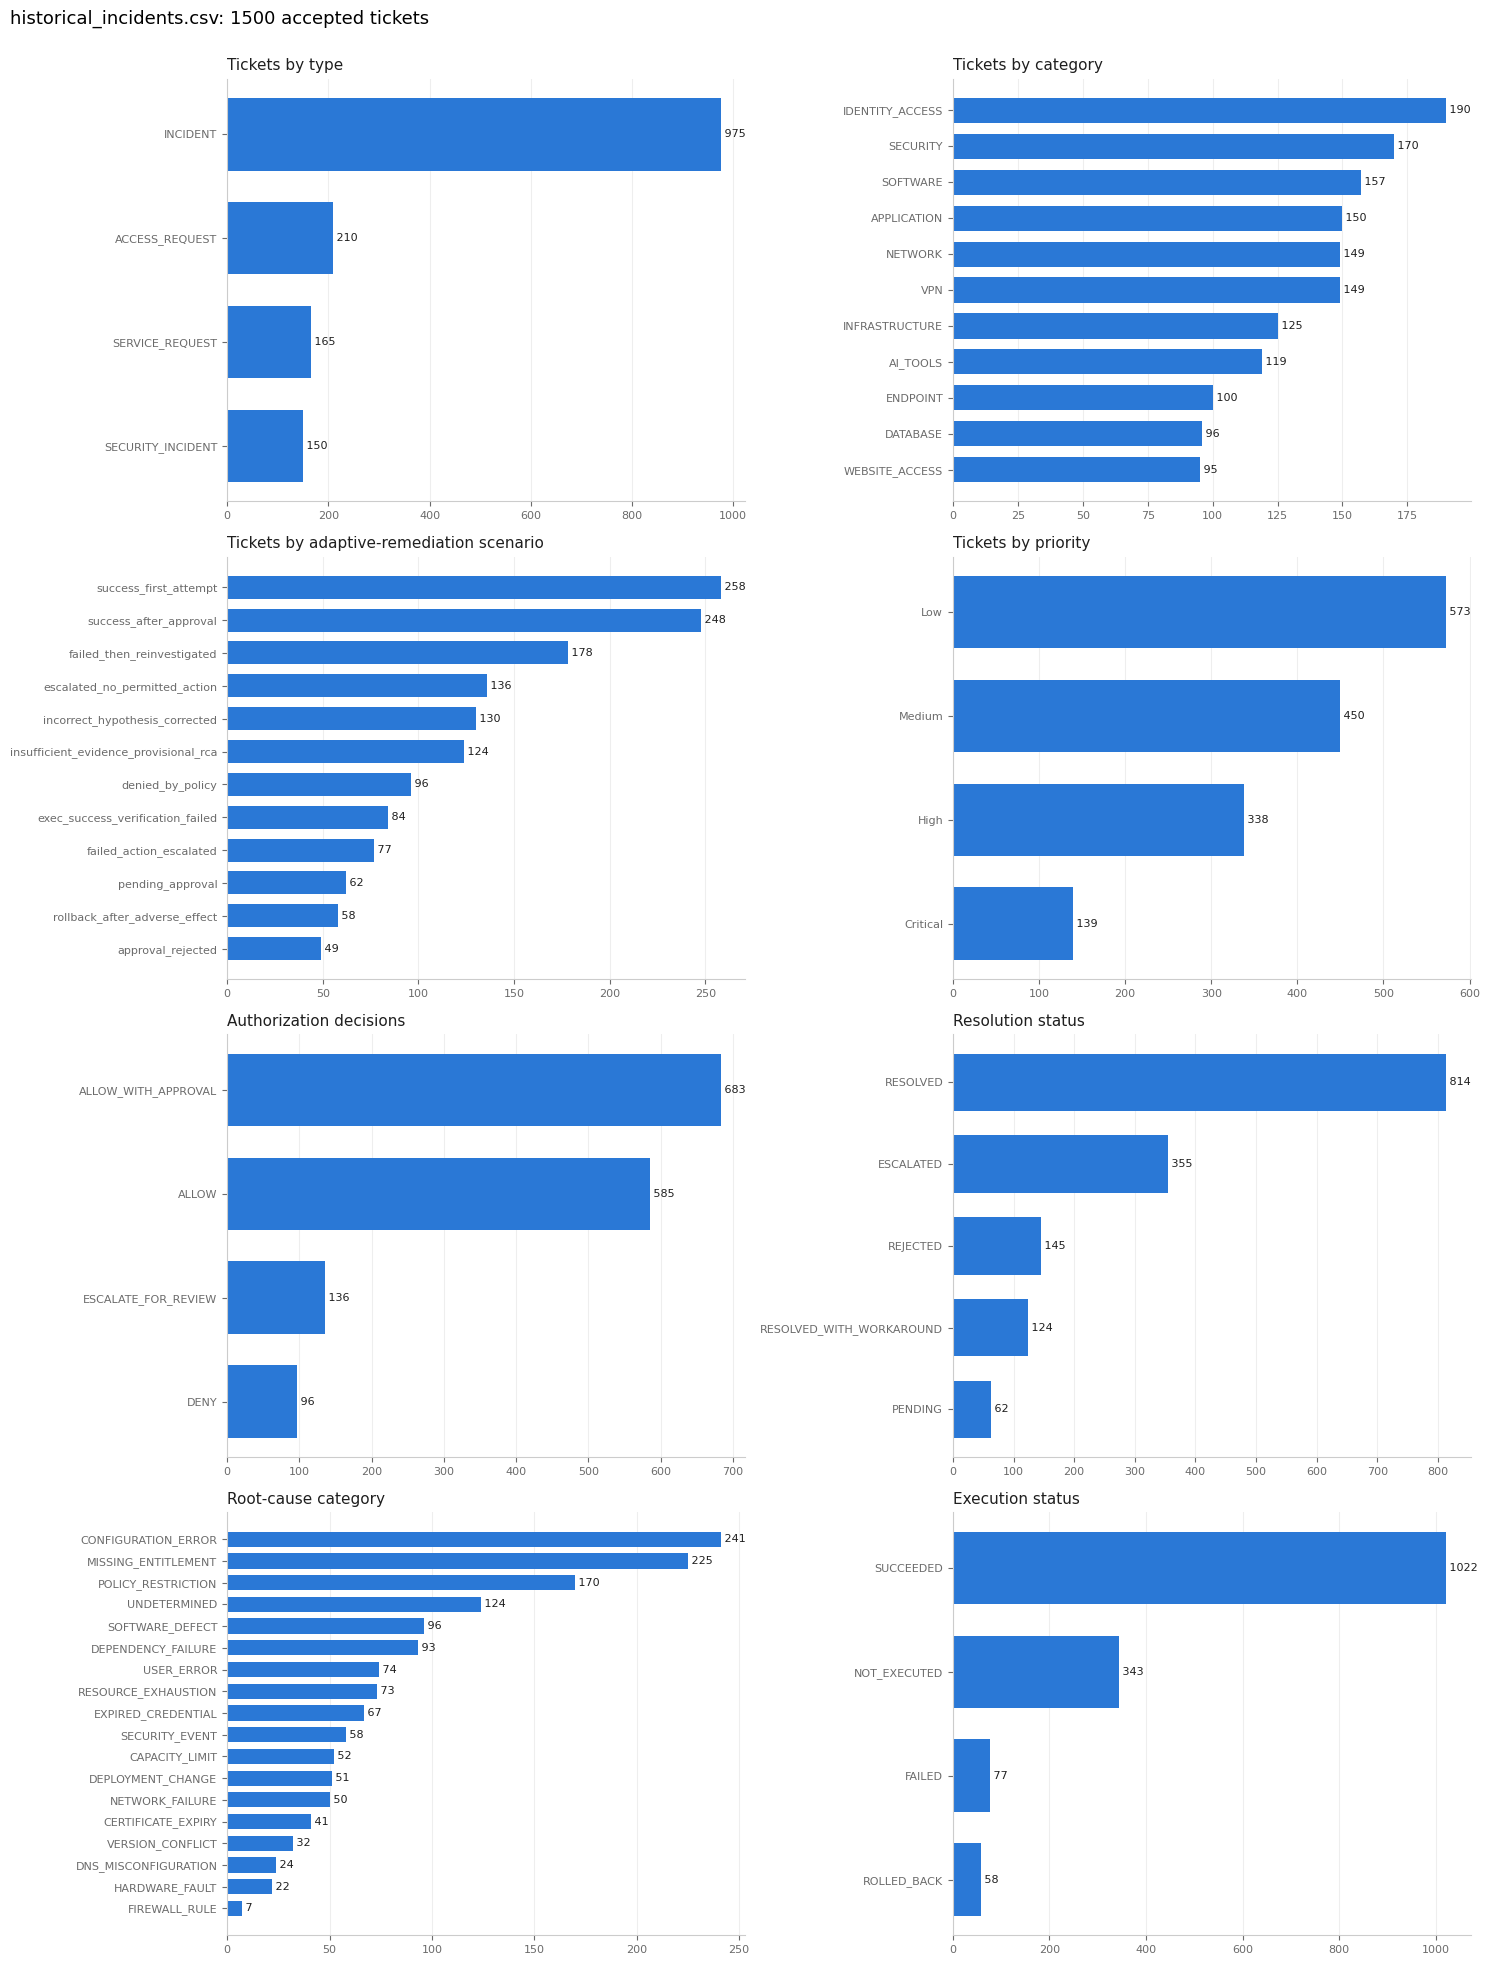

Saved /kaggle/working/itsm_datagen/final/exports/ticket_distributions.png


ticket_type,ACCESS_REQUEST,INCIDENT,SECURITY_INCIDENT,SERVICE_REQUEST,All
category,,,,,
AI_TOOLS,69,50,0,0,119
APPLICATION,0,150,0,0,150
DATABASE,0,75,0,21,96
ENDPOINT,0,100,0,0,100
IDENTITY_ACCESS,69,100,0,21,190
INFRASTRUCTURE,0,125,0,0,125
NETWORK,24,125,0,0,149
SECURITY,0,0,150,20,170
SOFTWARE,0,75,0,82,157


resolution_status,ESCALATED,PENDING,REJECTED,RESOLVED,RESOLVED_WITH_WORKAROUND
scenario_type,,,,,
approval_rejected,0,0,49,0,0
denied_by_policy,0,0,96,0,0
escalated_no_permitted_action,136,0,0,0,0
exec_success_verification_failed,84,0,0,0,0
failed_action_escalated,77,0,0,0,0
failed_then_reinvestigated,0,0,0,178,0
incorrect_hypothesis_corrected,0,0,0,130,0
insufficient_evidence_provisional_rca,0,0,0,0,124
pending_approval,0,62,0,0,0


,policies
default_decision,
ALLOW_WITH_APPROVAL,30
ALLOW,26
DENY,4


,SOPs
risk_level,
MEDIUM,22
HIGH,22
LOW,13
CRITICAL,3


In [27]:
# Cell 40 — Summary charts (one measure per chart, single hue, recessive axes)
import matplotlib.pyplot as plt

_, _, _, f_s, f_p, f_t = to_frames(FINAL_CFG)
BAR_COLOR, INK, MUTED = "#2a78d6", "#1f1f1f", "#6b6b6b"

def hbar(ax, series, title):
    s = series.value_counts().sort_values()
    ax.barh(s.index.astype(str), s.values, color=BAR_COLOR, height=0.7)
    for y, v in enumerate(s.values):
        ax.text(v, y, f" {v}", va="center", fontsize=8, color=INK)
    ax.set_title(title, loc="left", fontsize=11, color=INK)
    ax.tick_params(axis="both", labelsize=8, colors=MUTED)
    for sp in ["top", "right"]:
        ax.spines[sp].set_visible(False)
    ax.spines["left"].set_color("#cccccc"); ax.spines["bottom"].set_color("#cccccc")
    ax.xaxis.grid(True, color="#eeeeee"); ax.set_axisbelow(True)

if len(f_t):
    panels = [("ticket_type", "Tickets by type"), ("category", "Tickets by category"),
              ("scenario_type", "Tickets by adaptive-remediation scenario"), ("priority", "Tickets by priority"),
              ("authorization_decision", "Authorization decisions"), ("resolution_status", "Resolution status"),
              ("root_cause_category", "Root-cause category"), ("execution_status", "Execution status")]
    fig, axes = plt.subplots(4, 2, figsize=(15, 20))
    for ax, (col, title) in zip(axes.flat, panels):
        hbar(ax, f_t[col], title)
    fig.suptitle(f"historical_incidents.csv: {len(f_t)} accepted tickets", fontsize=13, x=0.01, ha="left")
    fig.tight_layout(rect=[0, 0, 1, 0.98])
    chart_path = FINAL_CFG.out_dir / "exports" / "ticket_distributions.png"
    fig.savefig(chart_path, dpi=110)
    plt.show()
    print("Saved", chart_path)
    display(pd.crosstab(f_t["category"], f_t["ticket_type"], margins=True))
    display(pd.crosstab(f_t["scenario_type"], f_t["resolution_status"]))
    display(f_p["default_decision"].value_counts().to_frame("policies"))
    display(f_s["risk_level"].value_counts().to_frame("SOPs"))
else:
    print("No final tickets yet; run Cell 38 first.")

## RAG preparation (auxiliary files, not datasets)

`prepare_rag_corpus()` writes **auxiliary JSONL files** to `final/rag_aux/`. They are text views of the same three datasets, with IDs and retrieval metadata kept in separate fields:

| File | Use |
|---|---|
| `tickets_documents.jsonl` | Past-case knowledge for the Retrieval Agent: title, description, symptoms, observed state, diagnostic data, investigation steps, root cause, resolution plan, actions taken, and resolution summary |
| `tickets_queries.jsonl` | **Query-time view** for evaluation: only what is known when a ticket arrives (title, description, symptoms, observed state, diagnostic data). It contains **no** root cause, actions, decision, or outcome, so expected answers cannot leak into retrieval queries. |
| `sops_documents.jsonl` | SOP title, trigger, symptoms, prerequisites, diagnostic steps, decision condition, recommended action, verification, and failure/escalation conditions |
| `policies_documents.jsonl` | Policy name, condition, category and service, allowed/restricted/prohibited actions, roles, risk, approval, and security constraints |

When you evaluate on a held-out ticket, exclude that ticket's own document from the index.

In [28]:
# Cell 42 — RAG preprocessing (auxiliary JSONL views; IDs and metadata kept separate from text)

def _join(parts):
    return "\n".join(f"{label}: {val}" for label, val in parts if val not in (None, "") and not (isinstance(val, float) and math.isnan(val)))

def ticket_document_text(r):
    return _join([("Title", r["title"]), ("Description", r["description"]), ("Symptoms", r["symptoms"]),
                  ("Observed state", r["observed_state"]), ("Diagnostic data", r["diagnostic_data"]),
                  ("Investigation steps", r["investigation_steps"]), ("Root cause", r["root_cause"]),
                  ("Resolution plan", r["resolution_plan"]), ("Actions taken", r["actions_taken"]),
                  ("Resolution summary", r["resolution_summary"])])

def ticket_query_text(r):          # query-time evidence only: no RCA, actions, decision or outcome
    return _join([("Title", r["title"]), ("Description", r["description"]), ("Symptoms", r["symptoms"]),
                  ("Observed state", r["observed_state"]), ("Diagnostic data", r["diagnostic_data"])])

def sop_document_text(s):
    return _join([("SOP", s["sop_title"]), ("Trigger", s["trigger_condition"]), ("Symptoms", s["symptoms"]),
                  ("Prerequisites", s["prerequisites"]), ("Diagnostic steps", s["diagnostic_steps"]),
                  ("Decision condition", s["decision_condition"]), ("Recommended action", s["recommended_action"]),
                  ("Verification steps", s["verification_steps"]), ("Failure condition", s["failure_condition"]),
                  ("Escalation condition", s["escalation_condition"])])

def policy_document_text(p):
    return _join([("Policy", p["policy_name"]), ("Condition", p["condition"]),
                  ("Applies to", f"{p['category']} / {p['subcategory']} / {p['service']}"),
                  ("Allowed", p["allowed_action"]), ("Restricted", p["restricted_action"]),
                  ("Prohibited", p["prohibited_action"]), ("Eligible roles", p["user_role"]),
                  ("Executor role", p["required_executor_role"]), ("Risk level", p["risk_level"]),
                  ("Approval", f"required by {p['approver_role']}" if p["approval_required"] else "not required"),
                  ("Security constraint", p["security_constraint"])])

def prepare_rag_corpus(cfg):
    _, _, _, df_s, df_p, df_t = to_frames(cfg)
    out = cfg.out_dir / "rag_aux"
    out.mkdir(exist_ok=True)
    def dump(name, rows):
        with open(out / name, "w", encoding="utf-8") as f:
            for row in rows:
                f.write(json.dumps(row, ensure_ascii=False, default=str) + "\n")
    t_meta = ["ticket_type", "category", "subcategory", "service", "environment", "priority", "sop_id", "policy_id"]
    dump("tickets_documents.jsonl", [{"id": r["incident_id"], "metadata": {k: r[k] for k in t_meta},
                                      "text": ticket_document_text(r)} for r in df_t.to_dict("records")])
    dump("tickets_queries.jsonl", [{"id": r["incident_id"],
                                    "metadata": {k: r[k] for k in ["ticket_type", "category", "service", "environment"]},
                                    "text": ticket_query_text(r)} for r in df_t.to_dict("records")])
    dump("sops_documents.jsonl", [{"id": s["sop_id"], "metadata": {k: s[k] for k in ["ticket_type", "category", "subcategory", "service", "action_type", "risk_level"]},
                                   "text": sop_document_text(s)} for s in df_s.to_dict("records")])
    dump("policies_documents.jsonl", [{"id": p["policy_id"], "metadata": {k: p[k] for k in ["sop_id", "ticket_type", "category", "subcategory", "service", "default_decision", "risk_level"]},
                                       "text": policy_document_text(p)} for p in df_p.to_dict("records")])
    # leakage self-check: no query text may contain the ticket's root cause
    leaks = sum(1 for r in df_t.to_dict("records")
                if r["root_cause"] and re.sub(r"^provisional:\s*", "", r["root_cause"], flags=re.I).lower() in ticket_query_text(r).lower())
    print(f"RAG auxiliary files written to {out} | query/root-cause leaks: {leaks}")
    return out

rag_dir = prepare_rag_corpus(FINAL_CFG)
print(open(rag_dir / "tickets_queries.jsonl", encoding="utf-8").readline()[:600])

RAG auxiliary files written to /kaggle/working/itsm_datagen/final/rag_aux | query/root-cause leaks: 10
{"id": "INC0000001", "metadata": {"ticket_type": "SECURITY_INCIDENT", "category": "SECURITY", "service": "Data Loss Prevention", "environment": "CORPORATE_IT"}, "text": "Title: External sharing link DLP violation on document library 086\nDescription: Contractor user1785 shared sensitive engineering documents externally via an unauthorized link on library 086. Data Loss Prevention system flagged the violation.\nSymptoms: Error message: 'Unauthorized external sharing detected.'\nObserved state: Library 086: Link sharing disabled, access revoked for user1785.\nDiagnostic data: 2025-05-02 14:37:28


In [29]:
# Cell 43 — Data dictionary, CSV export, and final ZIP (only after PASS)

def build_data_dictionary(path):
    L = ["# Data dictionary: Enterprise ITSM synthetic datasets", "",
         f"All records are **synthetic**, generated locally with `{MODEL_ID}` on a Kaggle GPU (inference only) "
         f"for the fictional organization \"{ORG_NAME}\". Structured fields, IDs, links and outcomes were assigned "
         "deterministically in Python; text fields were written by the model and validated by deterministic rules.", "",
         "Datasets: `historical_incidents.csv` (1,500 rows), `incident_sops.csv` (60), `incident_policies.csv` (60).",
         "Links: tickets.sop_id -> sops.sop_id; tickets.policy_id -> policies.policy_id; policies.sop_id -> sops.sop_id (1:1).", ""]
    enum_lookup = {**{c: e for c, e in TICKET_ENUM_COLUMNS.items()}}
    for title, cols, docs, enums in [("historical_incidents.csv", TICKET_COLUMNS, TICKET_DOCS, TICKET_ENUM_COLUMNS),
                                     ("incident_sops.csv", SOP_COLUMNS, SOP_DOCS, SOP_ENUM_COLUMNS),
                                     ("incident_policies.csv", POLICY_COLUMNS, POLICY_DOCS, POLICY_ENUM_COLUMNS)]:
        L += [f"## {title}", "", "| # | Column | Description | Allowed values |", "|---|---|---|---|"]
        for i, c in enumerate(cols, 1):
            allowed = ", ".join(ENUMS[enums[c]]) if c in enums else ("True / False" if c in
                      ("approval_required", "escalation_required", "rollback_required", "audit_required") else "")
            L.append(f"| {i} | `{c}` | {docs[c]} | {allowed} |")
        L.append("")
    L += ["## Scenario semantics (historical_incidents.scenario_type)", "",
          "| Scenario | Authorization | Approval | Execution | Initial verif. | Final verif. | Resolution | Ticket status | Escalated | Iterations |",
          "|---|---|---|---|---|---|---|---|---|---|"]
    for s, sp in SCENARIOS.items():
        L.append(f"| {s} | {sp['auth'] if sp['auth'] != 'STANCE' else 'policy default'} | "
                 f"{sp['approval'] or 'NOT_APPLICABLE'} (NOT_REQUIRED under ALLOW policies) | {sp['exec']} | {sp['iv']} | "
                 f"{sp['fv']} | {sp['res']} | {sp['ts']} | {sp['esc']} | {sp['iters']} |")
    L += ["", "## Schema changes relative to the original specification", "",
          "- Removed `verification_result` (duplicate of `final_verification_result`).",
          "- Removed `is_synthetic` (constant True; provenance is stated in this dictionary).",
          "- Added `incident_policies.default_decision` (machine-readable ALLOW / ALLOW_WITH_APPROVAL / DENY)."]
    Path(path).write_text("\n".join(L), encoding="utf-8")

def export_datasets(cfg, report):
    exp = cfg.out_dir / "exports"
    if report["status"] != "PASS":
        raise RuntimeError("Validation did not PASS; CSVs are not exported. See validation_report.md.")
    _, _, _, df_s, df_p, df_t = to_frames(cfg)
    for col in TICKET_INT_COLUMNS:
        df_t[col] = df_t[col].astype("Int64")
    for col in TICKET_BOOL_COLUMNS:
        df_t[col] = df_t[col].astype(bool)
    df_t = df_t.sort_values("incident_id").reset_index(drop=True)
    paths = {"historical_incidents.csv": df_t, "incident_sops.csv": df_s.sort_values("sop_id"),
             "incident_policies.csv": df_p.sort_values("policy_id")}
    for name, df in paths.items():
        df.to_csv(exp / name, index=False, encoding="utf-8")
    build_data_dictionary(exp / "data_dictionary.md")
    # re-read check: exact row counts and columns after the CSV round-trip
    rt_t, rt_s, rt_p = (pd.read_csv(exp / n) for n in paths)
    assert len(rt_t) == cfg.n_tickets and list(rt_t.columns) == TICKET_COLUMNS
    assert len(rt_s) == cfg.n_sops and list(rt_s.columns) == SOP_COLUMNS
    assert len(rt_p) == cfg.n_policies and list(rt_p.columns) == POLICY_COLUMNS
    shutil.copy2(cfg.out_dir / "generation.log", exp / "generation.log") if (cfg.out_dir / "generation.log").exists() else None
    zpath = cfg.out_dir / f"itsm_datasets_{cfg.name}.zip"
    with zipfile.ZipFile(zpath, "w", zipfile.ZIP_DEFLATED) as z:
        for n in list(paths) + ["data_dictionary.md", "validation_report.md", "validation_report.json"]:
            z.write(exp / n, arcname=n)
    print(f"Exported: {[str(exp / n) for n in paths]}")
    print(f"Round-trip check OK: tickets={len(rt_t)}, sops={len(rt_s)}, policies={len(rt_p)}")
    print("ZIP:", zpath, f"({zpath.stat().st_size / 1e6:.2f} MB)")
    return zpath

final_report = final_validate(FINAL_CFG, verbose=False)
print("Final validation status:", final_report["status"])
if final_report["status"] == "PASS":
    FINAL_ZIP = export_datasets(FINAL_CFG, final_report)
else:
    print("Not complete yet: CSVs not exported. Resume from checkpoints in the next version.")
CKPT_ZIP = make_checkpoint_zip(FINAL_CFG)
print("Checkpoint archive:", CKPT_ZIP)

Final validation status: PASS
Exported: ['/kaggle/working/itsm_datagen/final/exports/historical_incidents.csv', '/kaggle/working/itsm_datagen/final/exports/incident_sops.csv', '/kaggle/working/itsm_datagen/final/exports/incident_policies.csv']
Round-trip check OK: tickets=1500, sops=60, policies=60
ZIP: /kaggle/working/itsm_datagen/final/itsm_datasets_final.zip (0.87 MB)
Checkpoint archive: /kaggle/working/itsm_datagen/final/final_checkpoints.zip


In [30]:
# Cell 44 — Download links and file inventory
from IPython.display import FileLink, display

exp = FINAL_CFG.out_dir / "exports"
for f in ["historical_incidents.csv", "incident_sops.csv", "incident_policies.csv", "data_dictionary.md",
          "validation_report.md", "validation_report.json", "ticket_distributions.png", "generation.log"]:
    p = exp / f
    if p.exists():
        print(f"{f:<28} {p.stat().st_size/1e6:8.2f} MB")
        display(FileLink(str(p.relative_to(Path.cwd())) if str(p).startswith(str(Path.cwd())) else str(p)))
for z in [FINAL_CFG.out_dir / "itsm_datasets_final.zip", FINAL_CFG.out_dir / "final_checkpoints.zip"]:
    if z.exists():
        print(f"{z.name:<28} {z.stat().st_size/1e6:8.2f} MB")
        display(FileLink(str(z.relative_to(Path.cwd())) if str(z).startswith(str(Path.cwd())) else str(z)))
print("\nAlternatively: right panel -> Output (/kaggle/working/itsm_datagen/final/) -> click the file -> Download, "
      "or after 'Save Version', open the version's Output tab and use 'Download All'.")

historical_incidents.csv         3.37 MB


/kaggle/working/itsm_datagen/final/exports/historical_incidents.csv

incident_sops.csv                0.09 MB


/kaggle/working/itsm_datagen/final/exports/incident_sops.csv

incident_policies.csv            0.06 MB


/kaggle/working/itsm_datagen/final/exports/incident_policies.csv

... (11 outputs left out)

/kaggle/working/itsm_datagen/final/itsm_datasets_final.zip

final_checkpoints.zip            1.43 MB


/kaggle/working/itsm_datagen/final/final_checkpoints.zip


Alternatively: right panel -> Output (/kaggle/working/itsm_datagen/final/) -> click the file -> Download, or after 'Save Version', open the version's Output tab and use 'Download All'.


## How the three datasets feed the agents in the framework

| Agent | What it uses |
|---|---|
| **Understanding** | Ticket `title`, `description`, `symptoms` → labels `ticket_type`, `category`, `subcategory`, `service`, `impact`, `urgency`, `priority`, plus request fields (resource, application, domain, AI tool, duration, scope) |
| **Retrieval** | `rag_aux/*_documents.jsonl` over past tickets, SOPs, and policies; `tickets_queries.jsonl` provides leakage-free queries; `sop_id` / `policy_id` are relevance ground truth |
| **Investigation** | `telemetry_type`, `diagnostic_data`, `observed_state`, `investigation_steps`, SOP `diagnostic_steps`; `new_evidence` and `reinvestigation_trigger` model iterative evidence gathering |
| **RCA** | `initial_hypothesis` vs final `root_cause` / `root_cause_category`; `incorrect_hypothesis_corrected` and `insufficient_evidence_provisional_rca` (`UNDETERMINED` + "Provisional:") test hypothesis revision and calibrated uncertainty |
| **Resolution Planning** | SOP `recommended_action`, `decision_condition`, `rollback_action` → ticket `resolution_plan`, `action_type`, `updated_resolution_plan` |
| **Policy & Risk** | Policy `default_decision`, `user_role` eligibility, `risk_level`, `approval_required`, `approver_role`, prohibited actions → ticket `authorization_decision`, `authorization_reason`, `approval_status` (gold labels for ALLOW / ALLOW_WITH_APPROVAL / DENY / ESCALATE_FOR_REVIEW) |
| **Execution** | `executor_role`, `execution_status`, `initial_action(_result)`, `final_action(_result)`, `ROLLED_BACK` cases for safe rollback |
| **Verification** | SOP `verification_steps`, ticket `verification_method`, `initial_verification_result` / `final_verification_result`; scenarios where execution succeeds but verification fails, which must not be closed |
| **Communication** | `resolution_summary`, `escalation_reason`, `ticket_status`, `resolution_status` |

**Evaluation tip:** stratify train/test splits by `scenario_type` and `category`. Use `scenario_type` to measure policy compliance, escalation appropriateness, and verification-loop behaviour separately.